In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import pandas as pd
from torch.utils.data import Dataset
import torch.nn.init as init
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np
import os
import random
from PIL import Image
from torchvision import models, transforms, utils
from torchvision.transforms import v2
import re

In [ ]:
###Función para mostrar la curva de aprendizaje (con la pérdida) de un modelo

def learning_curve(train_loss, val_loss):
    epochs = range(1, len(train_loss) + 1)

    plt.plot(epochs, np.array(train_loss), label='Training Loss')
    plt.plot(epochs, np.array(val_loss), label='Validation Loss')

    plt.title('Learning Curve')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.ylim(0, 1)
    plt.legend()
    plt.show()

In [ ]:
# Verificar si CUDA está disponible
cuda_available = torch.cuda.is_available()

# Imprimir la versión de PyTorch y la disponibilidad de CUDA
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {cuda_available}")

# Imprimir el nombre de la GPU si CUDA está disponible
if cuda_available:
    print(f"GPU name: {torch.cuda.get_device_name(0)}")
    # Obtener la versión de CUDA
    cuda_version = torch.version.cuda
    print(f"CUDA version: {cuda_version}")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

PyTorch version: 2.2.0
CUDA available: True
GPU name: NVIDIA GeForce RTX 3050 Laptop GPU
CUDA version: 12.1
Using device: cuda


In [ ]:
####CREACION DATASET

import os
import pandas as pd

# Directorio que contiene los archivos
directorio = './IMGS_MOSAIC'

# Obtener la lista de archivos en el directorio
archivos = os.listdir(directorio)

# Crear una lista para almacenar las rutas de los archivos y las etiquetas
data = []

# Iterar sobre los archivos
for archivo in archivos:
    # Obtener la ruta completa del archivo
    ruta_completa = os.path.join(directorio, archivo)
    # Obtener los elementos después de hacer split("_")
    elementos = archivo.split("_")
    # Obtener la etiqueta (cuarto elemento)
    etiqueta = elementos[3] if len(elementos) >= 4 else None
    # Agregar la ruta y la etiqueta a la lista de datos
    data.append((ruta_completa, int(etiqueta)))

# Crear el DataFrame de Pandas
df_mosaic = pd.DataFrame(data, columns=['Ruta', 'Etiqueta'])

# Mostrar el DataFrame
print(df_mosaic)

                             Ruta  Etiqueta
0   ./IMGS_MOSAIC\_P02_HVN_1_.jpg         1
1   ./IMGS_MOSAIC\_P08_HVN_1_.jpg         1
2   ./IMGS_MOSAIC\_P10_HVN_1_.jpg         1
3   ./IMGS_MOSAIC\_P12_HVN_0_.jpg         0
4   ./IMGS_MOSAIC\_P15_HVN_0_.jpg         0
5   ./IMGS_MOSAIC\_P17_HVN_0_.jpg         0
6   ./IMGS_MOSAIC\_P19_HVN_0_.jpg         0
7   ./IMGS_MOSAIC\_P20_HVN_0_.jpg         0
8   ./IMGS_MOSAIC\_P21_HVN_1_.jpg         1
9   ./IMGS_MOSAIC\_P22_HVN_1_.jpg         1
10  ./IMGS_MOSAIC\_P24_HVN_1_.jpg         1
11  ./IMGS_MOSAIC\_P25_HVN_0_.jpg         0
12  ./IMGS_MOSAIC\_P26_HVN_0_.jpg         0
13  ./IMGS_MOSAIC\_P27_HVN_1_.jpg         1
14  ./IMGS_MOSAIC\_P34_HVN_0_.jpg         0
15  ./IMGS_MOSAIC\_P47_HVN_0_.jpg         0
16  ./IMGS_MOSAIC\_P48_HVN_0_.jpg         0
17  ./IMGS_MOSAIC\_P50_H9O_1_.jpg         1
18  ./IMGS_MOSAIC\_P51_H9O_0_.jpg         0
19  ./IMGS_MOSAIC\_P52_H9O_1_.jpg         1
20  ./IMGS_MOSAIC\_P53_H9O_0_.jpg         0
21  ./IMGS_MOSAIC\_P54_H9O_1_.jp

In [ ]:


# Directorio que contiene los archivos
directorio = './IMGS_MEDIA'

# Obtener la lista de archivos en el directorio
archivos = os.listdir(directorio)

# Crear una lista para almacenar las rutas de los archivos y las etiquetas
data = []

# Iterar sobre los archivos
for archivo in archivos:
    # Obtener la ruta completa del archivo
    ruta_completa = os.path.join(directorio, archivo)
    # Obtener los elementos después de hacer split("_")
    elementos = archivo.split("_")
    # Obtener la etiqueta (cuarto elemento)
    etiqueta = elementos[3] if len(elementos) >= 4 else None
    # Agregar la ruta y la etiqueta a la lista de datos
    data.append((ruta_completa, int(etiqueta)))

# Crear el DataFrame de Pandas
df_mean = pd.DataFrame(data, columns=['Ruta', 'Etiqueta'])

# Mostrar el DataFrame
print(df_mean)

                            Ruta  Etiqueta
0   ./IMGS_MEDIA\_P02_HVN_1_.jpg         1
1   ./IMGS_MEDIA\_P08_HVN_1_.jpg         1
2   ./IMGS_MEDIA\_P10_HVN_1_.jpg         1
3   ./IMGS_MEDIA\_P12_HVN_0_.jpg         0
4   ./IMGS_MEDIA\_P15_HVN_0_.jpg         0
5   ./IMGS_MEDIA\_P17_HVN_0_.jpg         0
6   ./IMGS_MEDIA\_P19_HVN_0_.jpg         0
7   ./IMGS_MEDIA\_P20_HVN_0_.jpg         0
8   ./IMGS_MEDIA\_P21_HVN_1_.jpg         1
9   ./IMGS_MEDIA\_P22_HVN_1_.jpg         1
10  ./IMGS_MEDIA\_P24_HVN_1_.jpg         1
11  ./IMGS_MEDIA\_P25_HVN_0_.jpg         0
12  ./IMGS_MEDIA\_P26_HVN_0_.jpg         0
13  ./IMGS_MEDIA\_P27_HVN_1_.jpg         1
14  ./IMGS_MEDIA\_P34_HVN_0_.jpg         0
15  ./IMGS_MEDIA\_P47_HVN_0_.jpg         0
16  ./IMGS_MEDIA\_P48_HVN_0_.jpg         0
17  ./IMGS_MEDIA\_P50_H9O_1_.jpg         1
18  ./IMGS_MEDIA\_P51_H9O_0_.jpg         0
19  ./IMGS_MEDIA\_P52_H9O_1_.jpg         1
20  ./IMGS_MEDIA\_P53_H9O_0_.jpg         0
21  ./IMGS_MEDIA\_P54_H9O_1_.jpg         1
22  ./IMGS_

In [ ]:
import os
import pandas as pd

# Directorio que contiene los archivos
directorio = './IMGS_MOSAIC'

# Obtener la lista de archivos en el directorio
archivos = os.listdir(directorio)

# Crear una lista para almacenar las rutas de los archivos y las etiquetas
data = []

# Iterar sobre los archivos
for archivo in archivos:
    # Obtener la ruta completa del archivo
    ruta_completa = os.path.join(directorio, archivo)
    # Obtener los elementos después de hacer split("_")
    elementos = archivo.split("_")
    # Obtener la etiqueta (cuarto elemento)
    etiqueta = elementos[3] if len(elementos) >= 4 else None
    # Agregar la ruta y la etiqueta a la lista de datos
    data.append((ruta_completa, int(etiqueta)))

# Crear el DataFrame de Pandas
df_mosaic = pd.DataFrame(data, columns=['Ruta', 'Etiqueta'])



## PRUEBAS CON GRID SEARCH

A continuación se presentan una serie de funciones donde se encapsula todo el entrenamiento de un modelo, para 4 formas diferentes de entrenar. Se comentará exhaustivamente esta primera función. Las demás para las distitnas formas de entrenar son similares, cambiando algunas cosas que se comentarán en el código. Lo recomendable, para entender la función, sería leer la primera y compararla con las demás. Además, en cuanto a los parámetros de la función, cuando se entrena con TL, hay un parámetro más ya que se indican dos número de épocas, una para el modelo congelado y otra para el modelo sin congelar.

### SIN TL NI OC

In [ ]:
# Función para calcular el accuracy
def accuracy(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, se considera una predicción positiva (1), de lo contrario es negativa (0)
    correct = (preds == labels.byte())  # Compara las predicciones con las etiquetas reales para ver cuántas son correctas
    acc = correct.float().sum() / labels.size(0)  # Suma las predicciones correctas y divide por el número total de etiquetas para obtener la precisión
    return acc.item()  # Devuelve la precisión como un valor escalar

# Función para calcular el recall
def recall(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, se considera una predicción positiva (1), de lo contrario es negativa (0)

    # Mueve los tensores a la CPU para asegurar la compatibilidad en operaciones subsecuentes
    preds = preds.cpu()
    labels = labels.cpu()

    TP = sum((preds == 1) & (labels == 1))  # Calcula los verdaderos positivos (TP): predicciones positivas que son correctas
    FN = sum((preds == 0) & (labels == 1))  # Calcula los falsos negativos (FN): etiquetas reales positivas que fueron predichas como negativas

    recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0  # Calcula el recall: TP dividido por la suma de TP y FN. Si TP + FN es 0, el recall es 0
    return recall_score  # Devuelve el valor del recall

# Función para calcular la precisión (precision)
def precision(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, se considera una predicción positiva (1), de lo contrario es negativa (0)

    # Mueve los tensores a la CPU para asegurar la compatibilidad en operaciones subsecuentes
    preds = preds.cpu()
    labels = labels.cpu()

    TP = sum((preds == 1) & (labels == 1))  # Calcula los verdaderos positivos (TP): predicciones positivas que son correctas
    FP = sum((preds == 1) & (labels == 0))  # Calcula los falsos positivos (FP): predicciones positivas que son incorrectas

    precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0  # Calcula la precisión: TP dividido por la suma de TP y FP. Si TP + FP es 0, la precisión es 0
    return precision_score  # Devuelve el valor de la precisión

#####Parámetros
#####   dataset: el conjunto de datos, siendo una columna la ruta y otra la etiqueta de la imagen
#####   num_folds_outer: el número de folds de test que se ejecutarán
#####   num_epochs: el número total de épocas que se entrenará
#####   op: el optimziador usado
#####   batch_size: tamaño de batch para entrenamiento
#####   lr: learning rate para el optimizador
#####   data_aug: True o False, para si se hace aumento de datos o no
#####   ini: un char representnado uno de los optimizadores que se pueden usar

def prueba_k_fold_resnet_no_pre(dataset, num_folds, num_epochs, op, batch_size, lr, data_aug, ini):
    # Transformaciones para preprocesar las imágenes
    # Verifica si el aumento de datos está activado
    if data_aug:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),  # Redimensiona la imagen a 224x224 píxeles
            v2.RandomHorizontalFlip(),  # Aplica un volteo horizontal aleatorio a la imagen
            v2.RandomVerticalFlip(),  # Aplica un volteo vertical aleatorio a la imagen
            v2.ToImage(),  # Convierte los datos en una imagen
            v2.ToDtype(torch.float32, scale=True),  # Convierte la imagen al tipo de datos float32, escalando los valores
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),  # Normaliza la imagen usando los valores de media y desviación estándar de ImageNet
        ])

        # Transformaciones para los datos de validación (sin aumento de datos)
        transform_v = v2.Compose([
            v2.Resize((224, 224)),  # Redimensiona la imagen a 224x224 píxeles
            v2.ToImage(),  # Convierte los datos en una imagen
            v2.ToDtype(torch.float32, scale=True),  # Convierte la imagen al tipo de datos float32, escalando los valores
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),  # Normaliza la imagen usando los valores de media y desviación estándar de ImageNet
        ])
    else:
        # Transformaciones para los datos de entrenamiento sin aumento de datos
        transform_t = v2.Compose([
            v2.Resize((224, 224)),  # Redimensiona la imagen a 224x224 píxeles
            v2.ToImage(),  # Convierte los datos en una imagen
            v2.ToDtype(torch.float32, scale=True),  # Convierte la imagen al tipo de datos float32, escalando los valores
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),  # Normaliza la imagen usando los valores de media y desviación estándar de ImageNet
        ])

        # Transformaciones para los datos de validación (sin aumento de datos)
        transform_v = v2.Compose([
            v2.Resize((224, 224)),  # Redimensiona la imagen a 224x224 píxeles
            v2.ToImage(),  # Convierte los datos en una imagen
            v2.ToDtype(torch.float32, scale=True),  # Convierte la imagen al tipo de datos float32, escalando los valores
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),  # Normaliza la imagen usando los valores de media y desviación estándar de ImageNet
        ])
    
    # Modelo personalizado basado en ResNet
    class CustomResNet(nn.Module):
        def __init__(self, num_classes_binary=1):
            super(CustomResNet, self).__init__()

            # Carga el modelo sin pesos de entrenamiento
            resnet = models.resnet18(weights=None)

            # Extrae todas las capas de la ResNet menos la última capa fully connected
            self.features = nn.Sequential(*list(resnet.children())[:-1])
    
            # Define una nueva capa fully connected para la clasificación binaria
            self.fc_binary = nn.Linear(512, num_classes_binary)
            
            # Inicializa los pesos de la red según el método especificado
            if (ini == "G"):
                self.apply(self.init_weights_glorot)  # Inicialización de Glorot (Xavier)
            elif(ini == "H"):
                self.apply(self.init_weights_he)  # Inicialización de He
            elif (ini == "N"):
                self.apply(self.init_weights_normal)  # Inicialización normal
            elif(ini == "U"):
                self.apply(self.init_weights_uniform)  # Inicialización uniforme
            elif (ini == "O"):
                self.apply(self.init_weights_orthogonal)  # Inicialización ortogonal
            elif(ini == "Z"):
                self.apply(self.init_weights_zeros)  # Inicialización a ceros
            elif(ini == "ON"):
                self.apply(self.init_weights_ones)  # Inicialización a unos

        # Inicialización de pesos con el método de Glorot (Xavier)
        def init_weights_glorot(self, m):
            if isinstance(m, nn.Linear):
                init.xavier_uniform_(m.weight)  # Inicializa los pesos de forma uniforme según Glorot
                if m.bias is not None:
                    init.constant_(m.bias, 0)  # Inicializa los sesgos a cero
    
        # Inicialización de pesos con el método de He
        def init_weights_he(self, m):
            if isinstance(m, nn.Linear):
                init.kaiming_uniform_(m.weight, mode='fan_in', nonlinearity='relu')  # Inicializa los pesos según He
                if m.bias is not None:
                    init.constant_(m.bias, 0)  # Inicializa los sesgos a cero
    
        # Inicialización de pesos con distribución normal
        def init_weights_normal(self, m):
            if isinstance(m, nn.Linear):
                init.normal_(m.weight, mean=0, std=0.01)  # Inicializa los pesos con una distribución normal con media 0 y desviación estándar 0.01
                if m.bias is not None:
                    init.constant_(m.bias, 0)  # Inicializa los sesgos a cero
    
        # Inicialización de pesos con distribución uniforme
        def init_weights_uniform(self, m):
            if isinstance(m, nn.Linear):
                init.uniform_(m.weight, a=-0.1, b=0.1)  # Inicializa los pesos de forma uniforme entre -0.1 y 0.1
                if m.bias is not None:
                    init.constant_(m.bias, 0)  # Inicializa los sesgos a cero
    
        # Inicialización de pesos ortogonal
        def init_weights_orthogonal(self, m):
            if isinstance(m, nn.Linear):
                init.orthogonal_(m.weight)  # Inicializa los pesos de forma ortogonal
                if m.bias is not None:
                    init.constant_(m.bias, 0)  # Inicializa los sesgos a cero
    
        # Inicialización de pesos a ceros
        def init_weights_zeros(self, m):
            if isinstance(m, nn.Linear):
                init.zeros_(m.weight)  # Inicializa todos los pesos a cero
                if m.bias is not None:
                    init.zeros_(m.bias)  # Inicializa los sesgos a cero
    
        # Inicialización de pesos a unos
        def init_weights_ones(self, m):
            if isinstance(m, nn.Linear):
                init.ones_(m.weight)  # Inicializa todos los pesos a uno
                if m.bias is not None:
                    init.ones_(m.bias)  # Inicializa los sesgos a uno
    
        # Método forward para el paso de la red
        def forward(self, x):
            x = self.features(x)  # Pasa la entrada a través de la parte de características de la red
            x = x.view(x.size(0), -1)  # Aplana las características a un vector de 1D para la capa fully connected
    
            # Pasa la salida a través de la capa fully connected personalizada para la clasificación binaria
            out_binary = self.fc_binary(x)
    
            return out_binary  # Devuelve la salida para la clasificación binaria
    
    # Define una clase personalizada para el conjunto de datos
    class CustomDataset(Dataset):
        def __init__(self, dataframe, transform=None):
            """
            Inicializa el conjunto de datos personalizado.

            Args:
                dataframe (pd.DataFrame): DataFrame que contiene rutas a las imágenes y etiquetas.
                transform (callable, optional): Transformaciones que se aplicarán a cada imagen.
            """
            self.data = dataframe  # Almacena el DataFrame con rutas y etiquetas
            self.transform = transform  # Almacena las transformaciones, si se proporcionan
    
        def __len__(self):
            """
            Devuelve la longitud del conjunto de datos.

            Returns:
                int: Número de ejemplos en el conjunto de datos.
            """
            return len(self.data)  # Retorna el número de filas en el DataFrame
    
        def __getitem__(self, idx):
            """
            Obtiene una imagen y su etiqueta correspondiente por índice.

            Args:
                idx (int): Índice del ejemplo a obtener.

            Returns:
                tuple: Una imagen transformada y su etiqueta binaria.
            """
            # Obtiene la ruta de la imagen de la primera columna del DataFrame
            img_path = self.data.iloc[idx, 0]

            # Abre la imagen usando PIL y la convierte a RGB
            image = Image.open(img_path).convert('RGB')

            # Obtiene la etiqueta binaria de la segunda columna del DataFrame y la convierte a tensor
            label_binary = torch.tensor(self.data.iloc[idx, 1], dtype=torch.float32)

            # Aplica las transformaciones a la imagen, si están definidas
            if self.transform:
                image = self.transform(image)

            # Retorna la imagen (posiblemente transformada) y la etiqueta binaria
            return image, label_binary
        
    #####5 fold CV
    from sklearn.model_selection import StratifiedKFold
    
    # Definir el número de folds
    criterion_binary = nn.BCEWithLogitsLoss() # Define el criterio de pérdida para la variable binaria
    kf = StratifiedKFold(n_splits=num_folds, shuffle=True, random_state=33)
    
    # Listas para almacenar las pérdidas de entrenamiento y validación de cada fold y otras métricas
    train_losses_folds = []
    val_losses_folds = []
    
    train_accs_folds = []
    train_rec_folds =  []
    train_preci_folds = []

    val_accs_folds = []
    val_rec_folds =  []
    val_preci_folds = []
    
    # Itera sobre cada fold generado por StratifiedKFold
    for fold, (train_index, val_index) in enumerate(kf.split(np.zeros(len(dataset)),dataset['Etiqueta'])):
        print(f"Fold {fold + 1}")
    
        # Dividir el conjunto de datos en entrenamiento y validación para este fold
        train_data_fold = dataset.iloc[train_index]
        val_data_fold = dataset.iloc[val_index]
    
        # Crear instancias del conjunto de datos personalizado para este fold
        train_dataset_fold = CustomDataset(dataframe=train_data_fold, transform=transform_t)
        val_dataset_fold = CustomDataset(dataframe=val_data_fold, transform=transform_v)
    
        # Crear DataLoader para cargar los datos en lotes
        train_loader_fold = DataLoader(dataset=train_dataset_fold, batch_size=batch_size, shuffle=True)
        val_loader_fold = DataLoader(dataset=val_dataset_fold, batch_size=len(val_dataset_fold), shuffle=False) 
    
        # Re-inicializar el modelo para cada fold
        model = CustomResNet(num_classes_binary=1).to(device)

        ##En este forma de entrenar, solo un optimizador
        optimizer = op(model.parameters(), lr = lr)
        # Entrenamiento y validación para este fold
        train_losses_fold = []
        val_losses_fold = []
        train_accuracy_fold = []
        val_accuracy_fold = []
        train_recall_fold = []
        val_recall_fold = []
        train_preci_fold = []
        val_preci_fold = []

        for epoch in range(num_epochs):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            lossT_bin_total = 0.0
            correct_train = 0
            recall_value_train = 0
            precision_value_train = 0
            for images, bin_label in train_loader_fold:
                
                images, bin_label = images.to(device), bin_label.to(device)
                # Reiniciar gradientes
                optimizer.zero_grad()
        
                # Forward pass
                bin_out = model(images)
        
        
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
        
                # Pérdida total
                loss_total = lossT_bin
    
                loss_total_acumulada += loss_total
    
                # Backward pass y optimización
                loss_total.backward()
                optimizer.step()

                #Calculo de otras métricas
                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_train += accuracy(bin_pred, bin_label)
                recall_value_train += recall(bin_pred, bin_label)
                precision_value_train += precision(bin_pred, bin_label)

        
    
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            correct_valid = 0
            recall_value_valid = 0
            precision_value_valid = 0
            lossV_bin_total = 0.0
            with torch.no_grad():
                for images, bin_label in val_loader_fold:
                    images,  bin_label = images.to(device),  bin_label.to(device)

                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
    
    
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()

                    #Cálculo de otras métricas
                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    correct_valid += accuracy(bin_pred, bin_label)
                    recall_value_valid += recall(bin_pred, bin_label)
                    precision_value_valid += precision(bin_pred, bin_label)
                    
            
            
            ### Se promedian los resultados teniendo en cuenta el número de lotes y se actualizan listas
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold)
            train_losses_fold.append(avg_loss_total_acumulada)
            acc_train = correct_train / len(train_loader_fold)
            recall_train = recall_value_train / len(train_loader_fold)
            precision_train = precision_value_train / len(train_loader_fold)
            train_accuracy_fold.append(acc_train)
            train_recall_fold.append(recall_train)
            train_preci_fold.append(precision_train)
        
            avg_val_loss = val_loss / len(val_loader_fold)
            val_losses_fold.append(avg_val_loss)
            acc_valid = correct_valid / len(val_loader_fold)
            recall_valid = recall_value_valid / len(val_loader_fold)
            precision_valid = precision_value_valid / len(val_loader_fold)
            val_accuracy_fold.append(acc_valid)
            val_recall_fold.append(recall_valid)
            val_preci_fold.append(precision_valid)
            # print(f'Epoch [{epoch+1}/{num_epochs}], Training Loss: {avg_loss_total_acumulada.item()}, Validation Loss: {avg_val_loss}')
        
      
        
        train_accs_folds.append(np.mean(train_accuracy_fold))
        train_rec_folds.append(np.mean(train_recall_fold))
        train_preci_folds.append(np.mean(train_preci_fold))

        val_accs_folds.append(np.mean(val_accuracy_fold))
        val_rec_folds.append(np.mean(val_recall_fold))
        val_preci_folds.append(np.mean(val_preci_fold))

        train_losses_folds.append(train_losses_fold)
        val_losses_folds.append(val_losses_fold)
        train_losses_fold = [i.cpu().detach().numpy() for i in train_losses_fold]
    
    train_losses_folds_cpu = []
    val_losses_folds_cpu = []

    ##Movemos a cpu el contenido de las listas
    for losses in val_losses_folds:
        val_losses_fold_cpu = []
        for loss in losses:
            val_losses_fold_cpu.append(loss)
        val_losses_folds_cpu.append(np.array(val_losses_fold_cpu))

    for losses in train_losses_folds:
        train_losses_fold_cpu = []
        for loss in losses:
            train_losses_fold_cpu.append(float(loss.cpu().detach().numpy()))
        train_losses_folds_cpu.append(np.array(train_losses_fold_cpu))

    avg_train = []
    avg_val = []
    for losses in train_losses_folds_cpu:
        avg_train.append(np.mean(losses))
    for losses in val_losses_folds_cpu:
        avg_val.append(np.mean(losses))
    
    ##Se devuelve pérdida, accuracy, recall y precision, aunque esta última no se usará
    return np.mean(avg_val), np.mean(val_accs_folds), np.mean(val_rec_folds), np.mean(val_preci_folds)
    

### SIN TL PERO CON OC


In [ ]:
def accuracy(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, consideramos que es positiva
    correct = (preds == labels.byte())  # Compara las predicciones con las etiquetas reales
    acc = correct.float().sum() / labels.size(0)  # Calcula la precisión
    return acc.item()

def recall(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()
    TP = sum((preds == 1) & (labels == 1))
    FN = sum((preds == 0) & (labels == 1))
    
    recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0
    return recall_score

def precision(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()

    TP = sum((preds == 1) & (labels == 1))
    FP = sum((preds == 1) & (labels == 0))
    
    precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0
    return precision_score

def prueba_k_fold_resnet_no_pre_oc(dataset, num_folds, num_epochs, op, batch_size, lr, data_aug, ini):
    # Transformaciones para preprocesar las imágenes
    if data_aug:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            v2.RandomHorizontalFlip(),
            v2.RandomVerticalFlip(),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    else:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    
    # Modelo personalizado basado en ResNet
    class CustomResNet(nn.Module):
        def __init__(self, num_classes_binary=1):
            super(CustomResNet, self).__init__()
            resnet = models.resnet18(weights=None)# New weights with accuracy 80.858%
            # Extraer las capas de la red ResNet, excluyendo la capa de clasificación
            self.features = nn.Sequential(*list(resnet.children())[:-1])
    
            # Personalizar la capa de salida para tus necesidades
            self.fc_binary = nn.Linear(512, num_classes_binary)
            
            if (ini== "G"):
                # Inicialización de Glorot para las capas fully connected
                self.apply(self.init_weights_glorot)
            elif(ini == "H"):
                self.apply(self.init_weights_he)

        def init_weights_glorot(self, m):
            if isinstance(m, nn.Linear):
                init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_he(self, m):
            if isinstance(m, nn.Linear):
                init.kaiming_uniform_(m.weight, mode='fan_in', nonlinearity='relu')
                if m.bias is not None:
                    init.constant_(m.bias, 0)
    
        def forward(self, x):
            x = self.features(x)
            x = x.view(x.size(0), -1)
    
    
            # Salida para la variable binaria
            out_binary = self.fc_binary(x)
    
            return out_binary
    
    # Definir una clase para el conjunto de datos personalizado
    ##adaptar esto para meter unas rutsa y obtener dataos y etiquetas
    class CustomDataset(Dataset):
        def __init__(self, dataframe, transform=None):
            self.data = dataframe
            self.transform = transform
    
        def __len__(self):
            return len(self.data)
    
        def __getitem__(self, idx):
            img_path = self.data.iloc[idx, 0]  # Ruta de la imagen en la primera columna
            image = Image.open(img_path).convert('RGB')
            # Etiquetas: una variable binaria
            label_binary = torch.tensor(self.data.iloc[idx, 1], dtype=torch.float32)
    
            if self.transform:
                image = self.transform(image)
    
            return image, label_binary
        
    #####5 fold CV
    from sklearn.model_selection import StratifiedKFold
    
    # Definir el número de folds
    criterion_binary = nn.BCEWithLogitsLoss()
    kf = StratifiedKFold(n_splits=num_folds, shuffle=True, random_state=33)
    
    # Listas para almacenar las pérdidas de entrenamiento y validación de cada fold
    train_losses_folds = []
    val_losses_folds = []
    
    train_accs_folds = []
    train_rec_folds =  []
    train_preci_folds = []

    val_accs_folds = []
    val_rec_folds =  []
    val_preci_folds = []
    # Iterar sobre los folds
    for fold, (train_index, val_index) in enumerate(kf.split(np.zeros(len(dataset)),dataset['Etiqueta'])):
        print(f"Fold {fold + 1}")
    
        # Dividir el conjunto de datos en entrenamiento y validación para este fold
        train_data_fold = dataset.iloc[train_index]
        val_data_fold = dataset.iloc[val_index]
    
        # Crear instancias del conjunto de datos personalizado para este fold
        train_dataset_fold = CustomDataset(dataframe=train_data_fold, transform=transform_t)
        val_dataset_fold = CustomDataset(dataframe=val_data_fold, transform=transform_v)
    
        # Crear DataLoader para cargar los datos en lotes
        train_loader_fold = DataLoader(dataset=train_dataset_fold, batch_size=batch_size, shuffle=True)
        val_loader_fold = DataLoader(dataset=val_dataset_fold, batch_size=len(val_dataset_fold), shuffle=False) 
    
        # Re-inicializar el modelo para cada fold
        model = CustomResNet(num_classes_binary=1).to(device)

        #####!!!!!!!!!!!!!!!!!!!!!!!######

        ####Esta es una de las diferencias con el código de la función anterior, se implementa un scheduler para la política de ciclo único que se llamará después del optimizador
        optimizer = op(model.parameters(), lr = lr)
        scheduler = optim.lr_scheduler.OneCycleLR(optimizer, max_lr=lr, steps_per_epoch=len(train_loader_fold), epochs=num_epochs)
        # Entrenamiento y validación para este fold
        train_losses_fold = []
        val_losses_fold = []
        train_accuracy_fold = []
        val_accuracy_fold = []
        train_recall_fold = []
        val_recall_fold = []
        train_preci_fold = []
        val_preci_fold = []

        for epoch in range(num_epochs):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            lossT_bin_total = 0.0
            correct_train = 0
            recall_value_train = 0
            precision_value_train = 0
            for images, bin_label in train_loader_fold:
                
                # Reiniciar gradientes
                images, bin_label = images.to(device), bin_label.to(device)
        
                optimizer.zero_grad()
        
                # Forward pass
                bin_out = model(images)                
        
        
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
        
                # Pérdida total
                loss_total = lossT_bin
    
                loss_total_acumulada += loss_total
    
                # Backward pass y optimización
                loss_total.backward()
                optimizer.step()
                scheduler.step()

                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_train += accuracy(bin_pred, bin_label)
                recall_value_train += recall(bin_pred, bin_label)
                precision_value_train += precision(bin_pred, bin_label)

        
    
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            correct_valid = 0
            recall_value_valid = 0
            precision_value_valid = 0
            lossV_bin_total = 0.0
            with torch.no_grad():
                for images, bin_label in val_loader_fold:
                
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    ##print(len(images)) aqui se hace con 32 imagenes
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
    
    
    
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()

                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    correct_valid += accuracy(bin_pred, bin_label)
                    recall_value_valid += recall(bin_pred, bin_label)
                    precision_value_valid += precision(bin_pred, bin_label)
                    
            
            
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold)
            train_losses_fold.append(avg_loss_total_acumulada)
            acc_train = correct_train / len(train_loader_fold)
            recall_train = recall_value_train / len(train_loader_fold)
            precision_train = precision_value_train / len(train_loader_fold)
            train_accuracy_fold.append(acc_train)
            train_recall_fold.append(recall_train)
            train_preci_fold.append(precision_train)
        
            avg_val_loss = val_loss / len(val_loader_fold)
            val_losses_fold.append(avg_val_loss)
            acc_valid = correct_valid / len(val_loader_fold)
            recall_valid = recall_value_valid / len(val_loader_fold)
            precision_valid = precision_value_valid / len(val_loader_fold)
            val_accuracy_fold.append(acc_valid)
            val_recall_fold.append(recall_valid)
            val_preci_fold.append(precision_valid)
            # print(f'Epoch [{epoch+1}/{num_epochs}], Training Loss: {avg_loss_total_acumulada.item()}, Validation Loss: {avg_val_loss}')
        
      
        
        train_accs_folds.append(np.mean(train_accuracy_fold))
        train_rec_folds.append(np.mean(train_recall_fold))
        train_preci_folds.append(np.mean(train_preci_fold))

        val_accs_folds.append(np.mean(val_accuracy_fold))
        val_rec_folds.append(np.mean(val_recall_fold))
        val_preci_folds.append(np.mean(val_preci_fold))

        train_losses_folds.append(train_losses_fold)
        val_losses_folds.append(val_losses_fold)
        train_losses_fold = [i.cpu().detach().numpy() for i in train_losses_fold]
    
    train_losses_folds_cpu = []
    val_losses_folds_cpu = []
    for losses in val_losses_folds:
        val_losses_fold_cpu = []
        for loss in losses:
            val_losses_fold_cpu.append(loss)
        val_losses_folds_cpu.append(np.array(val_losses_fold_cpu))
    for losses in train_losses_folds:
        train_losses_fold_cpu = []
        for loss in losses:
            train_losses_fold_cpu.append(float(loss.cpu().detach().numpy()))
        train_losses_folds_cpu.append(np.array(train_losses_fold_cpu))
    print(len(train_losses_folds_cpu))
    avg_train = []
    avg_val = []
    for losses in train_losses_folds_cpu:
        avg_train.append(np.mean(losses))
    for losses in val_losses_folds_cpu:
        avg_val.append(np.mean(losses))
    
    return np.mean(avg_val), np.mean(val_accs_folds), np.mean(val_rec_folds), np.mean(val_preci_folds)
    

### CON TL SIN OC

In [ ]:

def accuracy(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, consideramos que es positiva
    correct = (preds == labels.byte())  # Compara las predicciones con las etiquetas reales
    acc = correct.float().sum() / labels.size(0)  # Calcula la precisión
    return acc.item()

def recall(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()
    TP = sum((preds == 1) & (labels == 1))
    FN = sum((preds == 0) & (labels == 1))
    
    recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0
    return recall_score

def precision(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()

    TP = sum((preds == 1) & (labels == 1))
    FP = sum((preds == 1) & (labels == 0))
    
    precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0
    return precision_score


## Las épocas totales se dividen en dos cuando se entrena con TL
def prueba_k_fold_resnet_pre(dataset, num_folds, num_epochs_freeze, num_epochs_all, op, batch_size, lr, data_aug, ini):
    # Transformaciones para preprocesar las imágenes
    if data_aug:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            # v2.RandomResizedCrop(224),
            v2.RandomHorizontalFlip(),
            v2.RandomVerticalFlip(),
            # v2.ElasticTransform(alpha=250.0),
            # v2.RandomRotation(45),
            # transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    else:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    
    # Modelo personalizado basado en ResNet
    class CustomResNet(nn.Module):
        def __init__(self, num_classes_binary=1):
            super(CustomResNet, self).__init__()
            ####!!!!!!!!####
            ### Al ser coon preentrenamiento, se cargan los pesos del entrenamiento en ImageNet.
            resnet = models.resnet18(weights='IMAGENET1K_V1')
            # Extraer las capas de la red ResNet, excluyendo la capa de clasificación
            self.features = nn.Sequential(*list(resnet.children())[:-1])

            # Congelar capas preentrenadas
            for param in self.features.parameters():
                param.requires_grad = False

            # Personalizar la capa de salida para tus necesidades
            self.fc_binary = nn.Linear(512, num_classes_binary)
            
            if (ini== "G"):
                # Inicialización de Glorot para las capas fully connected
                self.apply(self.init_weights_glorot)
            elif(ini == "H"):
                self.apply(self.init_weights_he)
            elif (ini== "N"):
                self.apply(self.init_weights_normal)
            elif(ini == "U"):
                self.apply(self.init_weights_uniform)
            elif (ini== "O"):
                self.apply(self.init_weights_orthogonal)
            elif(ini == "Z"):
                self.apply(self.init_weights_zeros)
            elif(ini == "ON"):
                self.apply(self.init_weights_ones)

        def init_weights_glorot(self, m):
            if isinstance(m, nn.Linear):
                init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_he(self, m):
            if isinstance(m, nn.Linear):
                init.kaiming_uniform_(m.weight, mode='fan_in', nonlinearity='relu')
                if m.bias is not None:
                    init.constant_(m.bias, 0)
        def init_weights_normal(self, m):
            if isinstance(m, nn.Linear):
                init.normal_(m.weight, mean=0, std=0.01)  
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_uniform(self, m):
            if isinstance(m, nn.Linear):
                init.uniform_(m.weight, a=-0.1, b=0.1)  
                if m.bias is not None:
                    init.constant_(m.bias, 0)
    
        def init_weights_orthogonal(self, m):
            if isinstance(m, nn.Linear):
                init.orthogonal_(m.weight)  
                if m.bias is not None:
                    init.constant_(m.bias, 0)
    
        def init_weights_zeros(self, m):
            if isinstance(m, nn.Linear):
                init.zeros_(m.weight)
                if m.bias is not None:
                    init.zeros_(m.bias)
    
        def init_weights_ones(self, m):
            if isinstance(m, nn.Linear):
                init.ones_(m.weight)
                if m.bias is not None:
                    init.ones_(m.bias)
    
        def forward(self, x):
            x = self.features(x)
            x = x.view(x.size(0), -1)
    
    
            # Salida para la variable binaria
            out_binary = self.fc_binary(x)
    
            return out_binary
    
    # Definir una clase para el conjunto de datos personalizado
    ##adaptar esto para meter unas rutsa y obtener dataos y etiquetas
    class CustomDataset(Dataset):
        def __init__(self, dataframe, transform=None):
            self.data = dataframe
            self.transform = transform
    
        def __len__(self):
            return len(self.data)
    
        def __getitem__(self, idx):
            img_path = self.data.iloc[idx, 0]  # Ruta de la imagen en la primera columna
            image = Image.open(img_path).convert('RGB')
            # Etiquetas: una variable binaria
            label_binary = torch.tensor(self.data.iloc[idx, 1], dtype=torch.float32)
    
            if self.transform:
                image = self.transform(image)
    
            return image, label_binary
        
    #####5 fold CV
    from sklearn.model_selection import StratifiedKFold
    
    # Definir el número de folds
    criterion_binary = nn.BCEWithLogitsLoss()
    kf = StratifiedKFold(n_splits=num_folds, shuffle=True, random_state=33)
    
    # Listas para almacenar las pérdidas de entrenamiento y validación de cada fold
    train_losses_folds = []
    val_losses_folds = []
    
    train_accs_folds = []
    train_rec_folds =  []
    train_preci_folds = []

    val_accs_folds = []
    val_rec_folds =  []
    val_preci_folds = []
    # Iterar sobre los folds
    for fold, (train_index, val_index) in enumerate(kf.split(np.zeros(len(dataset)),dataset['Etiqueta'])):
        print(f"Fold {fold + 1}")
    
        # Dividir el conjunto de datos en entrenamiento y validación para este fold
        train_data_fold = dataset.iloc[train_index]
        val_data_fold = dataset.iloc[val_index]
    
        # Crear instancias del conjunto de datos personalizado para este fold
        train_dataset_fold = CustomDataset(dataframe=train_data_fold, transform=transform_t)
        val_dataset_fold = CustomDataset(dataframe=val_data_fold, transform=transform_v)
    
        # Crear DataLoader para cargar los datos en lotes
        train_loader_fold = DataLoader(dataset=train_dataset_fold, batch_size=batch_size, shuffle=True)
        val_loader_fold = DataLoader(dataset=val_dataset_fold, batch_size=len(val_dataset_fold), shuffle=False) 
    
        # Re-inicializar el modelo para cada fold
        model = CustomResNet(num_classes_binary=1).to(device)
        ####!!!!!!!!!!!!!!!!#####
        ###Esto es otra diferencia con la primera función, se tienen dos optimizadores puesto que el entrenamiento se realizará en dos partes,
        ###una con los pesos bloqueados (no se actualizan, excepto los de la capa FC) y otra sin ellos (se actualizan todos). Es por ello que, a uno de ellos 
        ###se le pasan como parámetros todos los parámetros del modelo y al otro solo los de la FC.
        optimizer = op(model.parameters(), lr = lr)
        optimizer2 = op(model.fc_binary.parameters(), lr = lr)
        # Entrenamiento y validación para este fold
        train_losses_fold = []
        val_losses_fold = []
        train_accuracy_fold = []
        val_accuracy_fold = []
        train_recall_fold = []
        val_recall_fold = []
        train_preci_fold = []
        val_preci_fold = []

        for epoch in range(num_epochs_freeze):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            lossT_bin_total = 0.0
            correct_train = 0
            recall_value_train = 0
            precision_value_train = 0
            for images, bin_label in train_loader_fold:
            
                images, bin_label = images.to(device), bin_label.to(device)

            
                optimizer2.zero_grad()
        
                # Forward pass
                bin_out = model(images)
        
        
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
        
                # Pérdida total
                loss_total = lossT_bin
    
                loss_total_acumulada += loss_total
    
                # Backward pass y optimización
                loss_total.backward()
                optimizer2.step()

                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_train += accuracy(bin_pred, bin_label)
                recall_value_train += recall(bin_pred, bin_label)
                precision_value_train += precision(bin_pred, bin_label)

        
    
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            correct_valid = 0
            recall_value_valid = 0
            precision_value_valid = 0
            lossV_bin_total = 0.0
            with torch.no_grad():
                for images, bin_label in val_loader_fold:
                    # Reiniciar gradientes
                
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
    
    
    
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()

                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    correct_valid += accuracy(bin_pred, bin_label)
                    recall_value_valid += recall(bin_pred, bin_label)
                    precision_value_valid += precision(bin_pred, bin_label)
                    
            
            ###El proceso de las pérdidas y métricas se hará ahora y después otra vez, tras entrenar con las capas descongeladas
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold)
            train_losses_fold.append(avg_loss_total_acumulada)
            acc_train = correct_train / len(train_loader_fold)
            recall_train = recall_value_train / len(train_loader_fold)
            precision_train = precision_value_train / len(train_loader_fold)
            train_accuracy_fold.append(acc_train)
            train_recall_fold.append(recall_train)
            train_preci_fold.append(precision_train)

            avg_val_loss = val_loss / len(val_loader_fold)
            val_losses_fold.append(avg_val_loss)
            acc_valid = correct_valid / len(val_loader_fold)
            recall_valid = recall_value_valid / len(val_loader_fold)
            precision_valid = precision_value_valid / len(val_loader_fold)
            val_accuracy_fold.append(acc_valid)
            val_recall_fold.append(recall_valid)
            val_preci_fold.append(precision_valid)

        ##Se descongelan todas
        for param in model.features.parameters():
            param.requires_grad = True
            
        for epoch in range(num_epochs_freeze, num_epochs_freeze + num_epochs_all):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            lossT_bin_total = 0.0
            correct_train = 0
            recall_value_train = 0
            precision_value_train = 0
            for images, bin_label in train_loader_fold:
                # Reiniciar gradientes

                images, bin_label = images.to(device), bin_label.to(device)

                optimizer.zero_grad()
        
                # Forward pass
                bin_out = model(images)                
        
        
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
        
                # Pérdida total
                loss_total = lossT_bin
    
                loss_total_acumulada += loss_total
    
                # Backward pass y optimización
                loss_total.backward()
                optimizer.step()

                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_train += accuracy(bin_pred, bin_label)
                recall_value_train += recall(bin_pred, bin_label)
                precision_value_train += precision(bin_pred, bin_label)

        
    
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            correct_valid = 0
            recall_value_valid = 0
            precision_value_valid = 0
            lossV_bin_total = 0.0
            with torch.no_grad():
                for images, bin_label in val_loader_fold:
                    
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
        
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()

                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    correct_valid += accuracy(bin_pred, bin_label)
                    recall_value_valid += recall(bin_pred, bin_label)
                    precision_value_valid += precision(bin_pred, bin_label)

        
                    
            
            
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold)
            train_losses_fold.append(avg_loss_total_acumulada)
            acc_train = correct_train / len(train_loader_fold)
            recall_train = recall_value_train / len(train_loader_fold)
            precision_train = precision_value_train / len(train_loader_fold)
            train_accuracy_fold.append(acc_train)
            train_recall_fold.append(recall_train)
            train_preci_fold.append(precision_train)
        
            avg_val_loss = val_loss / len(val_loader_fold)
            val_losses_fold.append(avg_val_loss)
            acc_valid = correct_valid / len(val_loader_fold)
            recall_valid = recall_value_valid / len(val_loader_fold)
            precision_valid = precision_value_valid / len(val_loader_fold)
            val_accuracy_fold.append(acc_valid)
            val_recall_fold.append(recall_valid)
            val_preci_fold.append(precision_valid)

        train_accs_folds.append(np.mean(train_accuracy_fold))
        train_rec_folds.append(np.mean(train_recall_fold))
        train_preci_folds.append(np.mean(train_preci_fold))

        val_accs_folds.append(np.mean(val_accuracy_fold))
        val_rec_folds.append(np.mean(val_recall_fold))
        val_preci_folds.append(np.mean(val_preci_fold))

        train_losses_folds.append(train_losses_fold)
        val_losses_folds.append(val_losses_fold)
        train_losses_fold = [i.cpu().detach().numpy() for i in train_losses_fold]

        
    
    train_losses_folds_cpu = []
    val_losses_folds_cpu = []
    for losses in val_losses_folds:
        val_losses_fold_cpu = []
        for loss in losses:
            val_losses_fold_cpu.append(loss)
        val_losses_folds_cpu.append(np.array(val_losses_fold_cpu))
    for losses in train_losses_folds:
        train_losses_fold_cpu = []
        for loss in losses:
            train_losses_fold_cpu.append(float(loss.cpu().detach().numpy()))
        train_losses_folds_cpu.append(np.array(train_losses_fold_cpu))
    print(len(train_losses_folds_cpu))
    avg_train = []
    avg_val = []
    for losses in train_losses_folds_cpu:
        avg_train.append(np.mean(losses))
    for losses in val_losses_folds_cpu:
        avg_val.append(np.mean(losses))

    
    return np.mean(avg_val), np.mean(val_accs_folds), np.mean(val_rec_folds), np.mean(val_preci_folds)

    

### CON TL Y OC

Esta función es exactamente igual a la anterior, solo que se incluye un scheduler.

In [ ]:

def accuracy(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, consideramos que es positiva
    correct = (preds == labels.byte())  # Compara las predicciones con las etiquetas reales
    acc = correct.float().sum() / labels.size(0)  # Calcula la precisión
    return acc.item()

def recall(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()
    TP = sum((preds == 1) & (labels == 1))
    FN = sum((preds == 0) & (labels == 1))
    
    recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0
    return recall_score

def precision(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()

    TP = sum((preds == 1) & (labels == 1))
    FP = sum((preds == 1) & (labels == 0))
    
    precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0
    return precision_score



def prueba_k_fold_resnet_pre_oc(dataset, num_folds, num_epochs_freeze, num_epochs_all, op, batch_size, lr, data_aug, ini):
    # Transformaciones para preprocesar las imágenes
    if data_aug:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            v2.RandomHorizontalFlip(),
            v2.RandomVerticalFlip(),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    else:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    
    # Modelo personalizado basado en ResNet
    class CustomResNet(nn.Module):
        def __init__(self, num_classes_binary=1):
            super(CustomResNet, self).__init__()
            resnet = models.resnet18(weights='IMAGENET1K_V1')
            # Extraer las capas de la red ResNet, excluyendo la capa de clasificación
            self.features = nn.Sequential(*list(resnet.children())[:-1])

            # Congelar capas preentrenadas
            for param in self.features.parameters():
                param.requires_grad = False

            # Personalizar la capa de salida para tus necesidades
            self.fc_binary = nn.Linear(512, num_classes_binary)
            
            if (ini== "G"):
                # Inicialización de Glorot para las capas fully connected
                self.apply(self.init_weights_glorot)
            elif(ini == "H"):
                self.apply(self.init_weights_he)
            elif (ini== "N"):
                self.apply(self.init_weights_normal)
            elif(ini == "U"):
                self.apply(self.init_weights_uniform)
            elif (ini== "O"):
                self.apply(self.init_weights_orthogonal)
            elif(ini == "Z"):
                self.apply(self.init_weights_zeros)
            elif(ini == "ON"):
                self.apply(self.init_weights_ones)
       
        def init_weights_glorot(self, m):
            if isinstance(m, nn.Linear):
                init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_he(self, m):
            if isinstance(m, nn.Linear):
                init.kaiming_uniform_(m.weight, mode='fan_in', nonlinearity='relu')
                if m.bias is not None:
                    init.constant_(m.bias, 0)
        def init_weights_normal(self, m):
            if isinstance(m, nn.Linear):
                init.normal_(m.weight, mean=0, std=0.01)  
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_uniform(self, m):
            if isinstance(m, nn.Linear):
                init.uniform_(m.weight, a=-0.1, b=0.1)  
                if m.bias is not None:
                    init.constant_(m.bias, 0)
    
        def init_weights_orthogonal(self, m):
            if isinstance(m, nn.Linear):
                init.orthogonal_(m.weight)  
                if m.bias is not None:
                    init.constant_(m.bias, 0)
    
        def init_weights_zeros(self, m):
            if isinstance(m, nn.Linear):
                init.zeros_(m.weight)
                if m.bias is not None:
                    init.zeros_(m.bias)
    
        def init_weights_ones(self, m):
            if isinstance(m, nn.Linear):
                init.ones_(m.weight)
                if m.bias is not None:
                    init.ones_(m.bias)
    
        def forward(self, x):
            x = self.features(x)
            x = x.view(x.size(0), -1)
    
    
            # Salida para la variable binaria
            out_binary = self.fc_binary(x)
    
            return out_binary
    
    # Definir una clase para el conjunto de datos personalizado
    ##adaptar esto para meter unas rutsa y obtener dataos y etiquetas
    class CustomDataset(Dataset):
        def __init__(self, dataframe, transform=None):
            self.data = dataframe
            self.transform = transform
    
        def __len__(self):
            return len(self.data)
    
        def __getitem__(self, idx):
            img_path = self.data.iloc[idx, 0]  # Ruta de la imagen en la primera columna
            image = Image.open(img_path).convert('RGB')
            # Etiquetas: una variable binaria
            label_binary = torch.tensor(self.data.iloc[idx, 1], dtype=torch.float32)
    
            if self.transform:
                image = self.transform(image)
    
            return image, label_binary
        
    #####5 fold CV
    from sklearn.model_selection import StratifiedKFold
    
    # Definir el número de folds
    criterion_binary = nn.BCEWithLogitsLoss()
    kf = StratifiedKFold(n_splits=num_folds, shuffle=True, random_state=33)
    
    # Listas para almacenar las pérdidas de entrenamiento y validación de cada fold
    train_losses_folds = []
    val_losses_folds = []
    
    train_accs_folds = []
    train_rec_folds =  []
    train_preci_folds = []

    val_accs_folds = []
    val_rec_folds =  []
    val_preci_folds = []
    # Iterar sobre los folds
    for fold, (train_index, val_index) in enumerate(kf.split(np.zeros(len(dataset)),dataset['Etiqueta'])):
        print(f"Fold {fold + 1}")
    
        # Dividir el conjunto de datos en entrenamiento y validación para este fold
        train_data_fold = dataset.iloc[train_index]
        val_data_fold = dataset.iloc[val_index]
    
        # Crear instancias del conjunto de datos personalizado para este fold
        train_dataset_fold = CustomDataset(dataframe=train_data_fold, transform=transform_t)
        val_dataset_fold = CustomDataset(dataframe=val_data_fold, transform=transform_v)
    
        # Crear DataLoader para cargar los datos en lotes
        train_loader_fold = DataLoader(dataset=train_dataset_fold, batch_size=batch_size, shuffle=True)
        val_loader_fold = DataLoader(dataset=val_dataset_fold, batch_size=len(val_dataset_fold), shuffle=False) 
    
        # Re-inicializar el modelo para cada fold
        model = CustomResNet(num_classes_binary=1).to(device)

        ##Se crea un optimizador para dos grupos de parámetro, primero va la fully connected porque se le asignará el lr más pequeño
        optimizer = op([{'params': model.fc_binary.parameters()}, {'params': model.features.parameters()}], lr = lr)
        ##cuando estan congeladas las capas, solo quiero optimizar la fully connected
        optimizer2 = op( model.fc_binary.parameters(), lr = lr)
        
        # layer_names = []
        # for idx, (name, param) in enumerate(model.named_parameters()):
        #     layer_names.append(name)
        #     print(f'{idx}: {name}')
        # layer_names.reverse()
        # print('Segundo:', optimizer.param_groups[1])

        total = len(optimizer.param_groups)
        ##!!!!!!!!!!!!!!!!!!!##
        ##Partiendo de los optimizadores de antes, se crearán dos schedulers, siendo el primero con el lr que se pase como parámetro
        scheduler1 = optim.lr_scheduler.OneCycleLR(optimizer2, max_lr=lr, steps_per_epoch=len(train_loader_fold), epochs=num_epochs_freeze)
       
        lr /= 2
        
        max_lrs = np.linspace(lr/100, lr, total)
        
        max_lrs = max_lrs.tolist()
        ##El segundo, que será para la segunda parte del entrenamiento, se le pasa un lr max por cada uno de los dos grupos de parámetros que se tienen, al estilo de FastAI.
        scheduler2 = optim.lr_scheduler.OneCycleLR(optimizer, max_lr=max_lrs, steps_per_epoch=len(train_loader_fold), epochs=num_epochs_all)
        # Entrenamiento y validación para este fold
        train_losses_fold = []
        val_losses_fold = []
        train_accuracy_fold = []
        val_accuracy_fold = []
        train_recall_fold = []
        val_recall_fold = []
        train_preci_fold = []
        val_preci_fold = []

        for epoch in range(num_epochs_freeze):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            lossT_bin_total = 0.0
            correct_train = 0
            recall_value_train = 0
            precision_value_train = 0
            for images, bin_label in train_loader_fold:
                
                
                images, bin_label = images.to(device), bin_label.to(device)

                

                optimizer2.zero_grad()
        
                # Forward pass
                bin_out = model(images)
        
                # Calcular pérdida para las variables continuas
                
        
        
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
        
                # Pérdida total
                loss_total = lossT_bin
    
                loss_total_acumulada += loss_total
    
                # Backward pass y optimización
                loss_total.backward()
                optimizer2.step()
                scheduler1.step()
                

                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_train += accuracy(bin_pred, bin_label)
                recall_value_train += recall(bin_pred, bin_label)
                precision_value_train += precision(bin_pred, bin_label)

        
    
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            correct_valid = 0
            recall_value_valid = 0
            precision_value_valid = 0
            lossV_bin_total = 0.0
            with torch.no_grad():
                for images, bin_label in val_loader_fold:
                    # Reiniciar gradientes
                
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
    
    
    
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()

                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    correct_valid += accuracy(bin_pred, bin_label)
                    recall_value_valid += recall(bin_pred, bin_label)
                    precision_value_valid += precision(bin_pred, bin_label)
                    
            
            
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold)
            train_losses_fold.append(avg_loss_total_acumulada)
            acc_train = correct_train / len(train_loader_fold)
            recall_train = recall_value_train / len(train_loader_fold)
            precision_train = precision_value_train / len(train_loader_fold)
            train_accuracy_fold.append(acc_train)
            train_recall_fold.append(recall_train)
            train_preci_fold.append(precision_train)

            avg_val_loss = val_loss / len(val_loader_fold)
            val_losses_fold.append(avg_val_loss)
            acc_valid = correct_valid / len(val_loader_fold)
            recall_valid = recall_value_valid / len(val_loader_fold)
            precision_valid = precision_value_valid / len(val_loader_fold)
            val_accuracy_fold.append(acc_valid)
            val_recall_fold.append(recall_valid)
            val_preci_fold.append(precision_valid)
            # print(f'Epoch [{epoch+1}/{num_epochs}], Training Loss: {avg_loss_total_acumulada.item()}, Validation Loss: {avg_val_loss}')

        ##Se descongelan todas
        for param in model.features.parameters():
            param.requires_grad = True
            
        for epoch in range(num_epochs_freeze, num_epochs_freeze + num_epochs_all):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            lossT_bin_total = 0.0
            correct_train = 0
            recall_value_train = 0
            precision_value_train = 0
            for images, bin_label in train_loader_fold:
                # Reiniciar gradientes
                

                images, bin_label = images.to(device), bin_label.to(device)

                optimizer.zero_grad()
        
                # Forward pass
                bin_out = model(images)
        
                # Calcular pérdida para las variables continuas
                
        
        
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
        
                # Pérdida total
                loss_total = lossT_bin
    
                loss_total_acumulada += loss_total
    
                # Backward pass y optimización
                loss_total.backward()
                optimizer.step()
                scheduler2.step()

                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_train += accuracy(bin_pred, bin_label)
                recall_value_train += recall(bin_pred, bin_label)
                precision_value_train += precision(bin_pred, bin_label)

        
    
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            correct_valid = 0
            recall_value_valid = 0
            precision_value_valid = 0
            lossV_bin_total = 0.0
            with torch.no_grad():
                for images, bin_label in val_loader_fold:
                    
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    ##print(len(images)) aqui se hace con 32 imagenes
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
        
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()

                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    correct_valid += accuracy(bin_pred, bin_label)
                    recall_value_valid += recall(bin_pred, bin_label)
                    precision_value_valid += precision(bin_pred, bin_label)

                    
                    
            
            
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold)
            train_losses_fold.append(avg_loss_total_acumulada)
            acc_train = correct_train / len(train_loader_fold)
            recall_train = recall_value_train / len(train_loader_fold)
            precision_train = precision_value_train / len(train_loader_fold)
            train_accuracy_fold.append(acc_train)
            train_recall_fold.append(recall_train)
            train_preci_fold.append(precision_train)
        
            avg_val_loss = val_loss / len(val_loader_fold)
            val_losses_fold.append(avg_val_loss)
            acc_valid = correct_valid / len(val_loader_fold)
            recall_valid = recall_value_valid / len(val_loader_fold)
            precision_valid = precision_value_valid / len(val_loader_fold)
            val_accuracy_fold.append(acc_valid)
            val_recall_fold.append(recall_valid)
            val_preci_fold.append(precision_valid)
        

        train_accs_folds.append(np.mean(train_accuracy_fold))
        train_rec_folds.append(np.mean(train_recall_fold))
        train_preci_folds.append(np.mean(train_preci_fold))

        val_accs_folds.append(np.mean(val_accuracy_fold))
        val_rec_folds.append(np.mean(val_recall_fold))
        val_preci_folds.append(np.mean(val_preci_fold))

        train_losses_folds.append(train_losses_fold)
        val_losses_folds.append(val_losses_fold)
        train_losses_fold = [i.cpu().detach().numpy() for i in train_losses_fold]

        
    
    train_losses_folds_cpu = []
    val_losses_folds_cpu = []
    for losses in val_losses_folds:
        val_losses_fold_cpu = []
        for loss in losses:
            val_losses_fold_cpu.append(loss)
        val_losses_folds_cpu.append(np.array(val_losses_fold_cpu))
    for losses in train_losses_folds:
        train_losses_fold_cpu = []
        for loss in losses:
            train_losses_fold_cpu.append(float(loss.cpu().detach().numpy()))
        train_losses_folds_cpu.append(np.array(train_losses_fold_cpu))
    print(len(train_losses_folds_cpu))
    avg_train = []
    avg_val = []
    for losses in train_losses_folds_cpu:
        avg_train.append(np.mean(losses))
    for losses in val_losses_folds_cpu:
        avg_val.append(np.mean(losses))
    
    return np.mean(avg_val), np.mean(val_accs_folds), np.mean(val_rec_folds), np.mean(val_preci_folds)
    

## PRUEBAS GRID SEARCH

A continuación se muestra la función para las ejecuciones de GridSearch. Solo se ha dejado un ejemplo, pero se hizo una ejecución por cada forma de entrenar, por cada optimizador y con Mean y Mosaic.

In [ ]:
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    batch_size = trial.suggest_categorical('batch_size', [32, 16, 8, 4, 48, 5])
    lr = trial.suggest_categorical('lr', [1e-5,1e-4,1e-3,1e-2,1e-1])
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    # ini = trial.suggest_categorical('ini', ['G', 'H', 'N', 'U', 'O', 'Z', 'ON', 'None'])
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre_oc(df_mean, 5, 5, 35, optim.RMSprop, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_mean, 5, 5, 35, optim.RMSprop, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mean, 5, 40, optim.RMSprop, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_mean, 5, 40, optim.RMSprop, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_val_loss, avg_val_accuracy, avg_val_recall

import optuna

# Realiza una llamada a Optuna para optimizar los hiperparámetros
search_space = {"lr": [1e-5,1e-4,1e-3,1e-2, 1e-1],  'data_aug' : [True,False], 'batch_size' : [32, 16, 8, 5],
                } ##Con este sampler se hacen todas las combinaciones posibles
study = optuna.create_study(directions = ['minimize','maximize','maximize'], sampler=optuna.samplers.GridSampler(search_space))#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective)#, n_trials=100, no se indica, se hacen todas las combinaciones posibles

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'mean_tl_oc_rms')



[I 2024-04-14 17:16:25,658] A new study created in memory with name: no-name-f1100653-df6a-4444-96af-63f0c09c1534


Sampler is GridSampler
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-14 17:17:16,501] Trial 0 finished with values: [8245.746677127094, 0.6834374999999999, 0.5747917294502258] and parameters: {'batch_size': 8, 'lr': 0.01, 'data_aug': False}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-14 17:18:11,211] Trial 1 finished with values: [0.48610641803592447, 0.7679583393782378, 0.7691666483879089] and parameters: {'batch_size': 5, 'lr': 1e-05, 'data_aug': False}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


... (73 outputs left out)

5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-14 17:50:10,754] Trial 39 finished with values: [25.30113647298888, 0.7220138990879059, 0.653749942779541] and parameters: {'batch_size': 16, 'lr': 0.001, 'data_aug': True}. 


5
Best trial:
Value: [0.48610641803592447, 0.7679583393782378, 0.7691666483879089]
Params: 
batch_size: 5
lr: 1e-05
data_aug: False
Value: [0.5619643709232331, 0.7759583386033773, 0.6854166984558105]
Params: 
batch_size: 5
lr: 0.0001
data_aug: True
Value: [0.5684570614399853, 0.8000833385437727, 0.7166666984558105]
Params: 
batch_size: 5
lr: 0.0001
data_aug: False
Value: [0.8717132411524654, 0.7236111219227312, 0.8025000691413879]
Params: 
batch_size: 32
lr: 0.0001
data_aug: True


ImportError: Tried to import 'plotly' but failed. Please make sure that the package is installed correctly to use this feature. Actual error: No module named 'plotly'.

## PRUEBAS IMPRESIÓN

### MEAN

#### SIN TL NI OC

In [ ]:
def accuracy(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, consideramos que es positiva
    correct = (preds == labels.byte())  # Compara las predicciones con las etiquetas reales
    acc = correct.float().sum() / labels.size(0)  # Calcula la precisión
    return acc.item()

def recall(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()
    TP = sum((preds == 1) & (labels == 1))
    FN = sum((preds == 0) & (labels == 1))
    
    recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0
    return recall_score

def precision(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()

    TP = sum((preds == 1) & (labels == 1))
    FP = sum((preds == 1) & (labels == 0))
    
    precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0
    return precision_score

def prueba_k_fold_resnet_no_pre_impr(dataset, num_folds, num_epochs, op, batch_size, lr, data_aug, ini):
    # Transformaciones para preprocesar las imágenes
    if data_aug:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            # v2.RandomResizedCrop(224),
            v2.RandomHorizontalFlip(),
            v2.RandomVerticalFlip(),
            # v2.ElasticTransform(alpha=250.0),
            # v2.RandomRotation(45),
            # transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    else:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    
    # Modelo personalizado basado en ResNet
    class CustomResNet(nn.Module):
        def __init__(self, num_classes_binary=1):
            super(CustomResNet, self).__init__()
            resnet = models.resnet18(weights=None)# New weights with accuracy 80.858%
            # Extraer las capas de la red ResNet, excluyendo la capa de clasificación
            self.features = nn.Sequential(*list(resnet.children())[:-1])
    
            # Personalizar la capa de salida para tus necesidades
            self.fc_binary = nn.Linear(512, num_classes_binary)
            
            if (ini== "G"):
                # Inicialización de Glorot para las capas fully connected
                self.apply(self.init_weights_glorot)
            elif(ini == "H"):
                self.apply(self.init_weights_he)

        def init_weights_glorot(self, m):
            if isinstance(m, nn.Linear):
                init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_he(self, m):
            if isinstance(m, nn.Linear):
                init.kaiming_uniform_(m.weight, mode='fan_in', nonlinearity='relu')
                if m.bias is not None:
                    init.constant_(m.bias, 0)
    
        def forward(self, x):
            x = self.features(x)
            x = x.view(x.size(0), -1)
    
    
            # Salida para la variable binaria
            out_binary = self.fc_binary(x)
    
            return out_binary
    
    # Definir una clase para el conjunto de datos personalizado
    ##adaptar esto para meter unas rutsa y obtener dataos y etiquetas
    class CustomDataset(Dataset):
        def __init__(self, dataframe, transform=None):
            self.data = dataframe
            self.transform = transform
    
        def __len__(self):
            return len(self.data)
    
        def __getitem__(self, idx):
            img_path = self.data.iloc[idx, 0]  # Ruta de la imagen en la primera columna
            image = Image.open(img_path).convert('RGB')
            # Etiquetas: una variable binaria
            label_binary = torch.tensor(self.data.iloc[idx, 1], dtype=torch.float32)
    
            if self.transform:
                image = self.transform(image)
    
            return image, label_binary
        
    #####5 fold CV
    from sklearn.model_selection import StratifiedKFold
    
    # Definir el número de folds
    criterion_binary = nn.BCEWithLogitsLoss()
    kf = StratifiedKFold(n_splits=num_folds, shuffle=True, random_state=33)
    
    # Listas para almacenar las pérdidas de entrenamiento y validación de cada fold
    train_losses_folds = []
    val_losses_folds = []
    
    train_accs_folds = []
    train_rec_folds =  []
    train_preci_folds = []

    val_accs_folds = []
    val_rec_folds =  []
    val_preci_folds = []
    # Iterar sobre los folds
    for fold, (train_index, val_index) in enumerate(kf.split(np.zeros(len(dataset)),dataset['Etiqueta'])):
        print(f"Fold {fold + 1}")
    
        # Dividir el conjunto de datos en entrenamiento y validación para este fold
        train_data_fold = dataset.iloc[train_index]
        val_data_fold = dataset.iloc[val_index]
    
        # Crear instancias del conjunto de datos personalizado para este fold
        train_dataset_fold = CustomDataset(dataframe=train_data_fold, transform=transform_t)
        val_dataset_fold = CustomDataset(dataframe=val_data_fold, transform=transform_v)
        
        # Crear DataLoader para cargar los datos en lotes
        train_loader_fold = DataLoader(dataset=train_dataset_fold, batch_size=batch_size, shuffle=True)
        val_loader_fold = DataLoader(dataset=val_dataset_fold, batch_size=len(val_dataset_fold), shuffle=False) 
    
        # Re-inicializar el modelo para cada fold
        model = CustomResNet(num_classes_binary=1).to(device)
        optimizer = op(model.parameters(), lr = lr)
        # Entrenamiento y validación para este fold
        train_losses_fold = []
        val_losses_fold = []
        train_accuracy_fold = []
        val_accuracy_fold = []
        train_recall_fold = []
        val_recall_fold = []
        train_preci_fold = []
        val_preci_fold = []

        for epoch in range(num_epochs):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            lossT_bin_total = 0.0
            correct_train = 0
            recall_value_train = 0
            precision_value_train = 0
            for images, bin_label in train_loader_fold:
                # Reiniciar gradientes
                images, bin_label = images.to(device), bin_label.to(device)
                
                optimizer.zero_grad()
        
                # Forward pass
                bin_out = model(images)
                        
        
        
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
        
                # Pérdida total
                loss_total = lossT_bin
    
                loss_total_acumulada += loss_total
    
                # Backward pass y optimización
                loss_total.backward()
                optimizer.step()

                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_train += accuracy(bin_pred, bin_label)
                recall_value_train += recall(bin_pred, bin_label)
                precision_value_train += precision(bin_pred, bin_label)

        
    
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            correct_valid = 0
            recall_value_valid = 0
            precision_value_valid = 0
            lossV_bin_total = 0.0
            with torch.no_grad():
                for images, bin_label in val_loader_fold:
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
    
    
    
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()

                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    correct_valid += accuracy(bin_pred, bin_label)
                    recall_value_valid += recall(bin_pred, bin_label)
                    precision_value_valid += precision(bin_pred, bin_label)
                    
            
            
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold)
            train_losses_fold.append(avg_loss_total_acumulada)
            acc_train = correct_train / len(train_loader_fold)
            recall_train = recall_value_train / len(train_loader_fold)
            precision_train = precision_value_train / len(train_loader_fold)
            train_accuracy_fold.append(acc_train)
            train_recall_fold.append(recall_train)
            train_preci_fold.append(precision_train)
        
            avg_val_loss = val_loss / len(val_loader_fold)
            val_losses_fold.append(avg_val_loss)
            acc_valid = correct_valid / len(val_loader_fold)
            recall_valid = recall_value_valid / len(val_loader_fold)
            precision_valid = precision_value_valid / len(val_loader_fold)
            val_accuracy_fold.append(acc_valid)
            val_recall_fold.append(recall_valid)
            val_preci_fold.append(precision_valid)
            # print(f'Epoch [{epoch+1}/{num_epochs}], Training Loss: {avg_loss_total_acumulada.item()}, Validation Loss: {avg_val_loss}')
        
      
        print(f"Accuracy Train: {np.mean(train_accuracy_fold)}. Accuracy valid: {np.mean(val_accuracy_fold)}")
        print(f"Recall Train: {np.mean(train_recall_fold)}. Recall valid: {np.mean(val_recall_fold)}")
        print(f"Precision Train: {np.mean(train_preci_fold)}. Precision valid: {np.mean(val_preci_fold)}")
        print(f'Best Valid Accuracy Epoc: {np.argmax(val_accuracy_fold)}. Value = {val_accuracy_fold[np.argmax(val_accuracy_fold)]} Recall val = {val_recall_fold[np.argmax(val_accuracy_fold)]}')
        print(f'Best Valid Recall Epoc: {np.argmax(val_recall_fold)}. Value = {val_recall_fold[np.argmax(val_recall_fold)]} Acc val = {val_accuracy_fold[np.argmax(val_recall_fold)]}')
        train_accs_folds.append(np.mean(train_accuracy_fold))
        train_rec_folds.append(np.mean(train_recall_fold))
        train_preci_folds.append(np.mean(train_preci_fold))

        val_accs_folds.append(np.mean(val_accuracy_fold))
        val_rec_folds.append(np.mean(val_recall_fold))
        val_preci_folds.append(np.mean(val_preci_fold))

        train_losses_folds.append(train_losses_fold)
        val_losses_folds.append(val_losses_fold)
        train_losses_fold = [i.cpu().detach().numpy() for i in train_losses_fold]
        learning_curve(train_losses_fold, val_losses_fold)

    
    train_losses_folds_cpu = []
    val_losses_folds_cpu = []
    for losses in val_losses_folds:
        val_losses_fold_cpu = []
        for loss in losses:
            val_losses_fold_cpu.append(loss)
        val_losses_folds_cpu.append(np.array(val_losses_fold_cpu))
    for losses in train_losses_folds:
        train_losses_fold_cpu = []
        for loss in losses:
            train_losses_fold_cpu.append(float(loss.cpu().detach().numpy()))
        train_losses_folds_cpu.append(np.array(train_losses_fold_cpu))
    print(len(train_losses_folds_cpu))
    avg_train = []
    avg_val = []
    for losses in train_losses_folds_cpu:
        avg_train.append(np.mean(losses))
    for losses in val_losses_folds_cpu:
        avg_val.append(np.mean(losses))
    
     # Imprimir pérdidas promedio para cada época
    for fold, (train_loss, val_loss) in enumerate(zip(avg_train, avg_val)):
        print(f"Fold {fold}: Training Loss: {train_loss}, Validation Loss: {val_loss}")
    
    print(f"TRAIN LOSS MEDIA: {np.mean(avg_train)} VALID LOSS MEDIA: {np.mean(avg_val)}")
    print(f"TRAIN ACC MEDIA: {np.mean(train_accs_folds)} VALID ACC MEDIA: {np.mean(val_accs_folds)}")        
    print(f"TRAIN RECALL MEDIA: {np.mean(train_rec_folds)} VALID RECALL MEDIA: {np.mean(val_rec_folds)}")
    print(f"TRAIN PRECISION MEDIA: {np.mean(train_preci_folds)} VALID PRECISION MEDIA: {np.mean(val_preci_folds)}")    

Fold 1
Accuracy Train: 0.926250000745058. Accuracy valid: 0.4109375
Recall Train: 0.8598214983940125. Recall valid: 0.26249998807907104
Precision Train: 0.925833335891366. Precision valid: 0.4125
Best Valid Accuracy Epoc: 10. Value = 0.4375 Recall val = 0.3333333432674408
Best Valid Recall Epoc: 10. Value = 0.3333333432674408 Acc val = 0.4375


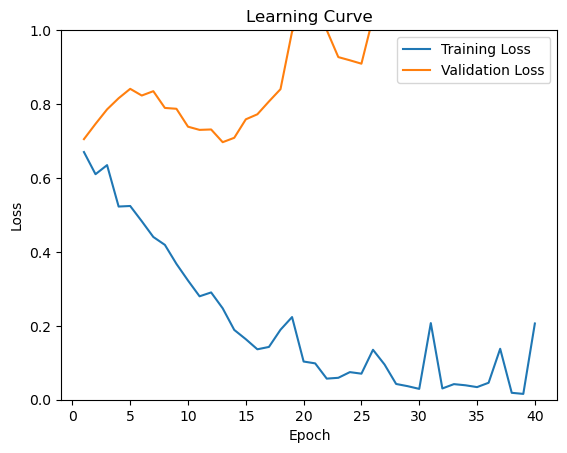

Fold 2
Accuracy Train: 0.9527083337306976. Accuracy valid: 0.8125
Recall Train: 0.890869140625. Recall valid: 0.6750000715255737
Precision Train: 0.9250000022351742. Precision valid: 0.8041666686534882
Best Valid Accuracy Epoc: 8. Value = 0.9375 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 8. Value = 0.8333333730697632 Acc val = 0.9375


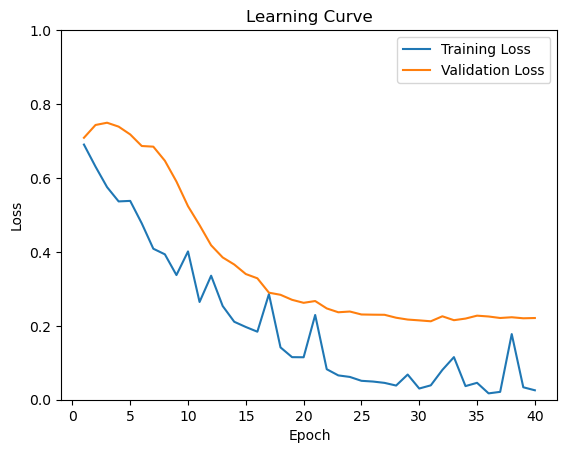

Fold 3
Accuracy Train: 0.9535416673123838. Accuracy valid: 0.8734375
Recall Train: 0.9714404344558716. Recall valid: 0.7500000596046448
Precision Train: 0.9432857632637024. Precision valid: 0.895833333581686
Best Valid Accuracy Epoc: 5. Value = 0.9375 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 5. Value = 0.8333333730697632 Acc val = 0.9375


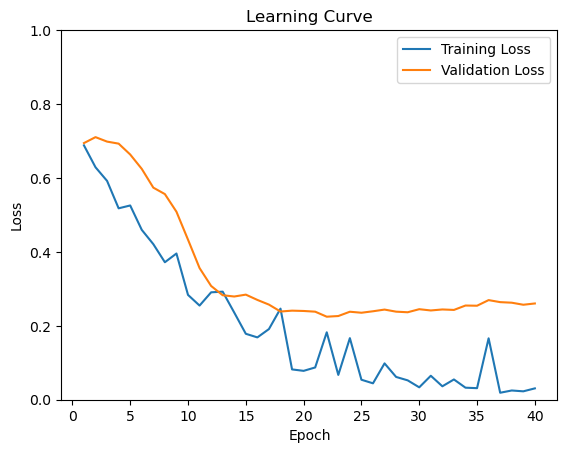

Fold 4
Accuracy Train: 0.9185416673123836. Accuracy valid: 0.8875
Recall Train: 0.8274880647659302. Recall valid: 0.4000000059604645
Precision Train: 0.8825000017881394. Precision valid: 0.30797619596123693
Best Valid Accuracy Epoc: 8. Value = 1.0 Recall val = 0.5
Best Valid Recall Epoc: 8. Value = 0.5 Acc val = 1.0


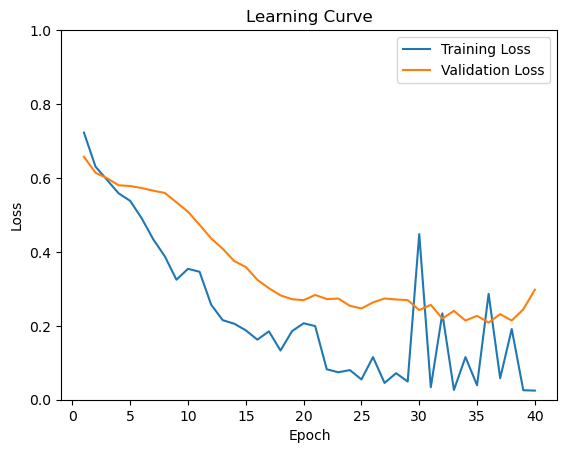

Fold 5
Accuracy Train: 0.9487500000000001. Accuracy valid: 0.775
Recall Train: 0.8877261877059937. Recall valid: 0.6000000238418579
Precision Train: 0.9450000017881394. Precision valid: 0.775
Best Valid Accuracy Epoc: 9. Value = 0.875 Recall val = 0.75
Best Valid Recall Epoc: 9. Value = 0.75 Acc val = 0.875


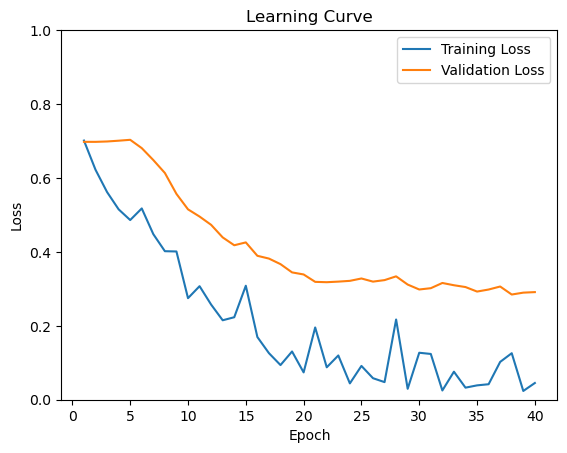

5
Fold 0: Training Loss: 0.2109096153639257, Validation Loss: 0.9921323757618665
Fold 1: Training Loss: 0.21014138874597849, Validation Loss: 0.3687415361404419
Fold 2: Training Loss: 0.20584173602983355, Validation Loss: 0.34576350200222805
Fold 3: Training Loss: 0.23439245303161443, Validation Loss: 0.35694718165323136
Fold 4: Training Loss: 0.2122012277133763, Validation Loss: 0.41933651715517045
TRAIN LOSS MEDIA: 0.21469728417694567 VALID LOSS MEDIA: 0.4965842225425877
TRAIN ACC MEDIA: 0.9399583338201047 VALID ACC MEDIA: 0.751875
TRAIN RECALL MEDIA: 0.8874691128730774 VALID RECALL MEDIA: 0.5375000238418579
TRAIN PRECISION MEDIA: 0.9243238209933043 VALID PRECISION MEDIA: 0.6390952396392822
Fold 1
Accuracy Train: 0.9607142876301493. Accuracy valid: 0.7337500058114529
Recall Train: 0.9446428418159485. Recall valid: 0.574999988079071
Precision Train: 0.9274404644966125. Precision valid: 0.9220832586288452
Best Valid Accuracy Epoc: 6. Value = 0.7750000059604645 Recall val = 0.5
Best Val

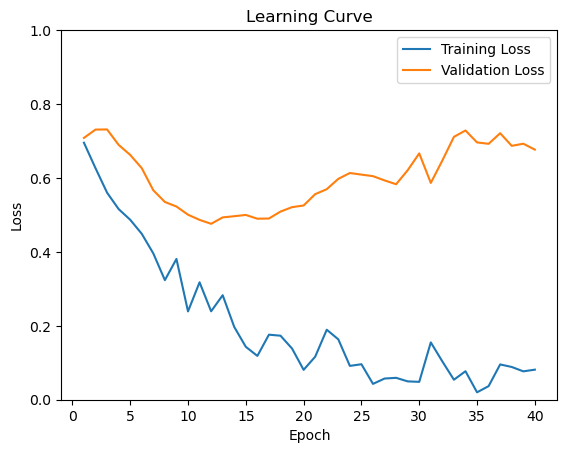

Fold 2
Accuracy Train: 0.9507142879601036. Accuracy valid: 0.8593750055879354
Recall Train: 0.8839882016181946. Recall valid: 0.7291666865348816
Precision Train: 0.9214285746216774. Precision valid: 0.875
Best Valid Accuracy Epoc: 5. Value = 0.9000000059604645 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 5. Value = 0.8333333730697632 Acc val = 0.9000000059604645


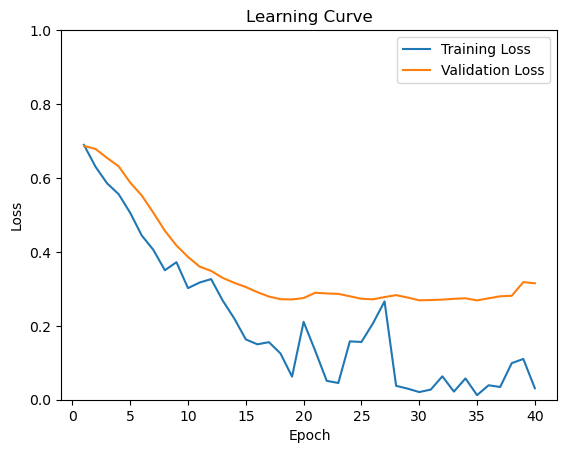

Fold 3
Accuracy Train: 0.918571431509086. Accuracy valid: 0.8212500005960465
Recall Train: 0.9516071081161499. Recall valid: 0.8500000238418579
Precision Train: 0.8890476226806641. Precision valid: 0.9245833158493042
Best Valid Accuracy Epoc: 6. Value = 0.875 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.4750000014901161


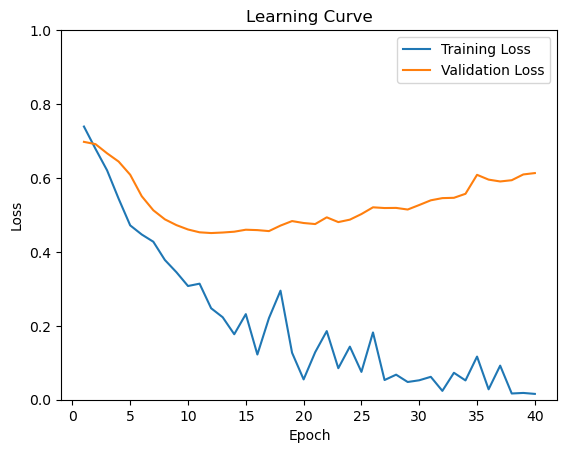

Fold 4
Accuracy Train: 0.920714288417782. Accuracy valid: 0.705625007301569
Recall Train: 0.9609524011611938. Recall valid: 1.0
Precision Train: 0.9037500619888306. Precision valid: 0.581041693687439
Best Valid Accuracy Epoc: 11. Value = 0.7750000059604645 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.42500001192092896


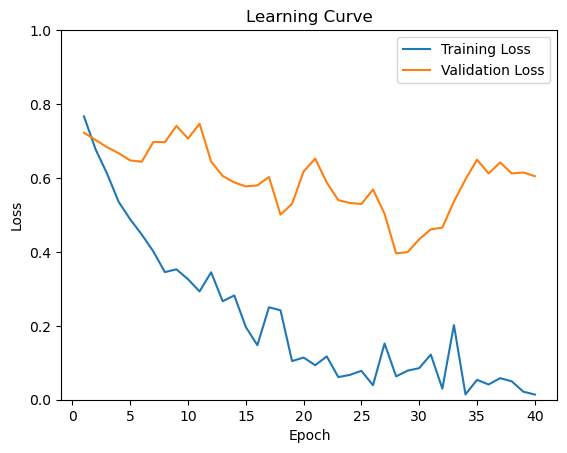

Fold 5
Accuracy Train: 0.8843750027939677. Accuracy valid: 0.729166679084301
Recall Train: 0.7109895944595337. Recall valid: 0.543749988079071
Precision Train: 0.75. Precision valid: 0.7375
Best Valid Accuracy Epoc: 11. Value = 0.8333333432674408 Recall val = 0.75
Best Valid Recall Epoc: 11. Value = 0.75 Acc val = 0.8333333432674408


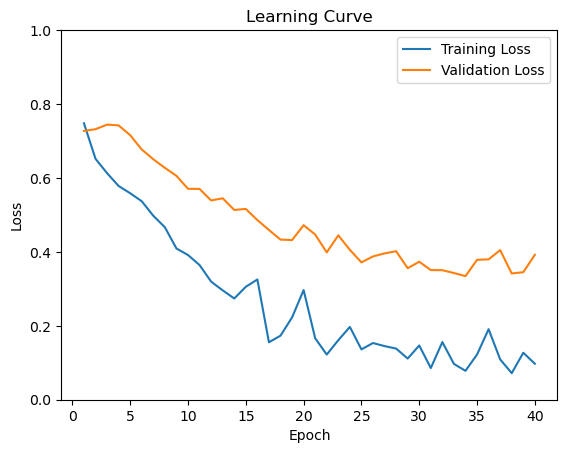

5
Fold 0: Training Loss: 0.20606417208909988, Validation Loss: 0.6029013738036155
Fold 1: Training Loss: 0.21103623285889625, Validation Loss: 0.3556426077382639
Fold 2: Training Loss: 0.21234673457220196, Validation Loss: 0.5312464252579957
Fold 3: Training Loss: 0.21592476386576892, Validation Loss: 0.5959763828665018
Fold 4: Training Loss: 0.26993588395416734, Validation Loss: 0.48404515432193873
TRAIN LOSS MEDIA: 0.2230615574680269 VALID LOSS MEDIA: 0.5139623887976632
TRAIN ACC MEDIA: 0.9270178596622177 VALID ACC MEDIA: 0.7698333396762609
TRAIN RECALL MEDIA: 0.8904359936714172 VALID RECALL MEDIA: 0.7395833730697632
TRAIN PRECISION MEDIA: 0.8783333447575569 VALID PRECISION MEDIA: 0.8080416536331176


In [ ]:
prueba_k_fold_resnet_no_pre_impr(df_mean, 5, 40, optim.Adam, 8, 1e-5, False, None)
prueba_k_fold_resnet_no_pre_impr(df_mean, 5, 40, optim.Adam, 5, 1e-5, False, None)

Fold 1
Accuracy Train: 0.8878571469336748. Accuracy valid: 0.7406250070780516
Recall Train: 0.8663690686225891. Recall valid: 0.53125
Precision Train: 0.8786309957504272. Precision valid: 0.8883333206176758
Best Valid Accuracy Epoc: 15. Value = 0.9000000059604645 Recall val = 0.75
Best Valid Recall Epoc: 2. Value = 1.0 Acc val = 0.675000011920929


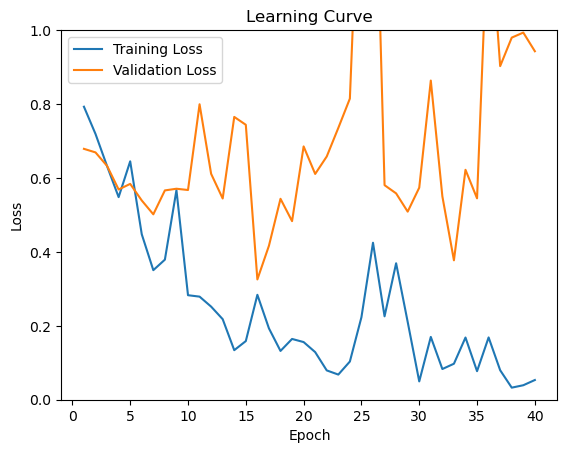

Fold 2
Accuracy Train: 0.8564285758882761. Accuracy valid: 0.8237500056624413
Recall Train: 0.8189285397529602. Recall valid: 0.737500011920929
Precision Train: 0.8197618722915649. Precision valid: 0.8137500017881394
Best Valid Accuracy Epoc: 20. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 7. Value = 1.0 Acc val = 0.6500000059604645


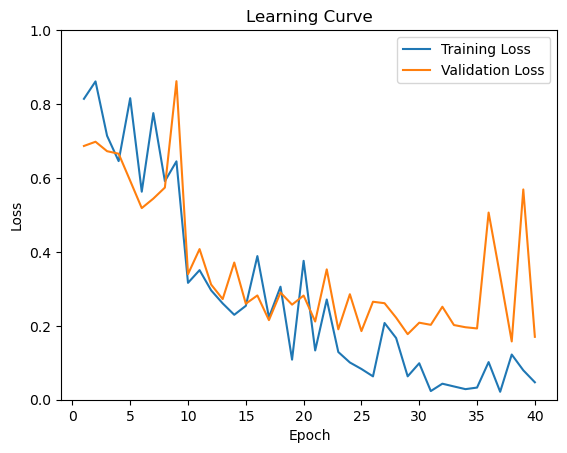

Fold 3
Accuracy Train: 0.8371428627520799. Accuracy valid: 0.7281250035390258
Recall Train: 0.8082143068313599. Recall valid: 0.800000011920929
Precision Train: 0.8202381134033203. Precision valid: 0.7356250032782554
Best Valid Accuracy Epoc: 3. Value = 0.875 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.4750000014901161


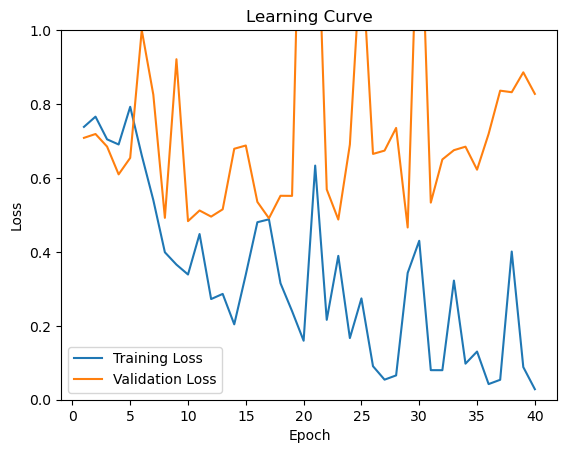

Fold 4
Accuracy Train: 0.8228571476680893. Accuracy valid: 0.7268750060349702
Recall Train: 0.7978571057319641. Recall valid: 0.841666579246521
Precision Train: 0.7956547737121582. Precision valid: 0.5714583359658718
Best Valid Accuracy Epoc: 16. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.42500001192092896


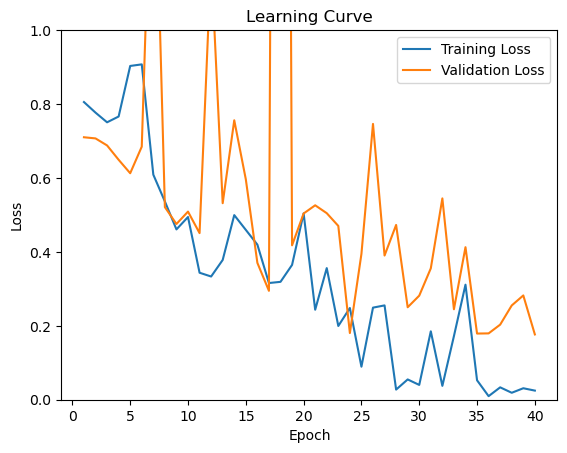

Fold 5
Accuracy Train: 0.7975000052247196. Accuracy valid: 0.745000011101365
Recall Train: 0.7472916841506958. Recall valid: 0.8062499761581421
Precision Train: 0.7477083206176758. Precision valid: 0.7200000151991844
Best Valid Accuracy Epoc: 11. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 3. Value = 1.0 Acc val = 0.533333346247673


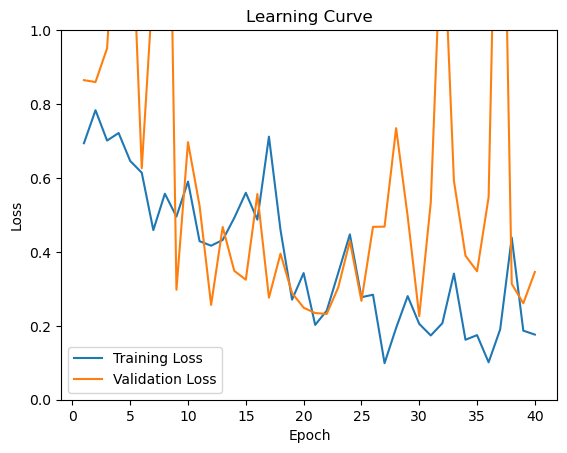

5
Fold 0: Training Loss: 0.25466175340116026, Validation Loss: 0.70655881408602
Fold 1: Training Loss: 0.2846906140912324, Validation Loss: 0.35612926217727364
Fold 2: Training Loss: 0.33041367018595336, Validation Loss: 0.7433158850762993
Fold 3: Training Loss: 0.3396743891993538, Validation Loss: 0.6579988786950708
Fold 4: Training Loss: 0.3897739458829165, Validation Loss: 0.6216660387814045
TRAIN LOSS MEDIA: 0.31984287455212324 VALID LOSS MEDIA: 0.6171337757632137
TRAIN ACC MEDIA: 0.840357147693368 VALID ACC MEDIA: 0.7528750066831709
TRAIN RECALL MEDIA: 0.807732105255127 VALID RECALL MEDIA: 0.7433333396911621
TRAIN PRECISION MEDIA: 0.8123987913131714 VALID PRECISION MEDIA: 0.7458333353698253


In [ ]:
prueba_k_fold_resnet_no_pre_impr(df_mean, 5, 40, optim.SGD, 5, 0.01, False, None)


Fold 1
Accuracy Train: 0.9735714296677284. Accuracy valid: 0.7443750068545342
Recall Train: 0.9199405908584595. Recall valid: 0.4375
Precision Train: 0.9321429133415222. Precision valid: 0.86875
Best Valid Accuracy Epoc: 5. Value = 0.7750000059604645 Recall val = 0.5
Best Valid Recall Epoc: 5. Value = 0.5 Acc val = 0.7750000059604645


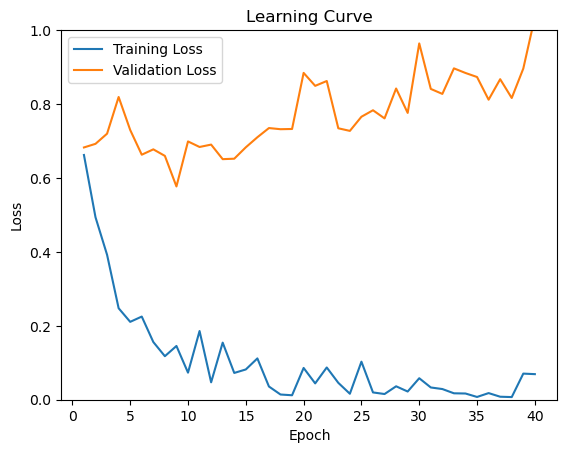

Fold 2
Accuracy Train: 0.9757142868425166. Accuracy valid: 0.8225000068545342
Recall Train: 0.9566071629524231. Recall valid: 0.8541666865348816
Precision Train: 0.9476190805435181. Precision valid: 0.8904167413711548
Best Valid Accuracy Epoc: 9. Value = 0.9000000059604645 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.42500001192092896


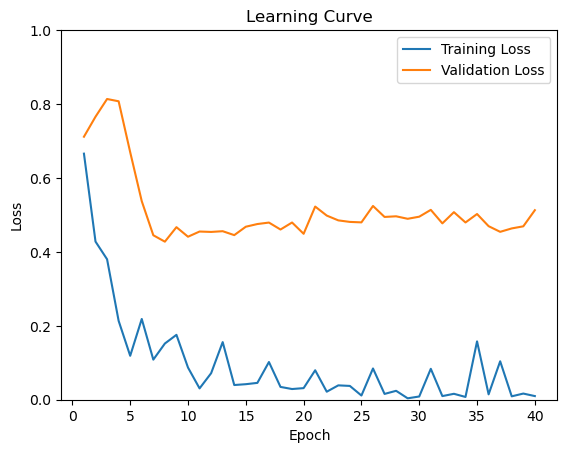

Fold 3
Accuracy Train: 0.9700000014688289. Accuracy valid: 0.8493750002235174
Recall Train: 0.9381548166275024. Recall valid: 0.8041666746139526
Precision Train: 0.9589284658432007. Precision valid: 0.948958333581686
Best Valid Accuracy Epoc: 3. Value = 0.875 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 0. Value = 0.8333333730697632 Acc val = 0.45000000298023224


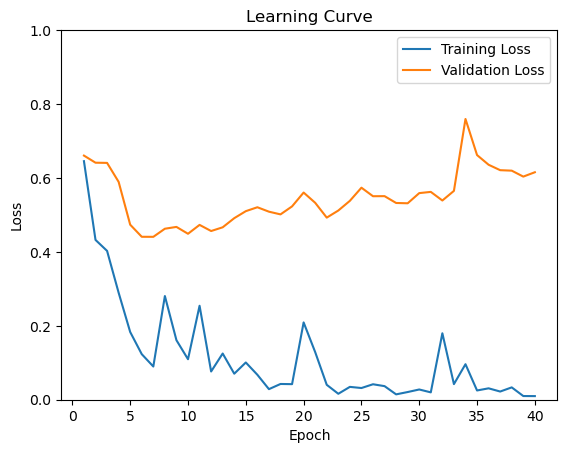

Fold 4
Accuracy Train: 0.9614285731954235. Accuracy valid: 0.7806250039488077
Recall Train: 0.9279167056083679. Recall valid: 0.8666666150093079
Precision Train: 0.9538690447807312. Precision valid: 0.59375
Best Valid Accuracy Epoc: 22. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 6. Value = 1.0 Acc val = 0.7750000059604645


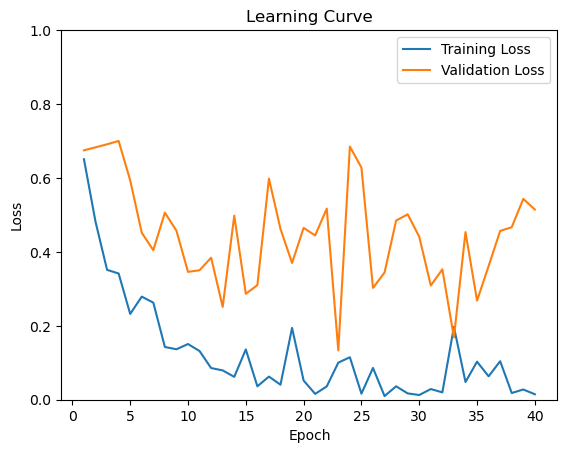

Fold 5
Accuracy Train: 0.9493750010151416. Accuracy valid: 0.8908333387225866
Recall Train: 0.8426041603088379. Recall valid: 0.831250011920929
Precision Train: 0.862500011920929. Precision valid: 0.9166666686534881
Best Valid Accuracy Epoc: 10. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 10. Value = 1.0 Acc val = 1.0


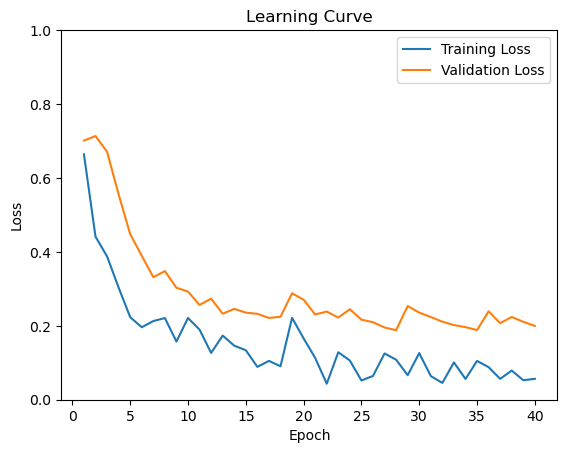

5
Fold 0: Training Loss: 0.10624761718790979, Validation Loss: 0.7721815846860409
Fold 1: Training Loss: 0.09712519175955095, Validation Loss: 0.5131057773716747
Fold 2: Training Loss: 0.11491674573626369, Validation Loss: 0.545884249266237
Fold 3: Training Loss: 0.12449395747389644, Validation Loss: 0.4465234206058085
Fold 4: Training Loss: 0.15268560843542217, Validation Loss: 0.28928574374876914
TRAIN LOSS MEDIA: 0.11909382411860862 VALID LOSS MEDIA: 0.513396155135706
TRAIN ACC MEDIA: 0.9660178584379278 VALID ACC MEDIA: 0.8175416713207959
TRAIN RECALL MEDIA: 0.9170446395874023 VALID RECALL MEDIA: 0.7587499618530273
TRAIN PRECISION MEDIA: 0.9310118556022644 VALID PRECISION MEDIA: 0.8437083487212658
Fold 1
Accuracy Train: 0.9392857170530728. Accuracy valid: 0.740000007674098
Recall Train: 0.9122023582458496. Recall valid: 0.5
Precision Train: 0.9363095164299011. Precision valid: 0.8716667294502258
Best Valid Accuracy Epoc: 2. Value = 0.800000011920929 Recall val = 0.5
Best Valid Recal

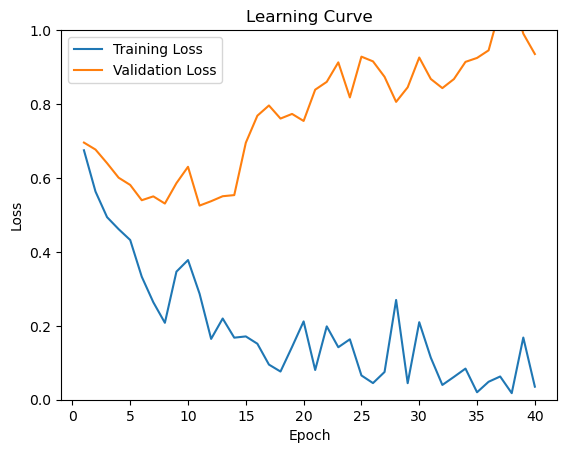

Fold 2
Accuracy Train: 0.9185714319348335. Accuracy valid: 0.8593750059604645
Recall Train: 0.9047619104385376. Recall valid: 0.7333333492279053
Precision Train: 0.9133332967758179. Precision valid: 0.8833333343267441
Best Valid Accuracy Epoc: 5. Value = 0.9000000059604645 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 5. Value = 0.8333333730697632 Acc val = 0.9000000059604645


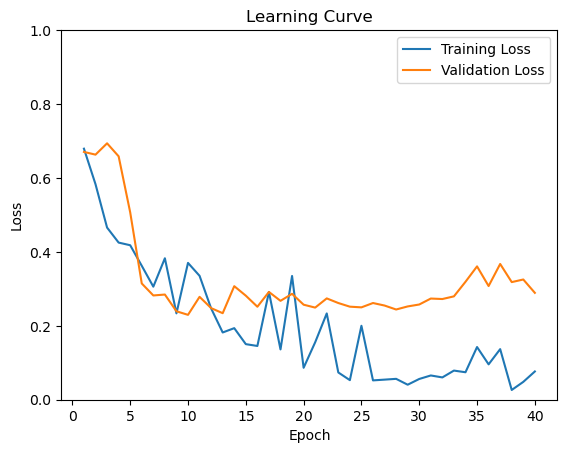

Fold 3
Accuracy Train: 0.9428571458905936. Accuracy valid: 0.8375000014901162
Recall Train: 0.9220237731933594. Recall valid: 0.7916666865348816
Precision Train: 0.9505952000617981. Precision valid: 0.904166667163372
Best Valid Accuracy Epoc: 2. Value = 0.875 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 2. Value = 0.8333333730697632 Acc val = 0.875


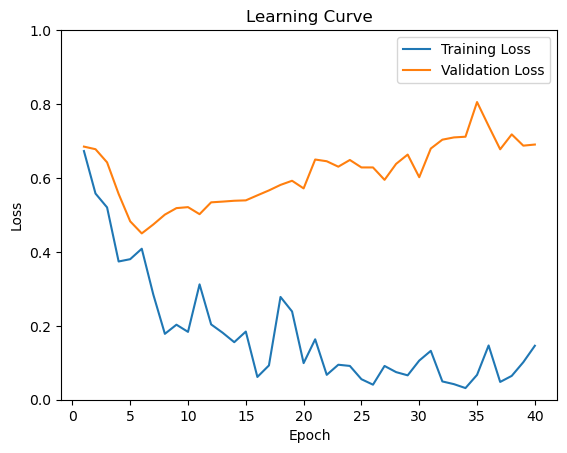

Fold 4
Accuracy Train: 0.9078571456351451. Accuracy valid: 0.8193750061094761
Recall Train: 0.9201785922050476. Recall valid: 0.9125000238418579
Precision Train: 0.9011309742927551. Precision valid: 0.7275000035762786
Best Valid Accuracy Epoc: 6. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.42500001192092896


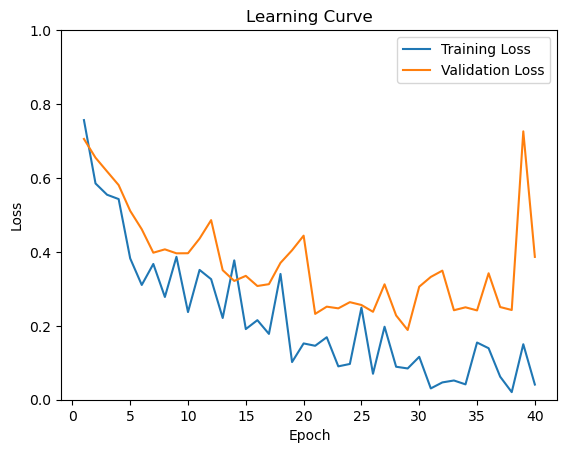

Fold 5
Accuracy Train: 0.8693750038277358. Accuracy valid: 0.7741666786372662
Recall Train: 0.7583854794502258. Recall valid: 0.65625
Precision Train: 0.8072916686534881. Precision valid: 0.8625000059604645
Best Valid Accuracy Epoc: 6. Value = 0.8333333432674408 Recall val = 0.75
Best Valid Recall Epoc: 6. Value = 0.75 Acc val = 0.8333333432674408


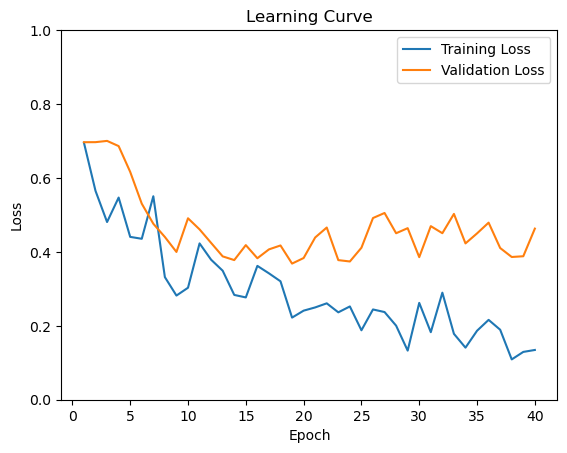

5
Fold 0: Training Loss: 0.19473905181512235, Validation Loss: 0.7730570707470179
Fold 1: Training Loss: 0.20273712440393865, Validation Loss: 0.32292341694701465
Fold 2: Training Loss: 0.1812698788009584, Validation Loss: 0.6119191057048738
Fold 3: Training Loss: 0.22259230813942849, Validation Loss: 0.3695971969515085
Fold 4: Training Loss: 0.29626461043953894, Validation Loss: 0.4637390784919262
TRAIN LOSS MEDIA: 0.2195205947197974 VALID LOSS MEDIA: 0.5082471737684682
TRAIN ACC MEDIA: 0.9155892888682763 VALID ACC MEDIA: 0.8060833399742842
TRAIN RECALL MEDIA: 0.883510410785675 VALID RECALL MEDIA: 0.71875
TRAIN PRECISION MEDIA: 0.9017321312427521 VALID PRECISION MEDIA: 0.8498333480954171


In [ ]:
prueba_k_fold_resnet_no_pre_impr(df_mean, 5, 40, optim.RMSprop, 5, 1e-5, False, None)
prueba_k_fold_resnet_no_pre_impr(df_mean, 5, 40, optim.RMSprop, 5, 1e-5, True, None)

#### SIN TL CON OC

In [ ]:
def accuracy(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, consideramos que es positiva
    correct = (preds == labels.byte())  # Compara las predicciones con las etiquetas reales
    acc = correct.float().sum() / labels.size(0)  # Calcula la precisión
    return acc.item()

def recall(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()
    TP = sum((preds == 1) & (labels == 1))
    FN = sum((preds == 0) & (labels == 1))
    
    recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0
    return recall_score

def precision(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()

    TP = sum((preds == 1) & (labels == 1))
    FP = sum((preds == 1) & (labels == 0))
    
    precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0
    return precision_score

def prueba_k_fold_resnet_no_pre_oc_impr(dataset, num_folds, num_epochs, op, batch_size, lr, data_aug, ini):
    # Transformaciones para preprocesar las imágenes
    if data_aug:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            # v2.RandomResizedCrop(224),
            v2.RandomHorizontalFlip(),
            v2.RandomVerticalFlip(),
            # v2.ElasticTransform(alpha=250.0),
            # v2.RandomRotation(45),
            # transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    else:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    
    # Modelo personalizado basado en ResNet
    class CustomResNet(nn.Module):
        def __init__(self, num_classes_binary=1):
            super(CustomResNet, self).__init__()
            resnet = models.resnet18(weights=None)# New weights with accuracy 80.858%
            # Extraer las capas de la red ResNet, excluyendo la capa de clasificación
            self.features = nn.Sequential(*list(resnet.children())[:-1])
    
            # Personalizar la capa de salida para tus necesidades
            self.fc_binary = nn.Linear(512, num_classes_binary)
            
            if (ini== "G"):
                # Inicialización de Glorot para las capas fully connected
                self.apply(self.init_weights_glorot)
            elif(ini == "H"):
                self.apply(self.init_weights_he)

        def init_weights_glorot(self, m):
            if isinstance(m, nn.Linear):
                init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_he(self, m):
            if isinstance(m, nn.Linear):
                init.kaiming_uniform_(m.weight, mode='fan_in', nonlinearity='relu')
                if m.bias is not None:
                    init.constant_(m.bias, 0)
    
        def forward(self, x):
            x = self.features(x)
            x = x.view(x.size(0), -1)
    
    
            # Salida para la variable binaria
            out_binary = self.fc_binary(x)
    
            return out_binary
    
    # Definir una clase para el conjunto de datos personalizado
    ##adaptar esto para meter unas rutsa y obtener dataos y etiquetas
    class CustomDataset(Dataset):
        def __init__(self, dataframe, transform=None):
            self.data = dataframe
            self.transform = transform
    
        def __len__(self):
            return len(self.data)
    
        def __getitem__(self, idx):
            img_path = self.data.iloc[idx, 0]  # Ruta de la imagen en la primera columna
            image = Image.open(img_path).convert('RGB')
            # Etiquetas: una variable binaria
            label_binary = torch.tensor(self.data.iloc[idx, 1], dtype=torch.float32)
    
            if self.transform:
                image = self.transform(image)
    
            return image, label_binary
        
    #####5 fold CV
    from sklearn.model_selection import StratifiedKFold
    
    # Definir el número de folds
    criterion_binary = nn.BCEWithLogitsLoss()
    kf = StratifiedKFold(n_splits=num_folds, shuffle=True, random_state=33)
    
    # Listas para almacenar las pérdidas de entrenamiento y validación de cada fold
    train_losses_folds = []
    val_losses_folds = []
    
    train_accs_folds = []
    train_rec_folds =  []
    train_preci_folds = []

    val_accs_folds = []
    val_rec_folds =  []
    val_preci_folds = []
    # Iterar sobre los folds
    for fold, (train_index, val_index) in enumerate(kf.split(np.zeros(len(dataset)),dataset['Etiqueta'])):
        print(f"Fold {fold + 1}")
    
        # Dividir el conjunto de datos en entrenamiento y validación para este fold
        train_data_fold = dataset.iloc[train_index]
        val_data_fold = dataset.iloc[val_index]
    
        # Crear instancias del conjunto de datos personalizado para este fold
        train_dataset_fold = CustomDataset(dataframe=train_data_fold, transform=transform_t)
        val_dataset_fold = CustomDataset(dataframe=val_data_fold, transform=transform_v)
    
        # Crear DataLoader para cargar los datos en lotes
        train_loader_fold = DataLoader(dataset=train_dataset_fold, batch_size=batch_size, shuffle=True)
        val_loader_fold = DataLoader(dataset=val_dataset_fold, batch_size=len(val_dataset_fold), shuffle=False) 
    
        # Re-inicializar el modelo para cada fold
        model = CustomResNet(num_classes_binary=1).to(device)
        optimizer = op(model.parameters(), lr = lr)
        scheduler = optim.lr_scheduler.OneCycleLR(optimizer, max_lr=lr, steps_per_epoch=len(train_loader_fold), epochs=num_epochs)
        # Entrenamiento y validación para este fold
        train_losses_fold = []
        val_losses_fold = []
        train_accuracy_fold = []
        val_accuracy_fold = []
        train_recall_fold = []
        val_recall_fold = []
        train_preci_fold = []
        val_preci_fold = []

        for epoch in range(num_epochs):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            lossT_bin_total = 0.0
            correct_train = 0
            recall_value_train = 0
            precision_value_train = 0
            for images, bin_label in train_loader_fold:
                
                # Reiniciar gradientes
                images, bin_label = images.to(device), bin_label.to(device)
        
                optimizer.zero_grad()
        
                # Forward pass
                bin_out = model(images)
        
                # Calcular pérdida para las variables continuas
                
        
        
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
        
                # Pérdida total
                loss_total = lossT_bin
    
                loss_total_acumulada += loss_total
    
                # Backward pass y optimización
                loss_total.backward()
                optimizer.step()
                scheduler.step()

                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_train += accuracy(bin_pred, bin_label)
                recall_value_train += recall(bin_pred, bin_label)
                precision_value_train += precision(bin_pred, bin_label)

        
    
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            correct_valid = 0
            recall_value_valid = 0
            precision_value_valid = 0
            lossV_bin_total = 0.0
            with torch.no_grad():
                for images, bin_label in val_loader_fold:
                
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    ##print(len(images)) aqui se hace con 32 imagenes
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
    
    
    
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()

                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    correct_valid += accuracy(bin_pred, bin_label)
                    recall_value_valid += recall(bin_pred, bin_label)
                    precision_value_valid += precision(bin_pred, bin_label)
                    
            
            
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold)
            train_losses_fold.append(avg_loss_total_acumulada)
            acc_train = correct_train / len(train_loader_fold)
            recall_train = recall_value_train / len(train_loader_fold)
            precision_train = precision_value_train / len(train_loader_fold)
            train_accuracy_fold.append(acc_train)
            train_recall_fold.append(recall_train)
            train_preci_fold.append(precision_train)
        
            avg_val_loss = val_loss / len(val_loader_fold)
            val_losses_fold.append(avg_val_loss)
            acc_valid = correct_valid / len(val_loader_fold)
            recall_valid = recall_value_valid / len(val_loader_fold)
            precision_valid = precision_value_valid / len(val_loader_fold)
            val_accuracy_fold.append(acc_valid)
            val_recall_fold.append(recall_valid)
            val_preci_fold.append(precision_valid)
            # print(f'Epoch [{epoch+1}/{num_epochs}], Training Loss: {avg_loss_total_acumulada.item()}, Validation Loss: {avg_val_loss}')
        
      
        print(f"Accuracy Train: {np.mean(train_accuracy_fold)}. Accuracy valid: {np.mean(val_accuracy_fold)}")
        print(f"Recall Train: {np.mean(train_recall_fold)}. Recall valid: {np.mean(val_recall_fold)}")
        print(f"Precision Train: {np.mean(train_preci_fold)}. Precision valid: {np.mean(val_preci_fold)}")
        print(f'Best Valid Accuracy Epoc: {np.argmax(val_accuracy_fold)}. Value = {val_accuracy_fold[np.argmax(val_accuracy_fold)]} Recall val = {val_recall_fold[np.argmax(val_accuracy_fold)]}')
        print(f'Best Valid Recall Epoc: {np.argmax(val_recall_fold)}. Value = {val_recall_fold[np.argmax(val_recall_fold)]} Acc val = {val_accuracy_fold[np.argmax(val_recall_fold)]}')
        train_accs_folds.append(np.mean(train_accuracy_fold))
        train_rec_folds.append(np.mean(train_recall_fold))
        train_preci_folds.append(np.mean(train_preci_fold))

        val_accs_folds.append(np.mean(val_accuracy_fold))
        val_rec_folds.append(np.mean(val_recall_fold))
        val_preci_folds.append(np.mean(val_preci_fold))

        train_losses_folds.append(train_losses_fold)
        val_losses_folds.append(val_losses_fold)
        train_losses_fold = [i.cpu().detach().numpy() for i in train_losses_fold]
        learning_curve(train_losses_fold, val_losses_fold)
    
    train_losses_folds_cpu = []
    val_losses_folds_cpu = []
    for losses in val_losses_folds:
        val_losses_fold_cpu = []
        for loss in losses:
            val_losses_fold_cpu.append(loss)
        val_losses_folds_cpu.append(np.array(val_losses_fold_cpu))
    for losses in train_losses_folds:
        train_losses_fold_cpu = []
        for loss in losses:
            train_losses_fold_cpu.append(float(loss.cpu().detach().numpy()))
        train_losses_folds_cpu.append(np.array(train_losses_fold_cpu))
    print(len(train_losses_folds_cpu))
    avg_train = []
    avg_val = []
    for losses in train_losses_folds_cpu:
        avg_train.append(np.mean(losses))
    for losses in val_losses_folds_cpu:
        avg_val.append(np.mean(losses))
    
     # Imprimir pérdidas promedio para cada época
    for fold, (train_loss, val_loss) in enumerate(zip(avg_train, avg_val)):
        print(f"Fold {fold}: Training Loss: {train_loss}, Validation Loss: {val_loss}")
    
    print(f"TRAIN LOSS MEDIA: {np.mean(avg_train)} VALID LOSS MEDIA: {np.mean(avg_val)}")
    print(f"TRAIN ACC MEDIA: {np.mean(train_accs_folds)} VALID ACC MEDIA: {np.mean(val_accs_folds)}")        
    print(f"TRAIN RECALL MEDIA: {np.mean(train_rec_folds)} VALID RECALL MEDIA: {np.mean(val_rec_folds)}")
    print(f"TRAIN PRECISION MEDIA: {np.mean(train_preci_folds)} VALID PRECISION MEDIA: {np.mean(val_preci_folds)}")     

Fold 1
Accuracy Train: 0.8850000037146465. Accuracy valid: 0.7200000077486038
Recall Train: 0.7447618842124939. Recall valid: 0.375
Precision Train: 0.7892857175320387. Precision valid: 0.75
Best Valid Accuracy Epoc: 12. Value = 0.7750000059604645 Recall val = 0.5
Best Valid Recall Epoc: 12. Value = 0.5 Acc val = 0.7750000059604645


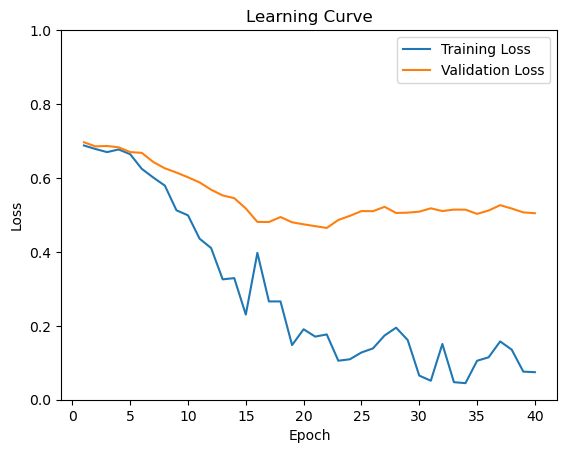

Fold 2
Accuracy Train: 0.9200000035975661. Accuracy valid: 0.8612500060349703
Recall Train: 0.8568452596664429. Recall valid: 0.8166667819023132
Precision Train: 0.9184524416923523. Precision valid: 0.8489583343267441
Best Valid Accuracy Epoc: 19. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 5. Value = 1.0 Acc val = 0.9000000059604645


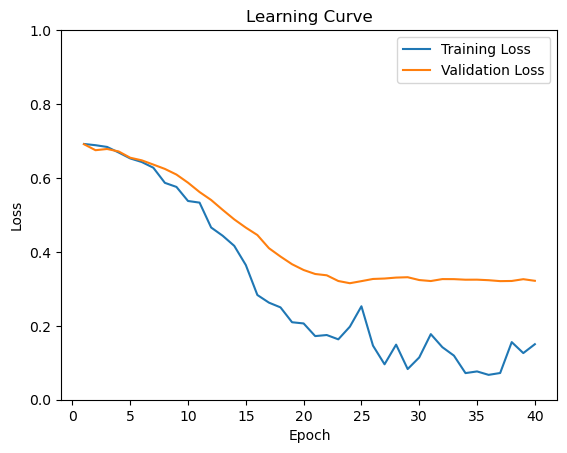

Fold 3
Accuracy Train: 0.8835714323180062. Accuracy valid: 0.7862500010058284
Recall Train: 0.7314286231994629. Recall valid: 0.7541667222976685
Precision Train: 0.7642857175320387. Precision valid: 0.8668750010430812
Best Valid Accuracy Epoc: 15. Value = 0.875 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.4750000014901161


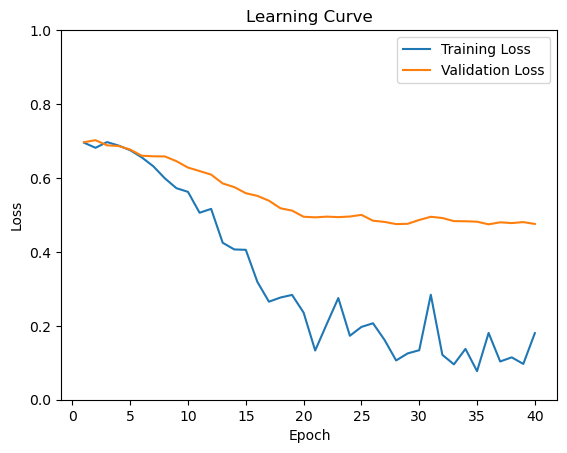

Fold 4
Accuracy Train: 0.8485714324350868. Accuracy valid: 0.6312500104308129
Recall Train: 0.9567261934280396. Recall valid: 1.0
Precision Train: 0.8422619104385376. Precision valid: 0.533333420753479
Best Valid Accuracy Epoc: 23. Value = 0.7750000059604645 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.42500001192092896


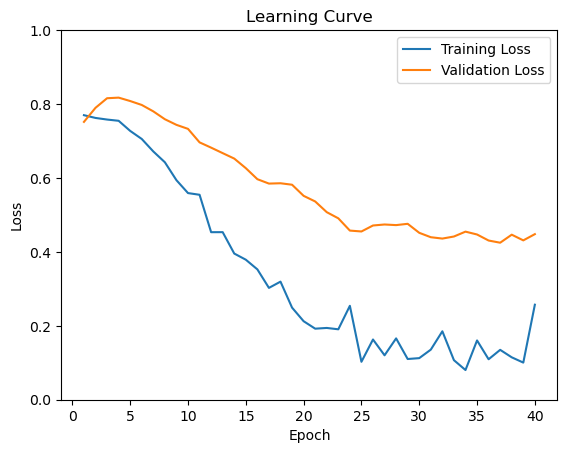

Fold 5
Accuracy Train: 0.8537500039674342. Accuracy valid: 0.7800000093877315
Recall Train: 0.6502083539962769. Recall valid: 0.625
Precision Train: 0.690625. Precision valid: 0.7083333365619182
Best Valid Accuracy Epoc: 17. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 14. Value = 1.0 Acc val = 0.8333333432674408


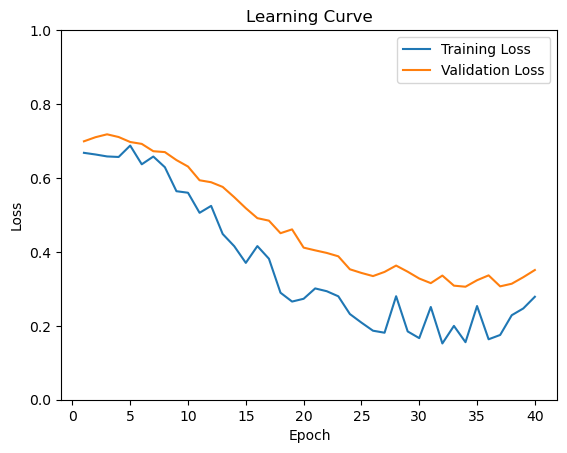

5
Fold 0: Training Loss: 0.28939320603385565, Validation Loss: 0.5466329589486122
Fold 1: Training Loss: 0.312546007707715, Validation Loss: 0.4379332361742854
Fold 2: Training Loss: 0.33013754319399596, Validation Loss: 0.549185686558485
Fold 3: Training Loss: 0.34018176067620515, Validation Loss: 0.5803500279784203
Fold 4: Training Loss: 0.36728308312594893, Validation Loss: 0.4700880417600274
TRAIN LOSS MEDIA: 0.3279083201475442 VALID LOSS MEDIA: 0.516837990283966
TRAIN ACC MEDIA: 0.878178575206548 VALID ACC MEDIA: 0.7557500069215892
TRAIN RECALL MEDIA: 0.7879940867424011 VALID RECALL MEDIA: 0.7141667604446411
TRAIN PRECISION MEDIA: 0.8009821574389935 VALID PRECISION MEDIA: 0.7415000185370445


In [ ]:
prueba_k_fold_resnet_no_pre_oc_impr(df_mean, 5, 40, optim.Adam, 5, 1e-5, False, None)

Fold 1
Accuracy Train: 0.8428571479661123. Accuracy valid: 0.6937500078231096
Recall Train: 0.78125. Recall valid: 0.550000011920929
Precision Train: 0.7959523849189282. Precision valid: 0.755833338201046
Best Valid Accuracy Epoc: 10. Value = 0.800000011920929 Recall val = 0.75
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.675000011920929


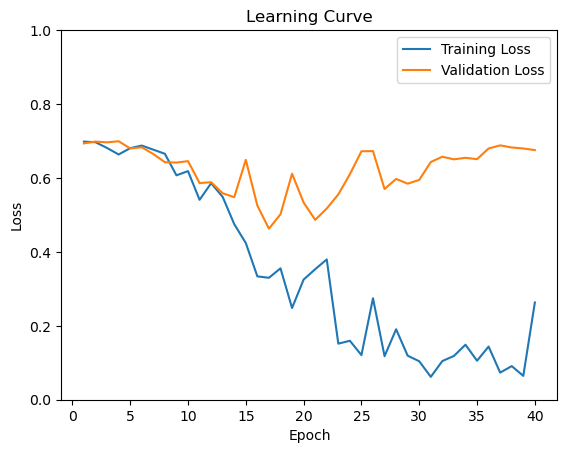

Fold 2
Accuracy Train: 0.8135714357984917. Accuracy valid: 0.7675000056624413
Recall Train: 0.6702381372451782. Recall valid: 0.7833333611488342
Precision Train: 0.7267857152968645. Precision valid: 0.7425000041723251
Best Valid Accuracy Epoc: 8. Value = 0.9000000059604645 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.42500001192092896


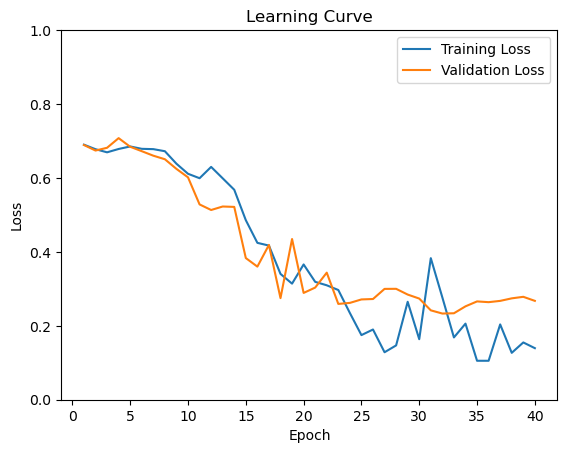

Fold 3
Accuracy Train: 0.8435714344893182. Accuracy valid: 0.7737500028684735
Recall Train: 0.757440447807312. Recall valid: 0.7666667699813843
Precision Train: 0.8184523805975914. Precision valid: 0.7952083371579647
Best Valid Accuracy Epoc: 15. Value = 0.875 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 8. Value = 1.0 Acc val = 0.4750000014901161


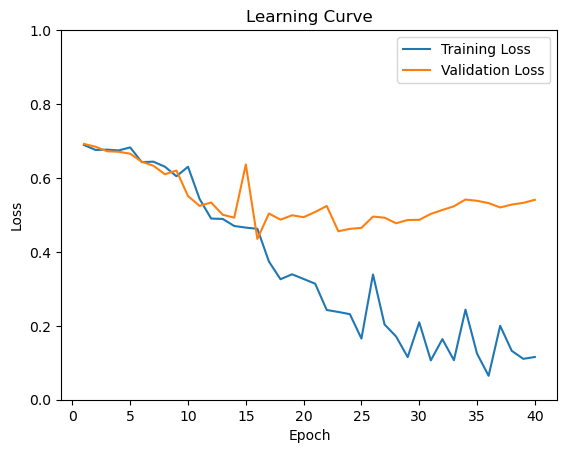

Fold 4
Accuracy Train: 0.8300000063010625. Accuracy valid: 0.68375000692904
Recall Train: 0.7599999904632568. Recall valid: 0.92083340883255
Precision Train: 0.8158928565680981. Precision valid: 0.5412500038743019
Best Valid Accuracy Epoc: 18. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 3. Value = 1.0 Acc val = 0.42500001192092896


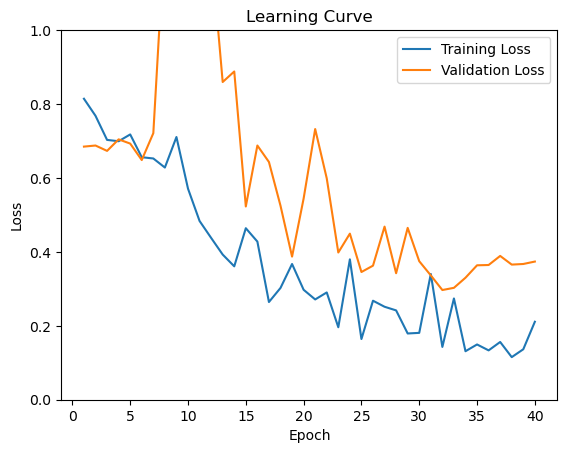

Fold 5
Accuracy Train: 0.7925000061281026. Accuracy valid: 0.786666676774621
Recall Train: 0.6606249809265137. Recall valid: 0.8500000238418579
Precision Train: 0.7127604179084301. Precision valid: 0.8200000181794167
Best Valid Accuracy Epoc: 18. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.533333346247673


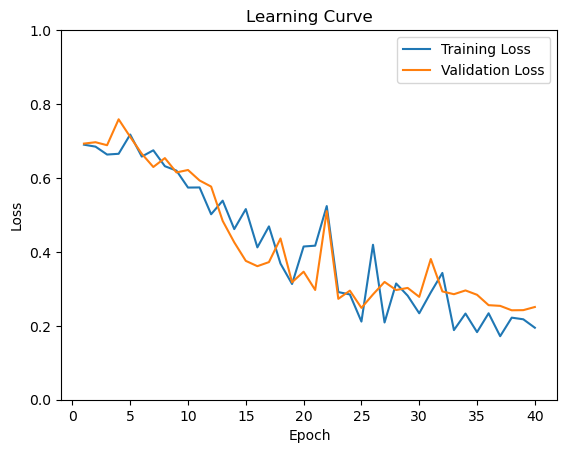

5
Fold 0: Training Loss: 0.3497059360146523, Validation Loss: 0.6208282351493836
Fold 1: Training Loss: 0.3880731578916311, Validation Loss: 0.4085837179794908
Fold 2: Training Loss: 0.3609021302312613, Validation Loss: 0.5419392972718924
Fold 3: Training Loss: 0.37332662139087913, Validation Loss: 0.6243975281715393
Fold 4: Training Loss: 0.4153239630162716, Validation Loss: 0.42279197201132773
TRAIN LOSS MEDIA: 0.37746636170893905 VALID LOSS MEDIA: 0.5237081501167268
TRAIN ACC MEDIA: 0.8245000061366173 VALID ACC MEDIA: 0.7410833400115371
TRAIN RECALL MEDIA: 0.7259107232093811 VALID RECALL MEDIA: 0.7741667032241821
TRAIN PRECISION MEDIA: 0.7739687510579824 VALID PRECISION MEDIA: 0.7309583403170109


In [ ]:
prueba_k_fold_resnet_no_pre_oc_impr(df_mean, 5, 40, optim.SGD, 5, 0.001, False, None)

Fold 1
Accuracy Train: 0.9550000020435878. Accuracy valid: 0.7150000087916851
Recall Train: 0.9063690304756165. Recall valid: 0.44999998807907104
Precision Train: 0.9250000014901161. Precision valid: 0.7854166686534881
Best Valid Accuracy Epoc: 4. Value = 0.7750000059604645 Recall val = 0.5
Best Valid Recall Epoc: 13. Value = 0.75 Acc val = 0.7750000059604645


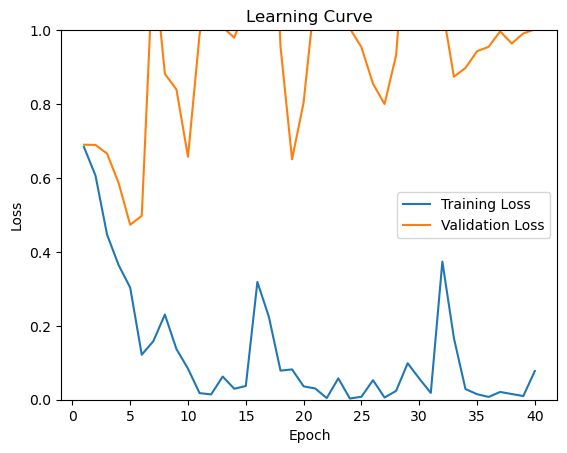

Fold 2
Accuracy Train: 0.940714288183621. Accuracy valid: 0.8656250044703484
Recall Train: 0.8844642639160156. Recall valid: 0.7583333253860474
Precision Train: 0.9017857149243355. Precision valid: 0.8427083343267441
Best Valid Accuracy Epoc: 31. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 8. Value = 1.0 Acc val = 0.875


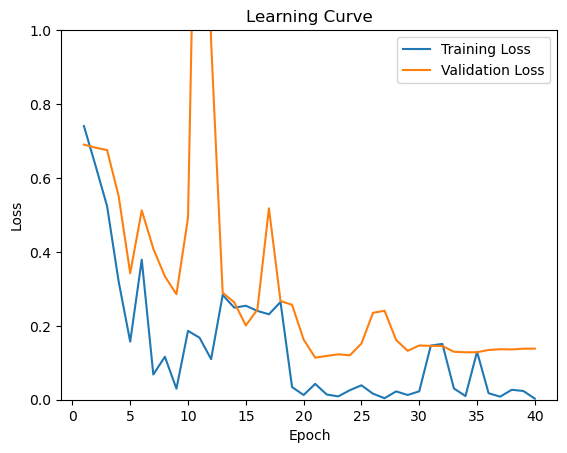

Fold 3
Accuracy Train: 0.9514285736318145. Accuracy valid: 0.8118750009685755
Recall Train: 0.9091072082519531. Recall valid: 0.7208333611488342
Precision Train: 0.9375. Precision valid: 0.8427083335816861
Best Valid Accuracy Epoc: 5. Value = 0.875 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 5. Value = 0.8333333730697632 Acc val = 0.875


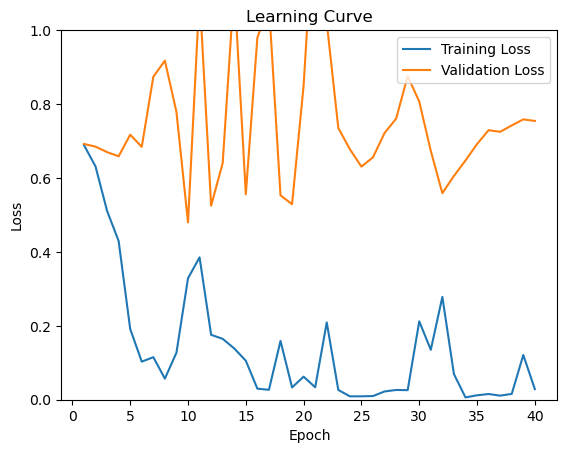

Fold 4
Accuracy Train: 0.9435714306043728. Accuracy valid: 0.8337500028312206
Recall Train: 0.9047619104385376. Recall valid: 0.8125
Precision Train: 0.9214285690337419. Precision valid: 0.7002083346247673
Best Valid Accuracy Epoc: 19. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 8. Value = 1.0 Acc val = 0.875


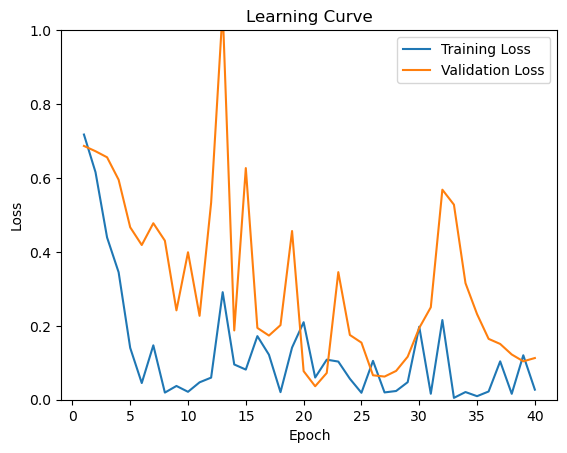

Fold 5
Accuracy Train: 0.9318750020116567. Accuracy valid: 0.7450000092387199
Recall Train: 0.8076562881469727. Recall valid: 0.731249988079071
Precision Train: 0.8234375. Precision valid: 0.7862500071525573
Best Valid Accuracy Epoc: 8. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 5. Value = 1.0 Acc val = 0.8333333432674408


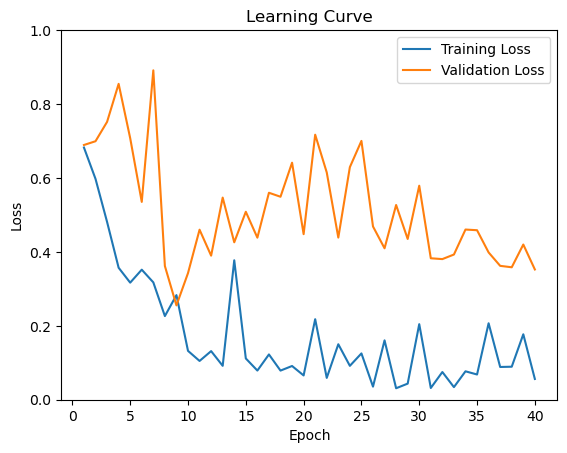

5
Fold 0: Training Loss: 0.12785016482812353, Validation Loss: 0.9483259566128254
Fold 1: Training Loss: 0.1439496442733798, Validation Loss: 0.3286421594268177
Fold 2: Training Loss: 0.14353812836343421, Validation Loss: 0.7553047167457407
Fold 3: Training Loss: 0.12661997065879405, Validation Loss: 0.3156570961466059
Fold 4: Training Loss: 0.17556932200677694, Validation Loss: 0.513568491092883
TRAIN LOSS MEDIA: 0.14350544602610169 VALID LOSS MEDIA: 0.5722996840049746
TRAIN ACC MEDIA: 0.9445178592950105 VALID ACC MEDIA: 0.7942500052601099
TRAIN RECALL MEDIA: 0.8824717402458191 VALID RECALL MEDIA: 0.6945832967758179
TRAIN PRECISION MEDIA: 0.9018303570896388 VALID PRECISION MEDIA: 0.7914583356678486


In [ ]:
prueba_k_fold_resnet_no_pre_oc_impr(df_mean, 5, 40, optim.RMSprop, 5, 1e-5, False, None)

#### CON TL SIN OC

In [ ]:

def accuracy(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, consideramos que es positiva
    correct = (preds == labels.byte())  # Compara las predicciones con las etiquetas reales
    acc = correct.float().sum() / labels.size(0)  # Calcula la precisión
    return acc.item()

def recall(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()
    TP = sum((preds == 1) & (labels == 1))
    FN = sum((preds == 0) & (labels == 1))
    
    recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0
    return recall_score

def precision(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()

    TP = sum((preds == 1) & (labels == 1))
    FP = sum((preds == 1) & (labels == 0))
    
    precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0
    return precision_score



def prueba_k_fold_resnet_pre_impr(dataset, num_folds, num_epochs_freeze, num_epochs_all, op, batch_size, lr, data_aug, ini):
    # Transformaciones para preprocesar las imágenes
    if data_aug:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            # v2.RandomResizedCrop(224),
            v2.RandomHorizontalFlip(),
            v2.RandomVerticalFlip(),
            # v2.ElasticTransform(alpha=250.0),
            # v2.RandomRotation(45),
            # transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    else:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    
    # Modelo personalizado basado en ResNet
    class CustomResNet(nn.Module):
        def __init__(self, num_classes_binary=1):
            super(CustomResNet, self).__init__()
            resnet = models.resnet18(weights='IMAGENET1K_V1')
            # Extraer las capas de la red ResNet, excluyendo la capa de clasificación
            self.features = nn.Sequential(*list(resnet.children())[:-1])

            # Congelar capas preentrenadas
            for param in self.features.parameters():
                param.requires_grad = False

            # Personalizar la capa de salida para tus necesidades
            self.fc_binary = nn.Linear(512, num_classes_binary)
            
            if (ini== "G"):
                # Inicialización de Glorot para las capas fully connected
                self.apply(self.init_weights_glorot)
            elif(ini == "H"):
                self.apply(self.init_weights_he)
            elif (ini== "N"):
                self.apply(self.init_weights_normal)
            elif(ini == "U"):
                self.apply(self.init_weights_uniform)
            elif (ini== "O"):
                self.apply(self.init_weights_orthogonal)
            elif(ini == "Z"):
                self.apply(self.init_weights_zeros)
            elif(ini == "ON"):
                self.apply(self.init_weights_ones)

        def init_weights_glorot(self, m):
            if isinstance(m, nn.Linear):
                init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_he(self, m):
            if isinstance(m, nn.Linear):
                init.kaiming_uniform_(m.weight, mode='fan_in', nonlinearity='relu')
                if m.bias is not None:
                    init.constant_(m.bias, 0)
        def init_weights_normal(self, m):
            if isinstance(m, nn.Linear):
                init.normal_(m.weight, mean=0, std=0.01)  
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_uniform(self, m):
            if isinstance(m, nn.Linear):
                init.uniform_(m.weight, a=-0.1, b=0.1)  
                if m.bias is not None:
                    init.constant_(m.bias, 0)
    
        def init_weights_orthogonal(self, m):
            if isinstance(m, nn.Linear):
                init.orthogonal_(m.weight)  
                if m.bias is not None:
                    init.constant_(m.bias, 0)
    
        def init_weights_zeros(self, m):
            if isinstance(m, nn.Linear):
                init.zeros_(m.weight)
                if m.bias is not None:
                    init.zeros_(m.bias)
    
        def init_weights_ones(self, m):
            if isinstance(m, nn.Linear):
                init.ones_(m.weight)
                if m.bias is not None:
                    init.ones_(m.bias)
    
        def forward(self, x):
            x = self.features(x)
            x = x.view(x.size(0), -1)
    
    
            # Salida para la variable binaria
            out_binary = self.fc_binary(x)
    
            return out_binary
    
    # Definir una clase para el conjunto de datos personalizado
    ##adaptar esto para meter unas rutsa y obtener dataos y etiquetas
    class CustomDataset(Dataset):
        def __init__(self, dataframe, transform=None):
            self.data = dataframe
            self.transform = transform
    
        def __len__(self):
            return len(self.data)
    
        def __getitem__(self, idx):
            img_path = self.data.iloc[idx, 0]  # Ruta de la imagen en la primera columna
            image = Image.open(img_path).convert('RGB')
            # Etiquetas: una variable binaria
            label_binary = torch.tensor(self.data.iloc[idx, 1], dtype=torch.float32)
    
            if self.transform:
                image = self.transform(image)
    
            return image, label_binary
        
    #####5 fold CV
    from sklearn.model_selection import StratifiedKFold
    
    # Definir el número de folds
    criterion_binary = nn.BCEWithLogitsLoss()
    kf = StratifiedKFold(n_splits=num_folds, shuffle=True, random_state=33)
    
    # Listas para almacenar las pérdidas de entrenamiento y validación de cada fold
    train_losses_folds = []
    val_losses_folds = []
    
    train_accs_folds = []
    train_rec_folds =  []
    train_preci_folds = []

    val_accs_folds = []
    val_rec_folds =  []
    val_preci_folds = []
    # Iterar sobre los folds
    for fold, (train_index, val_index) in enumerate(kf.split(np.zeros(len(dataset)),dataset['Etiqueta'])):
        print(f"Fold {fold + 1}")
    
        # Dividir el conjunto de datos en entrenamiento y validación para este fold
        train_data_fold = dataset.iloc[train_index]
        val_data_fold = dataset.iloc[val_index]
    
        # Crear instancias del conjunto de datos personalizado para este fold
        train_dataset_fold = CustomDataset(dataframe=train_data_fold, transform=transform_t)
        val_dataset_fold = CustomDataset(dataframe=val_data_fold, transform=transform_v)
    
        # Crear DataLoader para cargar los datos en lotes
        train_loader_fold = DataLoader(dataset=train_dataset_fold, batch_size=batch_size, shuffle=True)
        val_loader_fold = DataLoader(dataset=val_dataset_fold, batch_size=len(val_dataset_fold), shuffle=False) 
    
        # Re-inicializar el modelo para cada fold
        model = CustomResNet(num_classes_binary=1).to(device)
        optimizer = op(model.parameters(), lr = lr)
        optimizer2 = op(model.fc_binary.parameters(), lr = lr)
        # Entrenamiento y validación para este fold
        train_losses_fold = []
        val_losses_fold = []
        train_accuracy_fold = []
        val_accuracy_fold = []
        train_recall_fold = []
        val_recall_fold = []
        train_preci_fold = []
        val_preci_fold = []

        for epoch in range(num_epochs_freeze):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            lossT_bin_total = 0.0
            correct_train = 0
            recall_value_train = 0
            precision_value_train = 0
            for images, bin_label in train_loader_fold:
            
                images, bin_label = images.to(device), bin_label.to(device)

                

                optimizer2.zero_grad()
        
                # Forward pass
                bin_out = model(images)
                        
        
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
        
                # Pérdida total
                loss_total = lossT_bin
    
                loss_total_acumulada += loss_total
    
                # Backward pass y optimización
                loss_total.backward()
                optimizer2.step()

                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_train += accuracy(bin_pred, bin_label)
                recall_value_train += recall(bin_pred, bin_label)
                precision_value_train += precision(bin_pred, bin_label)

        
    
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            correct_valid = 0
            recall_value_valid = 0
            precision_value_valid = 0
            lossV_bin_total = 0.0
            with torch.no_grad():
                for images, bin_label in val_loader_fold:
                    # Reiniciar gradientes
                
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
    
    
    
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()

                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    correct_valid += accuracy(bin_pred, bin_label)
                    recall_value_valid += recall(bin_pred, bin_label)
                    precision_value_valid += precision(bin_pred, bin_label)
                    
            
            
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold)
            train_losses_fold.append(avg_loss_total_acumulada)
            acc_train = correct_train / len(train_loader_fold)
            recall_train = recall_value_train / len(train_loader_fold)
            precision_train = precision_value_train / len(train_loader_fold)
            train_accuracy_fold.append(acc_train)
            train_recall_fold.append(recall_train)
            train_preci_fold.append(precision_train)

            avg_val_loss = val_loss / len(val_loader_fold)
            val_losses_fold.append(avg_val_loss)
            acc_valid = correct_valid / len(val_loader_fold)
            recall_valid = recall_value_valid / len(val_loader_fold)
            precision_valid = precision_value_valid / len(val_loader_fold)
            val_accuracy_fold.append(acc_valid)
            val_recall_fold.append(recall_valid)
            val_preci_fold.append(precision_valid)

        ##Se descongelan todas
        for param in model.features.parameters():
            param.requires_grad = True
            
        for epoch in range(num_epochs_freeze, num_epochs_freeze + num_epochs_all):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            lossT_bin_total = 0.0
            correct_train = 0
            recall_value_train = 0
            precision_value_train = 0
            for images, bin_label in train_loader_fold:

                images, bin_label = images.to(device), bin_label.to(device)

                optimizer.zero_grad()
        
                # Forward pass
                bin_out = model(images)
        
                # Calcular pérdida para las variables continuas
                
        
        
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
        
                # Pérdida total
                loss_total = lossT_bin
    
                loss_total_acumulada += loss_total
    
                # Backward pass y optimización
                loss_total.backward()
                optimizer.step()

                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_train += accuracy(bin_pred, bin_label)
                recall_value_train += recall(bin_pred, bin_label)
                precision_value_train += precision(bin_pred, bin_label)

        
    
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            correct_valid = 0
            recall_value_valid = 0
            precision_value_valid = 0
            lossV_bin_total = 0.0
            with torch.no_grad():
                for images, bin_label in val_loader_fold:
                    
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
        
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()

                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    correct_valid += accuracy(bin_pred, bin_label)
                    recall_value_valid += recall(bin_pred, bin_label)
                    precision_value_valid += precision(bin_pred, bin_label)

                    
                    
            
            
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold)
            train_losses_fold.append(avg_loss_total_acumulada)
            acc_train = correct_train / len(train_loader_fold)
            recall_train = recall_value_train / len(train_loader_fold)
            precision_train = precision_value_train / len(train_loader_fold)
            train_accuracy_fold.append(acc_train)
            train_recall_fold.append(recall_train)
            train_preci_fold.append(precision_train)
        
            avg_val_loss = val_loss / len(val_loader_fold)
            val_losses_fold.append(avg_val_loss)
            acc_valid = correct_valid / len(val_loader_fold)
            recall_valid = recall_value_valid / len(val_loader_fold)
            precision_valid = precision_value_valid / len(val_loader_fold)
            val_accuracy_fold.append(acc_valid)
            val_recall_fold.append(recall_valid)
            val_preci_fold.append(precision_valid)
            # print(f'Epoch [{epoch+1}/{num_epochs}], Training Loss: {avg_loss_total_acumulada.item()}, Validation Loss: {avg_val_loss}')

        print(f"Accuracy Train: {np.mean(train_accuracy_fold)}. Accuracy valid: {np.mean(val_accuracy_fold)}")
        print(f"Recall Train: {np.mean(train_recall_fold)}. Recall valid: {np.mean(val_recall_fold)}")
        print(f"Precision Train: {np.mean(train_preci_fold)}. Precision valid: {np.mean(val_preci_fold)}")
        print(f'Best Valid Accuracy Epoc: {np.argmax(val_accuracy_fold)}. Value = {val_accuracy_fold[np.argmax(val_accuracy_fold)]} Recall val = {val_recall_fold[np.argmax(val_accuracy_fold)]}')
        print(f'Best Valid Recall Epoc: {np.argmax(val_recall_fold)}. Value = {val_recall_fold[np.argmax(val_recall_fold)]} Acc val = {val_accuracy_fold[np.argmax(val_recall_fold)]}')
        train_accs_folds.append(np.mean(train_accuracy_fold))
        train_rec_folds.append(np.mean(train_recall_fold))
        train_preci_folds.append(np.mean(train_preci_fold))

        val_accs_folds.append(np.mean(val_accuracy_fold))
        val_rec_folds.append(np.mean(val_recall_fold))
        val_preci_folds.append(np.mean(val_preci_fold))

        train_losses_folds.append(train_losses_fold)
        val_losses_folds.append(val_losses_fold)
        train_losses_fold = [i.cpu().detach().numpy() for i in train_losses_fold]
        learning_curve(train_losses_fold, val_losses_fold)

        
    
    train_losses_folds_cpu = []
    val_losses_folds_cpu = []
    for losses in val_losses_folds:
        val_losses_fold_cpu = []
        for loss in losses:
            val_losses_fold_cpu.append(loss)
        val_losses_folds_cpu.append(np.array(val_losses_fold_cpu))
    for losses in train_losses_folds:
        train_losses_fold_cpu = []
        for loss in losses:
            train_losses_fold_cpu.append(float(loss.cpu().detach().numpy()))
        train_losses_folds_cpu.append(np.array(train_losses_fold_cpu))
    print(len(train_losses_folds_cpu))
    avg_train = []
    avg_val = []
    for losses in train_losses_folds_cpu:
        avg_train.append(np.mean(losses))
    for losses in val_losses_folds_cpu:
        avg_val.append(np.mean(losses))

    
     # Imprimir pérdidas promedio para cada época
    for fold, (train_loss, val_loss) in enumerate(zip(avg_train, avg_val)):
        print(f"Fold {fold}: Training Loss: {train_loss}, Validation Loss: {val_loss}")
    
    print(f"TRAIN LOSS MEDIA: {np.mean(avg_train)} VALID LOSS MEDIA: {np.mean(avg_val)}")
    print(f"TRAIN ACC MEDIA: {np.mean(train_accs_folds)} VALID ACC MEDIA: {np.mean(val_accs_folds)}")        
    print(f"TRAIN RECALL MEDIA: {np.mean(train_rec_folds)} VALID RECALL MEDIA: {np.mean(val_rec_folds)}")
    print(f"TRAIN PRECISION MEDIA: {np.mean(train_preci_folds)} VALID PRECISION MEDIA: {np.mean(val_preci_folds)}")  
    

Fold 1
Accuracy Train: 0.9057142882474831. Accuracy valid: 0.7250000067055226
Recall Train: 0.8433928489685059. Recall valid: 0.44999998807907104
Precision Train: 0.8744047284126282. Precision valid: 0.7854166686534881
Best Valid Accuracy Epoc: 5. Value = 0.875 Recall val = 0.75
Best Valid Recall Epoc: 5. Value = 0.75 Acc val = 0.875


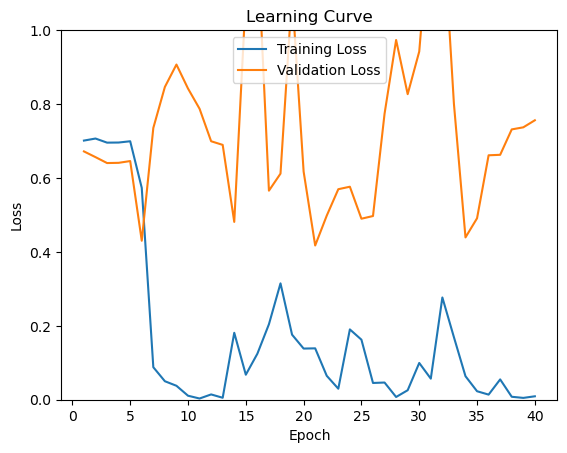

Fold 2
Accuracy Train: 0.902857146518571. Accuracy valid: 0.8287500061094761
Recall Train: 0.8533332943916321. Recall valid: 0.7583333253860474
Precision Train: 0.8880952596664429. Precision valid: 0.862500011920929
Best Valid Accuracy Epoc: 32. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 9. Value = 1.0 Acc val = 0.9000000059604645


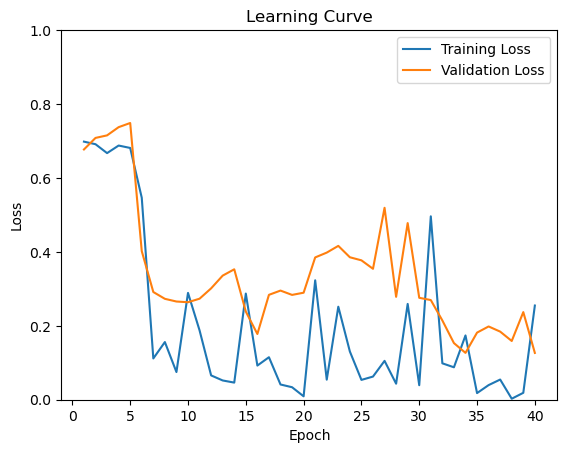

Fold 3
Accuracy Train: 0.8992857178407055. Accuracy valid: 0.8000000014901161
Recall Train: 0.8091667294502258. Recall valid: 0.7041667103767395
Precision Train: 0.8261904777958989. Precision valid: 0.835416667163372
Best Valid Accuracy Epoc: 7. Value = 0.875 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 7. Value = 0.8333333730697632 Acc val = 0.875


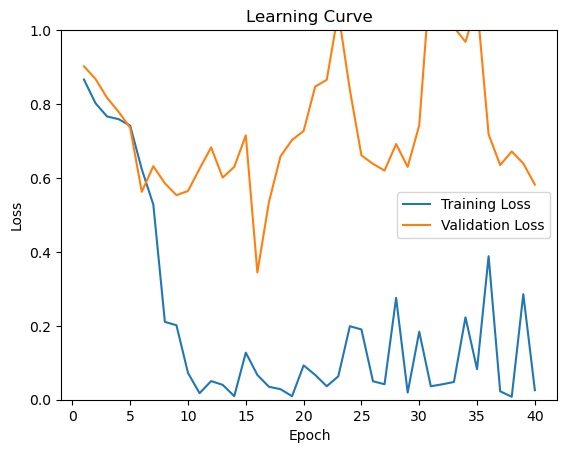

Fold 4
Accuracy Train: 0.9064285749835628. Accuracy valid: 0.7737500052899122
Recall Train: 0.8689881563186646. Recall valid: 0.8500000238418579
Precision Train: 0.8901785612106323. Precision valid: 0.6000000014901161
Best Valid Accuracy Epoc: 6. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 6. Value = 1.0 Acc val = 1.0


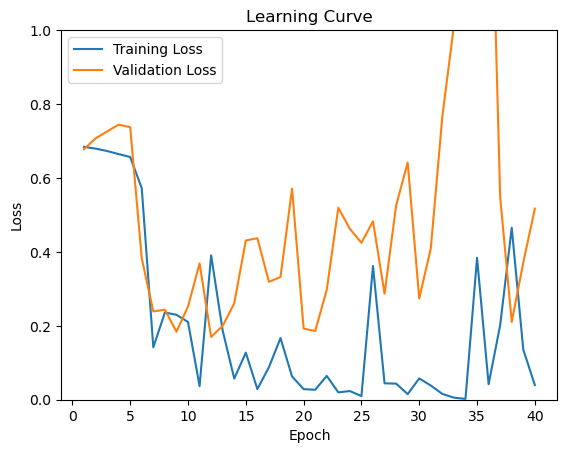

Fold 5
Accuracy Train: 0.8812500022351741. Accuracy valid: 0.776666677929461
Recall Train: 0.877916693687439. Recall valid: 0.737500011920929
Precision Train: 0.8130208849906921. Precision valid: 0.8814582824707031
Best Valid Accuracy Epoc: 13. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.533333346247673


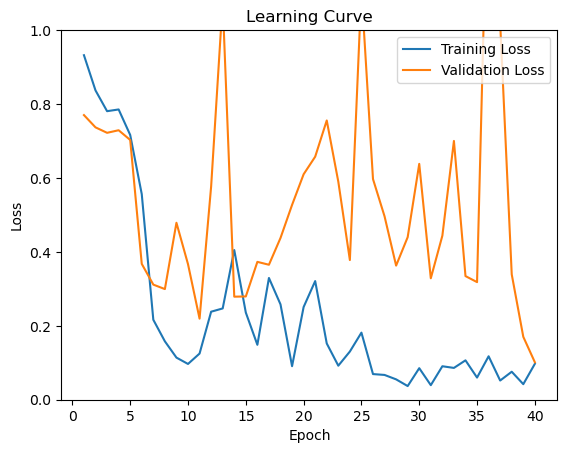

5
Fold 0: Training Loss: 0.17447161427116953, Validation Loss: 0.7345073543488979
Fold 1: Training Loss: 0.20254917308920994, Validation Loss: 0.34082022453076205
Fold 2: Training Loss: 0.20848877523094417, Validation Loss: 0.7427085325936786
Fold 3: Training Loss: 0.19796653064549902, Validation Loss: 0.5077241593971848
Fold 4: Training Loss: 0.2369742994196713, Validation Loss: 0.5389515358954668
TRAIN LOSS MEDIA: 0.20409007853129876 VALID LOSS MEDIA: 0.572942361353198
TRAIN ACC MEDIA: 0.8991071459650992 VALID ACC MEDIA: 0.7808333395048976
TRAIN RECALL MEDIA: 0.8505595326423645 VALID RECALL MEDIA: 0.6999999284744263
TRAIN PRECISION MEDIA: 0.858377982415259 VALID PRECISION MEDIA: 0.7929583263397217
Fold 1
Accuracy Train: 0.9000000035656349. Accuracy valid: 0.7100000064820051
Recall Train: 0.8247024416923523. Recall valid: 0.543749988079071
Precision Train: 0.8416666638106107. Precision valid: 0.8570833206176758
Best Valid Accuracy Epoc: 6. Value = 0.7750000059604645 Recall val = 0.5
B

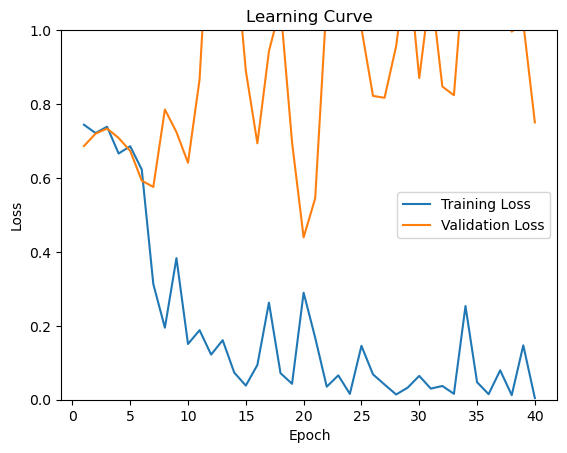

Fold 2
Accuracy Train: 0.8671428619218723. Accuracy valid: 0.8318750027567148
Recall Train: 0.8791071176528931. Recall valid: 0.908333420753479
Precision Train: 0.8421428799629211. Precision valid: 0.796875
Best Valid Accuracy Epoc: 9. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 6. Value = 1.0 Acc val = 0.875


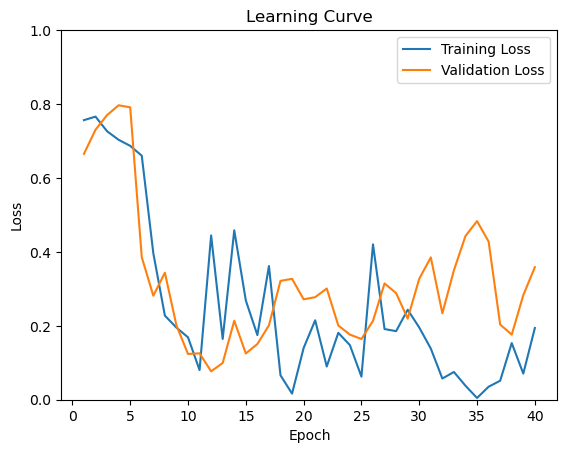

Fold 3
Accuracy Train: 0.8907142903655767. Accuracy valid: 0.7981250017881394
Recall Train: 0.8788095712661743. Recall valid: 0.8291667699813843
Precision Train: 0.8738095164299011. Precision valid: 0.8904167413711548
Best Valid Accuracy Epoc: 6. Value = 0.875 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 5. Value = 1.0 Acc val = 0.675000011920929


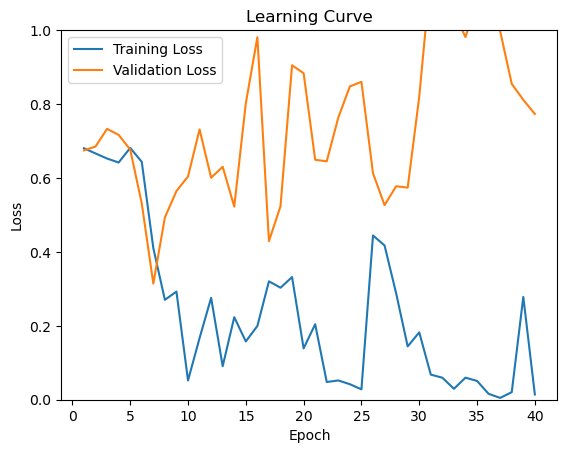

Fold 4
Accuracy Train: 0.8821428615067687. Accuracy valid: 0.7906250029802322
Recall Train: 0.835178554058075. Recall valid: 0.824999988079071
Precision Train: 0.8732143640518188. Precision valid: 0.6318750008940697
Best Valid Accuracy Epoc: 22. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 6. Value = 1.0 Acc val = 0.675000011920929


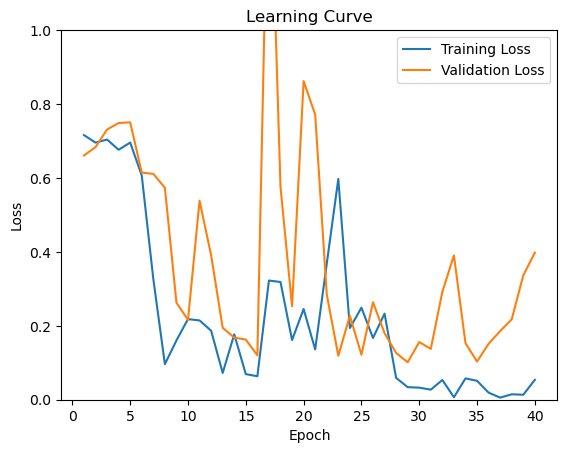

Fold 5
Accuracy Train: 0.8643750036135316. Accuracy valid: 0.7108333431184292
Recall Train: 0.7051562070846558. Recall valid: 0.6625000238418579
Precision Train: 0.7062499985098839. Precision valid: 0.7937500029802322
Best Valid Accuracy Epoc: 6. Value = 0.8333333432674408 Recall val = 0.75
Best Valid Recall Epoc: 6. Value = 0.75 Acc val = 0.8333333432674408


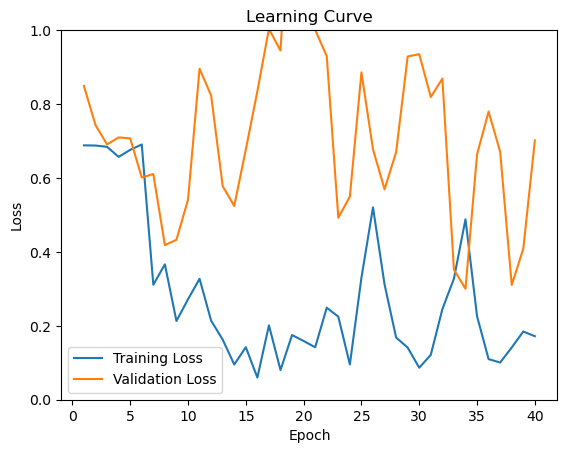

5
Fold 0: Training Loss: 0.19647482675500214, Validation Loss: 0.9384968511760234
Fold 1: Training Loss: 0.25530160043854266, Validation Loss: 0.32072241976857185
Fold 2: Training Loss: 0.24128744003828614, Validation Loss: 0.7443040786019992
Fold 3: Training Loss: 0.22750253265257925, Validation Loss: 0.38574611824005844
Fold 4: Training Loss: 0.28120231367647647, Validation Loss: 0.7240314873866737
TRAIN LOSS MEDIA: 0.24035374271217735 VALID LOSS MEDIA: 0.6226601910346654
TRAIN ACC MEDIA: 0.8808750041946769 VALID ACC MEDIA: 0.7682916714251042
TRAIN RECALL MEDIA: 0.824590802192688 VALID RECALL MEDIA: 0.7537500262260437
TRAIN PRECISION MEDIA: 0.8274166845530273 VALID PRECISION MEDIA: 0.7940000131726265


In [ ]:
prueba_k_fold_resnet_pre_impr(df_mean, 5, 5, 35, optim.Adam, 5, 0.0001, False, None)
prueba_k_fold_resnet_pre_impr(df_mean, 5, 5, 35, optim.Adam, 5, 0.0001, True, None)

Fold 1
Accuracy Train: 0.9092857175639699. Accuracy valid: 0.7587500058114529
Recall Train: 0.8852380514144897. Recall valid: 0.518750011920929
Precision Train: 0.89166659116745. Precision valid: 0.9020833373069763
Best Valid Accuracy Epoc: 5. Value = 0.875 Recall val = 0.75
Best Valid Recall Epoc: 9. Value = 1.0 Acc val = 0.875


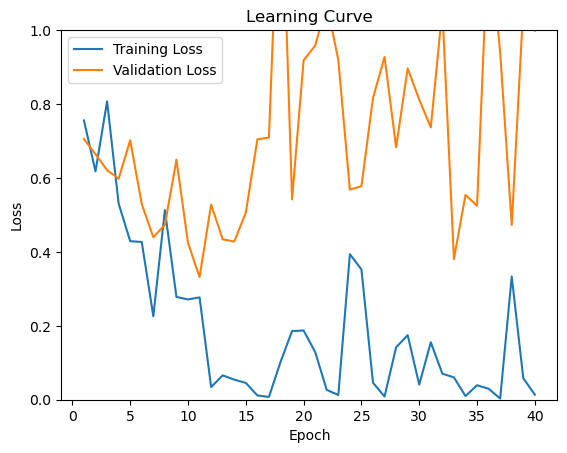

Fold 2
Accuracy Train: 0.8992857178407057. Accuracy valid: 0.777500007301569
Recall Train: 0.8687499761581421. Recall valid: 0.762499988079071
Precision Train: 0.8668452501296997. Precision valid: 0.783750006556511
Best Valid Accuracy Epoc: 3. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.42500001192092896


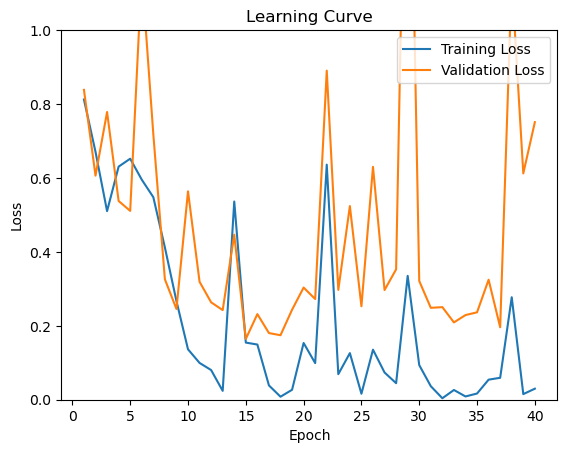

Fold 3
Accuracy Train: 0.9214285749409881. Accuracy valid: 0.7837500018998981
Recall Train: 0.8945833444595337. Recall valid: 0.8166667819023132
Precision Train: 0.8920238614082336. Precision valid: 0.8595833361148835
Best Valid Accuracy Epoc: 8. Value = 0.875 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 4. Value = 1.0 Acc val = 0.5750000029802322


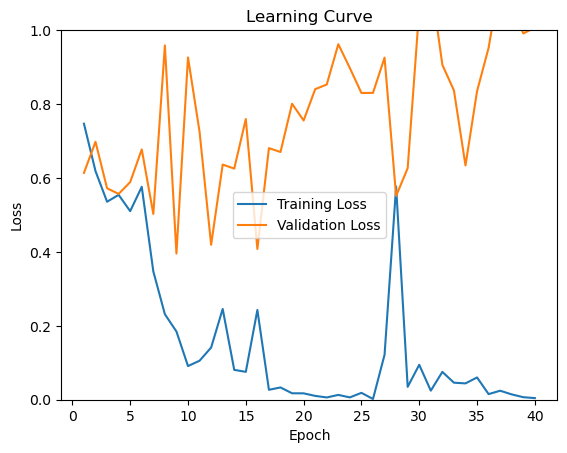

Fold 4
Accuracy Train: 0.8864285746855394. Accuracy valid: 0.8050000030547381
Recall Train: 0.8504167795181274. Recall valid: 0.841666579246521
Precision Train: 0.8373810052871704. Precision valid: 0.6410416677594185
Best Valid Accuracy Epoc: 12. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 3. Value = 1.0 Acc val = 0.42500001192092896


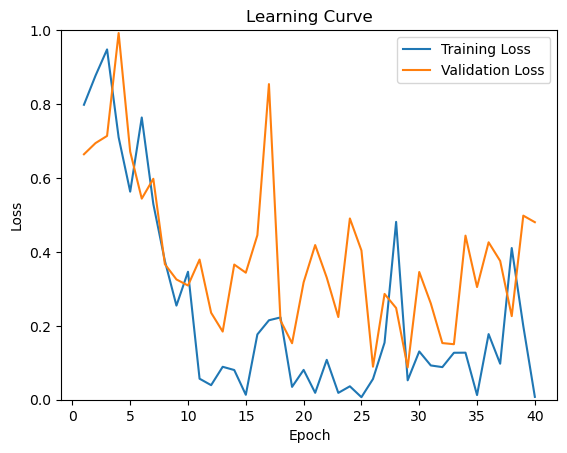

Fold 5
Accuracy Train: 0.8537500033155083. Accuracy valid: 0.7491666782647372
Recall Train: 0.7880208492279053. Recall valid: 0.7437499761581421
Precision Train: 0.77755206823349. Precision valid: 0.7408333450555802
Best Valid Accuracy Epoc: 18. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 2. Value = 1.0 Acc val = 0.533333346247673


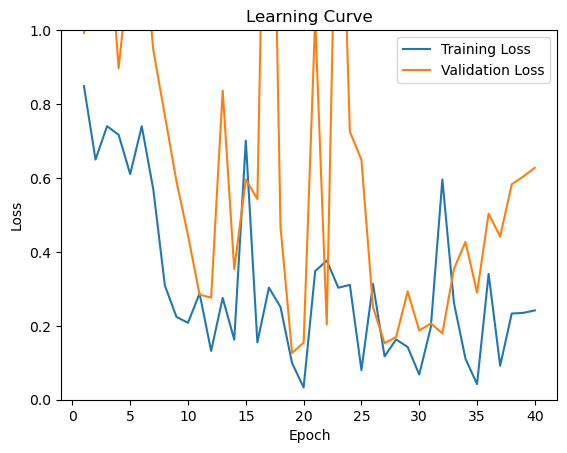

5
Fold 0: Training Loss: 0.19817688218317925, Validation Loss: 0.7164644993841648
Fold 1: Training Loss: 0.2165962596074678, Validation Loss: 0.4714242726797238
Fold 2: Training Loss: 0.16453413136769085, Validation Loss: 0.7712800579145551
Fold 3: Training Loss: 0.2394314113073051, Validation Loss: 0.3903269926086068
Fold 4: Training Loss: 0.31469950554892423, Validation Loss: 0.6251424362853868
TRAIN LOSS MEDIA: 0.22668763800291342 VALID LOSS MEDIA: 0.5949276517744875
TRAIN ACC MEDIA: 0.8940357176693423 VALID ACC MEDIA: 0.774833339266479
TRAIN RECALL MEDIA: 0.8574018478393555 VALID RECALL MEDIA: 0.7366666793823242
TRAIN PRECISION MEDIA: 0.8530937433242798 VALID PRECISION MEDIA: 0.785458338558674


In [ ]:
prueba_k_fold_resnet_pre_impr(df_mean, 5, 5, 35, optim.SGD, 5, 0.01, False, None)

Fold 1
Accuracy Train: 0.8914285750261375. Accuracy valid: 0.744375006109476
Recall Train: 0.8410714268684387. Recall valid: 0.48124998807907104
Precision Train: 0.8574404716491699. Precision valid: 0.9000000014901162
Best Valid Accuracy Epoc: 27. Value = 0.875 Recall val = 0.75
Best Valid Recall Epoc: 16. Value = 0.75 Acc val = 0.6500000059604645


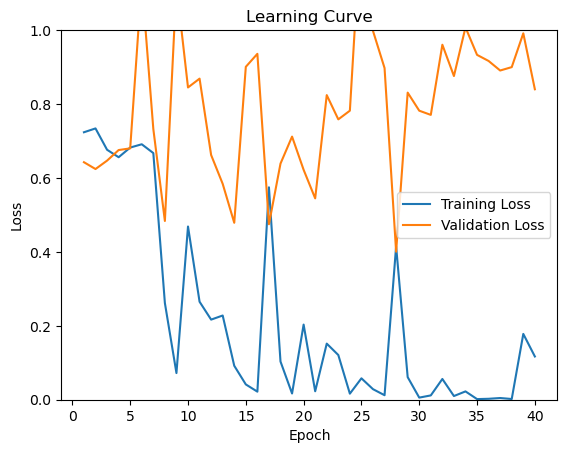

Fold 2
Accuracy Train: 0.8900000031505311. Accuracy valid: 0.8456250039860607
Recall Train: 0.8997618556022644. Recall valid: 0.8541666865348816
Precision Train: 0.8764880895614624. Precision valid: 0.8681249618530273
Best Valid Accuracy Epoc: 8. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.42500001192092896


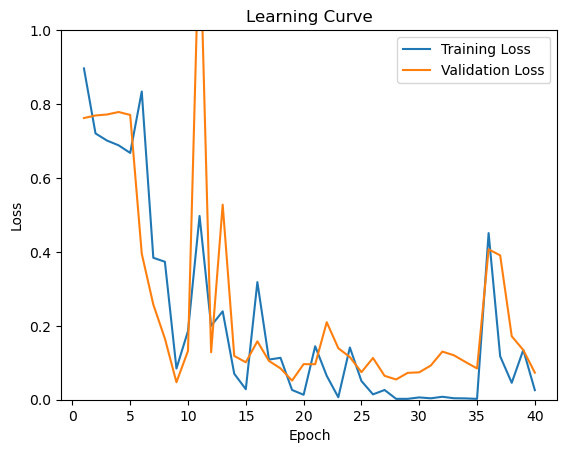

Fold 3
Accuracy Train: 0.917142861017159. Accuracy valid: 0.8187500016763807
Recall Train: 0.9040476083755493. Recall valid: 0.8041667938232422
Precision Train: 0.9196428060531616. Precision valid: 0.9254167675971985
Best Valid Accuracy Epoc: 9. Value = 0.9000000059604645 Recall val = 1.0
Best Valid Recall Epoc: 5. Value = 1.0 Acc val = 0.4750000014901161


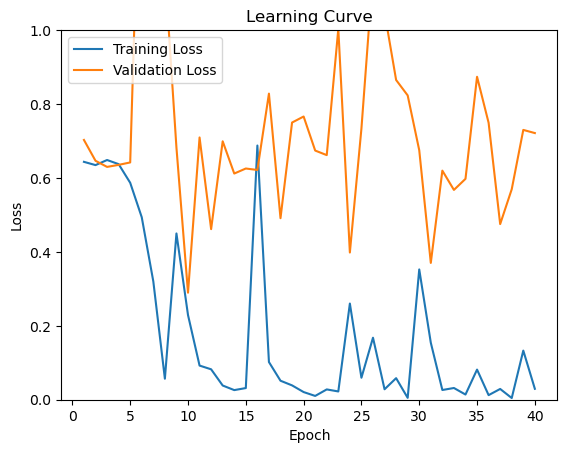

Fold 4
Accuracy Train: 0.9035714321902819. Accuracy valid: 0.8206250028684735
Recall Train: 0.8633333444595337. Recall valid: 0.9166666269302368
Precision Train: 0.882440447807312. Precision valid: 0.6972916722297668
Best Valid Accuracy Epoc: 9. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 2. Value = 1.0 Acc val = 0.7750000059604645


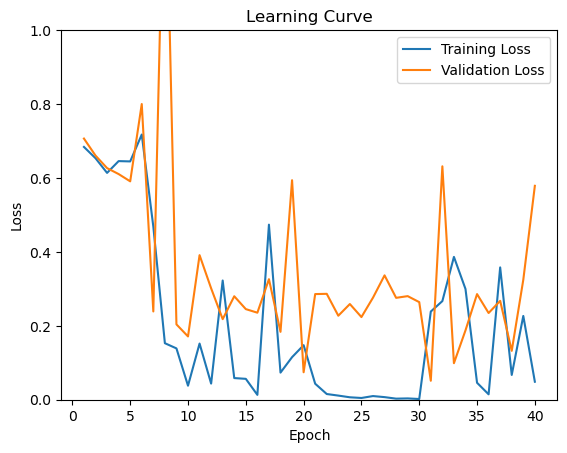

Fold 5
Accuracy Train: 0.8906250026077032. Accuracy valid: 0.7700000114738941
Recall Train: 0.7734895944595337. Recall valid: 0.7562500238418579
Precision Train: 0.7890625. Precision valid: 0.7737500160932541
Best Valid Accuracy Epoc: 8. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 5. Value = 1.0 Acc val = 0.7333333492279053


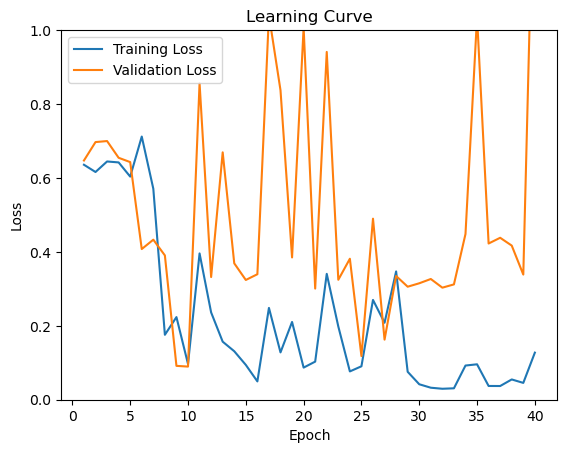

5
Fold 0: Training Loss: 0.21737192173604852, Validation Loss: 0.7917945688590408
Fold 1: Training Loss: 0.21016124940942973, Validation Loss: 0.2560455107013695
Fold 2: Training Loss: 0.18451575711369514, Validation Loss: 0.7268817315070919
Fold 3: Training Loss: 0.20680397596443073, Validation Loss: 0.36344875853974373
Fold 4: Training Loss: 0.22484328569844364, Validation Loss: 0.5052945112518501
TRAIN LOSS MEDIA: 0.20873923798440958 VALID LOSS MEDIA: 0.5286930161718193
TRAIN ACC MEDIA: 0.8985535747983626 VALID ACC MEDIA: 0.7998750052228569
TRAIN RECALL MEDIA: 0.8563407063484192 VALID RECALL MEDIA: 0.762499988079071
TRAIN PRECISION MEDIA: 0.8650148510932922 VALID PRECISION MEDIA: 0.8329166838526726


In [ ]:
prueba_k_fold_resnet_pre_impr(df_mean, 5, 5, 35, optim.RMSprop, 5, 0.0001, False, None)

#### CON TL Y OC

In [ ]:
####PRUEBA OPTIMA
###PRIMERO SE REDEFINE LA FUNCIÓN PARA QUE DEVUELVA VALORES EN VEZ DE LAS IMPRESIONES QUE HACE

def accuracy(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, consideramos que es positiva
    correct = (preds == labels.byte())  # Compara las predicciones con las etiquetas reales
    acc = correct.float().sum() / labels.size(0)  # Calcula la precisión
    return acc.item()

def recall(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()
    TP = sum((preds == 1) & (labels == 1))
    FN = sum((preds == 0) & (labels == 1))
    
    recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0
    return recall_score

def precision(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()

    TP = sum((preds == 1) & (labels == 1))
    FP = sum((preds == 1) & (labels == 0))
    
    precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0
    return precision_score



def prueba_k_fold_resnet_pre_oc_impr(dataset, num_folds, num_epochs_freeze, num_epochs_all, op, batch_size, lr, data_aug, ini):
    # Transformaciones para preprocesar las imágenes
    if data_aug:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            # v2.RandomResizedCrop(224),
            v2.RandomHorizontalFlip(),
            v2.RandomVerticalFlip(),
            # v2.ElasticTransform(alpha=250.0),
            # v2.RandomRotation(45),
            # transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    else:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    
    # Modelo personalizado basado en ResNet
    class CustomResNet(nn.Module):
        def __init__(self, num_classes_binary=1):
            super(CustomResNet, self).__init__()
            resnet = models.resnet18(weights='IMAGENET1K_V1')
            # Extraer las capas de la red ResNet, excluyendo la capa de clasificación
            self.features = nn.Sequential(*list(resnet.children())[:-1])

            # Congelar capas preentrenadas
            for param in self.features.parameters():
                param.requires_grad = False

            # Personalizar la capa de salida para tus necesidades
            self.fc_binary = nn.Linear(512, num_classes_binary)
            
            if (ini== "G"):
                # Inicialización de Glorot para las capas fully connected
                self.apply(self.init_weights_glorot)
            elif(ini == "H"):
                self.apply(self.init_weights_he)
            elif (ini== "N"):
                self.apply(self.init_weights_normal)
            elif(ini == "U"):
                self.apply(self.init_weights_uniform)
            elif (ini== "O"):
                self.apply(self.init_weights_orthogonal)
            elif(ini == "Z"):
                self.apply(self.init_weights_zeros)
            elif(ini == "ON"):
                self.apply(self.init_weights_ones)
       
        def init_weights_glorot(self, m):
            if isinstance(m, nn.Linear):
                init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_he(self, m):
            if isinstance(m, nn.Linear):
                init.kaiming_uniform_(m.weight, mode='fan_in', nonlinearity='relu')
                if m.bias is not None:
                    init.constant_(m.bias, 0)
        def init_weights_normal(self, m):
            if isinstance(m, nn.Linear):
                init.normal_(m.weight, mean=0, std=0.01)  
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_uniform(self, m):
            if isinstance(m, nn.Linear):
                init.uniform_(m.weight, a=-0.1, b=0.1)  
                if m.bias is not None:
                    init.constant_(m.bias, 0)
    
        def init_weights_orthogonal(self, m):
            if isinstance(m, nn.Linear):
                init.orthogonal_(m.weight)  
                if m.bias is not None:
                    init.constant_(m.bias, 0)
    
        def init_weights_zeros(self, m):
            if isinstance(m, nn.Linear):
                init.zeros_(m.weight)
                if m.bias is not None:
                    init.zeros_(m.bias)
    
        def init_weights_ones(self, m):
            if isinstance(m, nn.Linear):
                init.ones_(m.weight)
                if m.bias is not None:
                    init.ones_(m.bias)
    
        def forward(self, x):
            x = self.features(x)
            x = x.view(x.size(0), -1)
    
    
            # Salida para la variable binaria
            out_binary = self.fc_binary(x)
    
            return out_binary
    
    # Definir una clase para el conjunto de datos personalizado
    ##adaptar esto para meter unas rutsa y obtener dataos y etiquetas
    class CustomDataset(Dataset):
        def __init__(self, dataframe, transform=None):
            self.data = dataframe
            self.transform = transform
    
        def __len__(self):
            return len(self.data)
    
        def __getitem__(self, idx):
            img_path = self.data.iloc[idx, 0]  # Ruta de la imagen en la primera columna
            image = Image.open(img_path).convert('RGB')
            # Etiquetas: una variable binaria
            label_binary = torch.tensor(self.data.iloc[idx, 1], dtype=torch.float32)
    
            if self.transform:
                image = self.transform(image)
    
            return image, label_binary
        
    #####5 fold CV
    from sklearn.model_selection import StratifiedKFold
    
    # Definir el número de folds
    criterion_binary = nn.BCEWithLogitsLoss()
    kf = StratifiedKFold(n_splits=num_folds, shuffle=True, random_state=33)
    
    # Listas para almacenar las pérdidas de entrenamiento y validación de cada fold
    train_losses_folds = []
    val_losses_folds = []
    
    train_accs_folds = []
    train_rec_folds =  []
    train_preci_folds = []

    val_accs_folds = []
    val_rec_folds =  []
    val_preci_folds = []
    # Iterar sobre los folds
    for fold, (train_index, val_index) in enumerate(kf.split(np.zeros(len(dataset)),dataset['Etiqueta'])):
        print(f"Fold {fold + 1}")
    
        # Dividir el conjunto de datos en entrenamiento y validación para este fold
        train_data_fold = dataset.iloc[train_index]
        val_data_fold = dataset.iloc[val_index]
    
        # Crear instancias del conjunto de datos personalizado para este fold
        train_dataset_fold = CustomDataset(dataframe=train_data_fold, transform=transform_t)
        val_dataset_fold = CustomDataset(dataframe=val_data_fold, transform=transform_v)
    
        # Crear DataLoader para cargar los datos en lotes
        train_loader_fold = DataLoader(dataset=train_dataset_fold, batch_size=batch_size, shuffle=True)
        val_loader_fold = DataLoader(dataset=val_dataset_fold, batch_size=len(val_dataset_fold), shuffle=False) 
    
        # Re-inicializar el modelo para cada fold
        model = CustomResNet(num_classes_binary=1).to(device)

        optimizer = op([{'params': model.fc_binary.parameters()}, {'params': model.features.parameters()}], lr = lr)
        ##cuando estan congeladas las capas, solo quiero optimizar la fully connected
        optimizer2 = op( model.fc_binary.parameters(), lr = lr)


        # layer_names = []
        # for idx, (name, param) in enumerate(model.named_parameters()):
        #     layer_names.append(name)
        #     print(f'{idx}: {name}')
        # layer_names.reverse()
        # print('Segundo:', optimizer.param_groups[1])
        total = len(optimizer.param_groups)
        # print(total)
        scheduler1 = optim.lr_scheduler.OneCycleLR(optimizer2, max_lr=lr, steps_per_epoch=len(train_loader_fold), epochs=num_epochs_freeze)
        # Definir el objeto slice
        lr /= 2
        # lr_slice = slice(lr/100, lr)
        max_lrs = np.linspace(lr/100, lr, total)
        # print(lr_slice.start)
        # print(lr_slice.stop)
        max_lrs = max_lrs.tolist()
        scheduler2 = optim.lr_scheduler.OneCycleLR(optimizer, max_lr=max_lrs, steps_per_epoch=len(train_loader_fold), epochs=num_epochs_all)
        # Entrenamiento y validación para este fold
        train_losses_fold = []
        val_losses_fold = []
        train_accuracy_fold = []
        val_accuracy_fold = []
        train_recall_fold = []
        val_recall_fold = []
        train_preci_fold = []
        val_preci_fold = []

        for epoch in range(num_epochs_freeze):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            lossT_bin_total = 0.0
            correct_train = 0
            recall_value_train = 0
            precision_value_train = 0
            for images, bin_label in train_loader_fold:
                
                images, bin_label = images.to(device), bin_label.to(device)

                

                optimizer2.zero_grad()
        
                # Forward pass
                bin_out = model(images)
        
                # Calcular pérdida para las variables continuas
                
        
        
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
        
                # Pérdida total
                loss_total = lossT_bin
    
                loss_total_acumulada += loss_total
    
                # Backward pass y optimización
                loss_total.backward()
                optimizer2.step()
                scheduler1.step()
                

                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_train += accuracy(bin_pred, bin_label)
                recall_value_train += recall(bin_pred, bin_label)
                precision_value_train += precision(bin_pred, bin_label)

        
    
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            correct_valid = 0
            recall_value_valid = 0
            precision_value_valid = 0
            lossV_bin_total = 0.0
            with torch.no_grad():
                for images, bin_label in val_loader_fold:
                    # Reiniciar gradientes
                
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    ##print(len(images)) aqui se hace con 32 imagenes
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
    
    
    
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()

                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    correct_valid += accuracy(bin_pred, bin_label)
                    recall_value_valid += recall(bin_pred, bin_label)
                    precision_value_valid += precision(bin_pred, bin_label)
                    
            
            
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold)
            train_losses_fold.append(avg_loss_total_acumulada)
            acc_train = correct_train / len(train_loader_fold)
            recall_train = recall_value_train / len(train_loader_fold)
            precision_train = precision_value_train / len(train_loader_fold)
            train_accuracy_fold.append(acc_train)
            train_recall_fold.append(recall_train)
            train_preci_fold.append(precision_train)

            avg_val_loss = val_loss / len(val_loader_fold)
            val_losses_fold.append(avg_val_loss)
            acc_valid = correct_valid / len(val_loader_fold)
            recall_valid = recall_value_valid / len(val_loader_fold)
            precision_valid = precision_value_valid / len(val_loader_fold)
            val_accuracy_fold.append(acc_valid)
            val_recall_fold.append(recall_valid)
            val_preci_fold.append(precision_valid)

        ##Se descongelan todas
        for param in model.features.parameters():
            param.requires_grad = True
            
        for epoch in range(num_epochs_freeze, num_epochs_freeze + num_epochs_all):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            lossT_bin_total = 0.0
            correct_train = 0
            recall_value_train = 0
            precision_value_train = 0
            for images, bin_label in train_loader_fold:
                # Reiniciar gradientes
                

                images, bin_label = images.to(device), bin_label.to(device)

                optimizer.zero_grad()
        
                # Forward pass
                bin_out = model(images)
        
                # Calcular pérdida para las variables continuas
                
        
        
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
        
                # Pérdida total
                loss_total = lossT_bin
    
                loss_total_acumulada += loss_total
    
                # Backward pass y optimización
                loss_total.backward()
                optimizer.step()
                scheduler2.step()

                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_train += accuracy(bin_pred, bin_label)
                recall_value_train += recall(bin_pred, bin_label)
                precision_value_train += precision(bin_pred, bin_label)

        
    
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            correct_valid = 0
            recall_value_valid = 0
            precision_value_valid = 0
            lossV_bin_total = 0.0
            with torch.no_grad():
                for images, bin_label in val_loader_fold:
                    
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
        
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()

                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    correct_valid += accuracy(bin_pred, bin_label)
                    recall_value_valid += recall(bin_pred, bin_label)
                    precision_value_valid += precision(bin_pred, bin_label)

                    
                    
            
            
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold)
            train_losses_fold.append(avg_loss_total_acumulada)
            acc_train = correct_train / len(train_loader_fold)
            recall_train = recall_value_train / len(train_loader_fold)
            precision_train = precision_value_train / len(train_loader_fold)
            train_accuracy_fold.append(acc_train)
            train_recall_fold.append(recall_train)
            train_preci_fold.append(precision_train)
        
            avg_val_loss = val_loss / len(val_loader_fold)
            val_losses_fold.append(avg_val_loss)
            acc_valid = correct_valid / len(val_loader_fold)
            recall_valid = recall_value_valid / len(val_loader_fold)
            precision_valid = precision_value_valid / len(val_loader_fold)
            val_accuracy_fold.append(acc_valid)
            val_recall_fold.append(recall_valid)
            val_preci_fold.append(precision_valid)
            # print(f'Epoch [{epoch+1}/{num_epochs}], Training Loss: {avg_loss_total_acumulada.item()}, Validation Loss: {avg_val_loss}')
        
        print(f"Accuracy Train: {np.mean(train_accuracy_fold)}. Accuracy valid: {np.mean(val_accuracy_fold)}")
        print(f"Recall Train: {np.mean(train_recall_fold)}. Recall valid: {np.mean(val_recall_fold)}")
        print(f"Precision Train: {np.mean(train_preci_fold)}. Precision valid: {np.mean(val_preci_fold)}")
        print(f'Best Valid Accuracy Epoc: {np.argmax(val_accuracy_fold)}. Value = {val_accuracy_fold[np.argmax(val_accuracy_fold)]} Recall val = {val_recall_fold[np.argmax(val_accuracy_fold)]}')
        print(f'Best Valid Recall Epoc: {np.argmax(val_recall_fold)}. Value = {val_recall_fold[np.argmax(val_recall_fold)]} Acc val = {val_accuracy_fold[np.argmax(val_recall_fold)]}')
        train_accs_folds.append(np.mean(train_accuracy_fold))
        train_rec_folds.append(np.mean(train_recall_fold))
        train_preci_folds.append(np.mean(train_preci_fold))

        val_accs_folds.append(np.mean(val_accuracy_fold))
        val_rec_folds.append(np.mean(val_recall_fold))
        val_preci_folds.append(np.mean(val_preci_fold))

        train_losses_folds.append(train_losses_fold)
        val_losses_folds.append(val_losses_fold)
        train_losses_fold = [i.cpu().detach().numpy() for i in train_losses_fold]
        learning_curve(train_losses_fold, val_losses_fold)


        
    
    train_losses_folds_cpu = []
    val_losses_folds_cpu = []
    for losses in val_losses_folds:
        val_losses_fold_cpu = []
        for loss in losses:
            val_losses_fold_cpu.append(loss)
        val_losses_folds_cpu.append(np.array(val_losses_fold_cpu))
    for losses in train_losses_folds:
        train_losses_fold_cpu = []
        for loss in losses:
            train_losses_fold_cpu.append(float(loss.cpu().detach().numpy()))
        train_losses_folds_cpu.append(np.array(train_losses_fold_cpu))
    print(len(train_losses_folds_cpu))
    avg_train = []
    avg_val = []
    for losses in train_losses_folds_cpu:
        avg_train.append(np.mean(losses))
    for losses in val_losses_folds_cpu:
        avg_val.append(np.mean(losses))
    
    # Imprimir pérdidas promedio para cada época
    for fold, (train_loss, val_loss) in enumerate(zip(avg_train, avg_val)):
        print(f"Fold {fold}: Training Loss: {train_loss}, Validation Loss: {val_loss}")
    
    print(f"TRAIN LOSS MEDIA: {np.mean(avg_train)} VALID LOSS MEDIA: {np.mean(avg_val)}")
    print(f"TRAIN ACC MEDIA: {np.mean(train_accs_folds)} VALID ACC MEDIA: {np.mean(val_accs_folds)}")        
    print(f"TRAIN RECALL MEDIA: {np.mean(train_rec_folds)} VALID RECALL MEDIA: {np.mean(val_rec_folds)}")
    print(f"TRAIN PRECISION MEDIA: {np.mean(train_preci_folds)} VALID PRECISION MEDIA: {np.mean(val_preci_folds)}")      

Fold 1
Accuracy Train: 0.8985714322222131. Accuracy valid: 0.6975000072270632
Recall Train: 0.8771429061889648. Recall valid: 0.44999998807907104
Precision Train: 0.87541663646698. Precision valid: 0.7537500023841858
Best Valid Accuracy Epoc: 5. Value = 0.7750000059604645 Recall val = 0.5
Best Valid Recall Epoc: 21. Value = 1.0 Acc val = 0.7000000029802322


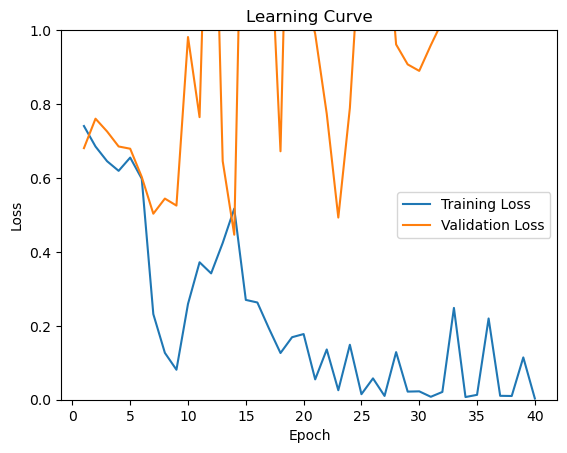

Fold 2
Accuracy Train: 0.9042857182877405. Accuracy valid: 0.85125000346452
Recall Train: 0.8297023773193359. Recall valid: 0.7875000238418579
Precision Train: 0.8595238108187914. Precision valid: 0.8125000014901161
Best Valid Accuracy Epoc: 9. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 9. Value = 1.0 Acc val = 1.0


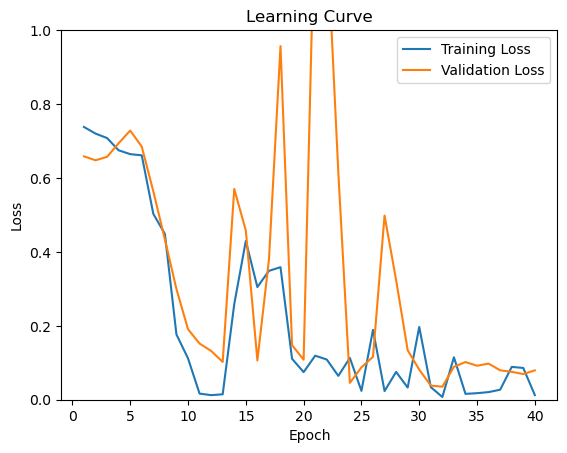

Fold 3
Accuracy Train: 0.9135714317538909. Accuracy valid: 0.7631250007078052
Recall Train: 0.9063690900802612. Recall valid: 0.7750000953674316
Precision Train: 0.9058332443237305. Precision valid: 0.8731249570846558
Best Valid Accuracy Epoc: 14. Value = 0.9000000059604645 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.4750000014901161


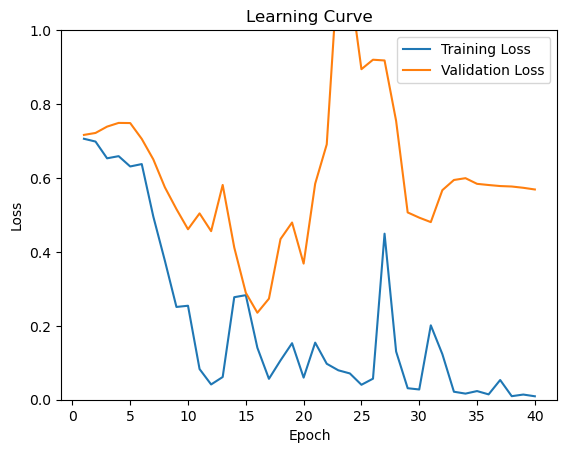

Fold 4
Accuracy Train: 0.8900000037891524. Accuracy valid: 0.8562500007450581
Recall Train: 0.8681547045707703. Recall valid: 0.8583332896232605
Precision Train: 0.8608928918838501. Precision valid: 0.7093750238418579
Best Valid Accuracy Epoc: 16. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 7. Value = 1.0 Acc val = 0.875


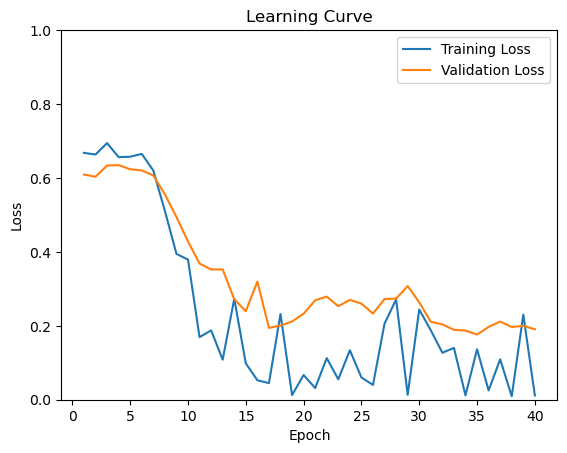

Fold 5
Accuracy Train: 0.854375003091991. Accuracy valid: 0.8133333422243595
Recall Train: 0.6817708611488342. Recall valid: 0.675000011920929
Precision Train: 0.721875011920929. Precision valid: 0.7375000059604645
Best Valid Accuracy Epoc: 15. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 15. Value = 1.0 Acc val = 1.0


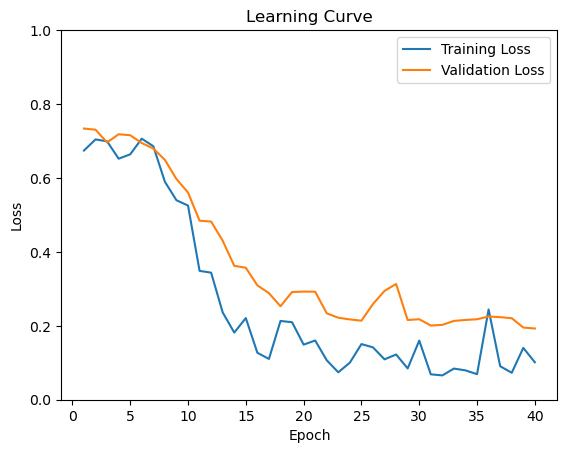

5
Fold 0: Training Loss: 0.21934000226901845, Validation Loss: 0.9966992307454348
Fold 1: Training Loss: 0.21769183644792064, Validation Loss: 0.34960855467943475
Fold 2: Training Loss: 0.20624043827410787, Validation Loss: 0.6096734041770105
Fold 3: Training Loss: 0.2328050365904346, Validation Loss: 0.32997000915929675
Fold 4: Training Loss: 0.27019345946609974, Validation Loss: 0.3728073430247605
TRAIN LOSS MEDIA: 0.2292541546095163 VALID LOSS MEDIA: 0.5317517083571874
TRAIN ACC MEDIA: 0.8921607178289976 VALID ACC MEDIA: 0.7962916708737613
TRAIN RECALL MEDIA: 0.832628071308136 VALID RECALL MEDIA: 0.7091666460037231
TRAIN PRECISION MEDIA: 0.8447083190828562 VALID PRECISION MEDIA: 0.777249998152256
Fold 1
Accuracy Train: 0.8151041701436043. Accuracy valid: 0.5944444607943297
Recall Train: 0.8110004663467407. Recall valid: 0.706250011920929
Precision Train: 0.7932230234146118. Precision valid: 0.625
Best Valid Accuracy Epoc: 33. Value = 0.7777777910232544 Recall val = 0.5
Best Valid Re

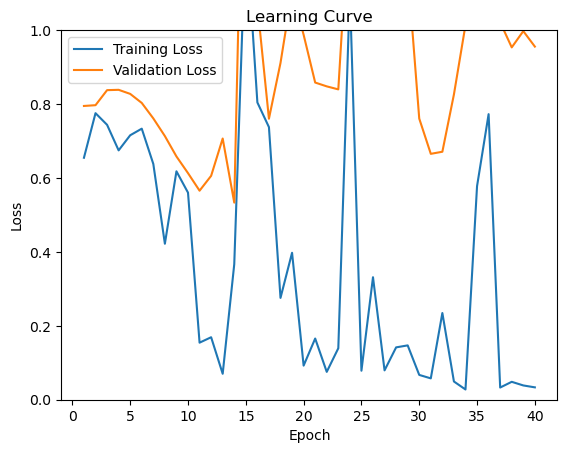

Fold 2
Accuracy Train: 0.7972656287252903. Accuracy valid: 0.7777777910232544
Recall Train: 0.8337796926498413. Recall valid: 0.8187500238418579
Precision Train: 0.7880100011825562. Precision valid: 0.7266666293144226
Best Valid Accuracy Epoc: 12. Value = 0.8888888955116272 Recall val = 0.75
Best Valid Recall Epoc: 17. Value = 1.0 Acc val = 0.5555555820465088


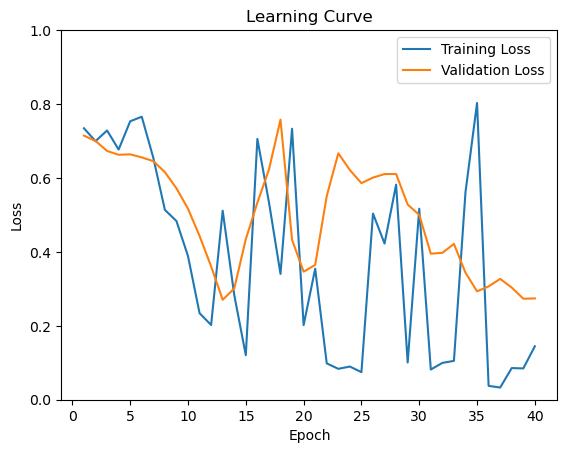

Fold 3
Accuracy Train: 0.8404947955161333. Accuracy valid: 0.7888888992369175
Recall Train: 0.7282365560531616. Recall valid: 0.581250011920929
Precision Train: 0.8459375500679016. Precision valid: 0.7562500007450581
Best Valid Accuracy Epoc: 13. Value = 0.8888888955116272 Recall val = 0.75
Best Valid Recall Epoc: 10. Value = 0.75 Acc val = 0.7777777910232544


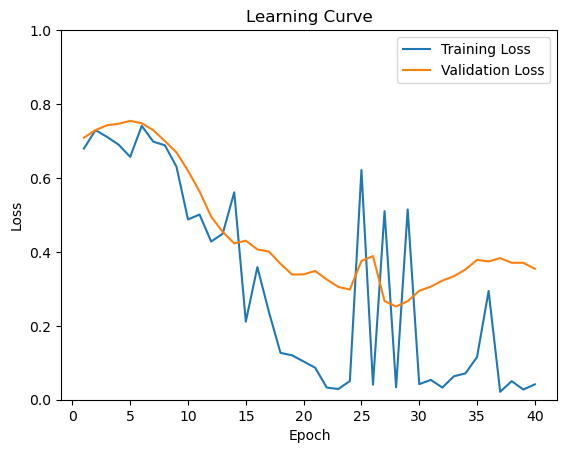

Fold 4
Accuracy Train: 0.8651041693985462. Accuracy valid: 0.7750000122934579
Recall Train: 0.8007217645645142. Recall valid: 0.574999988079071
Precision Train: 0.8214967846870422. Precision valid: 0.6745833352208137
Best Valid Accuracy Epoc: 23. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 14. Value = 1.0 Acc val = 0.8888888955116272


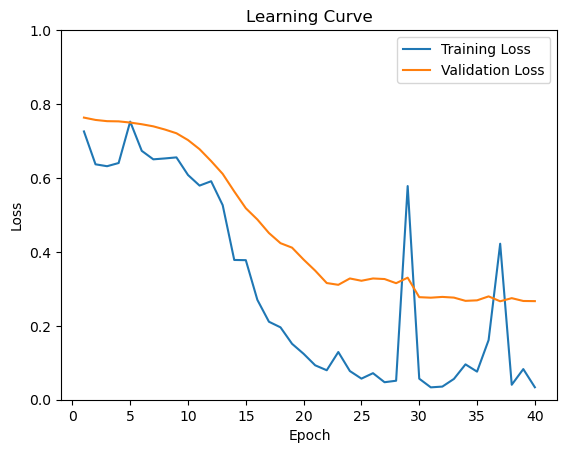

Fold 5
Accuracy Train: 0.80546875. Accuracy valid: 0.840625
Recall Train: 0.8146600723266602. Recall valid: 0.887499988079071
Precision Train: 0.7775312662124634. Precision valid: 0.8842262029647827
Best Valid Accuracy Epoc: 11. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.5


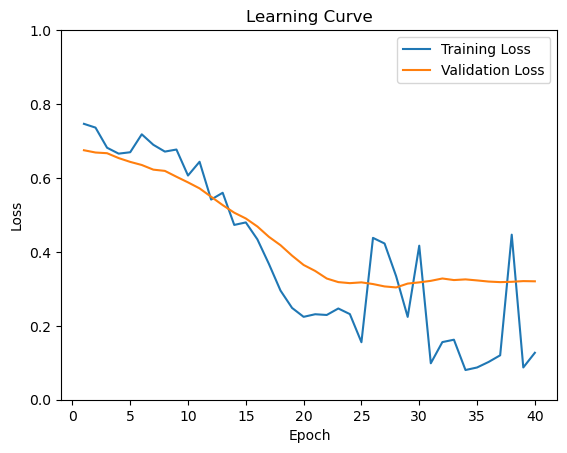

5
Fold 0: Training Loss: 0.3772534660063684, Validation Loss: 0.9903422757983208
Fold 1: Training Loss: 0.37820896664634346, Validation Loss: 0.4974563278257847
Fold 2: Training Loss: 0.31362019586376844, Validation Loss: 0.45086942315101625
Fold 3: Training Loss: 0.30781361255794765, Validation Loss: 0.4627588585019112
Fold 4: Training Loss: 0.38819309789687395, Validation Loss: 0.437614144384861
TRAIN LOSS MEDIA: 0.35301786779426036 VALID LOSS MEDIA: 0.5678082059323788
TRAIN ACC MEDIA: 0.8246875027567148 VALID ACC MEDIA: 0.7553472326695919
TRAIN RECALL MEDIA: 0.7976797223091125 VALID RECALL MEDIA: 0.7137500047683716
TRAIN PRECISION MEDIA: 0.8052396774291992 VALID PRECISION MEDIA: 0.7333452336490154


In [ ]:
prueba_k_fold_resnet_pre_oc_impr(df_mean, 5, 5, 35, optim.Adam, 5, 0.001, False, None)
prueba_k_fold_resnet_pre_oc_impr(df_mean, 5, 5, 35, optim.Adam, 32, 0.001, True, None)

Fold 1
Accuracy Train: 0.8842857186283386. Accuracy valid: 0.6943750057369471
Recall Train: 0.87541663646698. Recall valid: 0.5562499761581421
Precision Train: 0.8677380681037903. Precision valid: 0.7954166688024997
Best Valid Accuracy Epoc: 17. Value = 0.875 Recall val = 0.75
Best Valid Recall Epoc: 7. Value = 1.0 Acc val = 0.6500000059604645


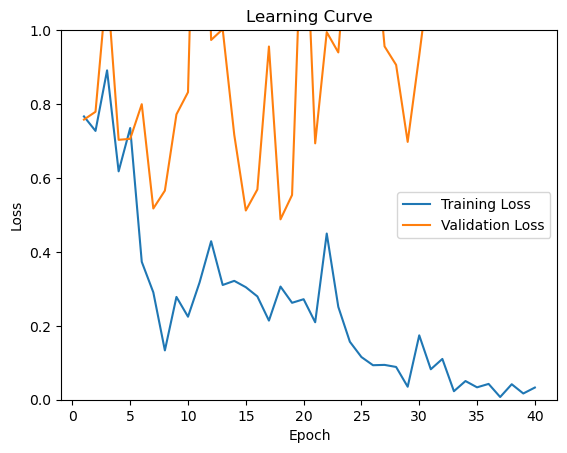

Fold 2
Accuracy Train: 0.9057142898440361. Accuracy valid: 0.7962500020861626
Recall Train: 0.9006547927856445. Recall valid: 0.9583333730697632
Precision Train: 0.8923808932304382. Precision valid: 0.6854166731238365
Best Valid Accuracy Epoc: 15. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 3. Value = 1.0 Acc val = 0.75


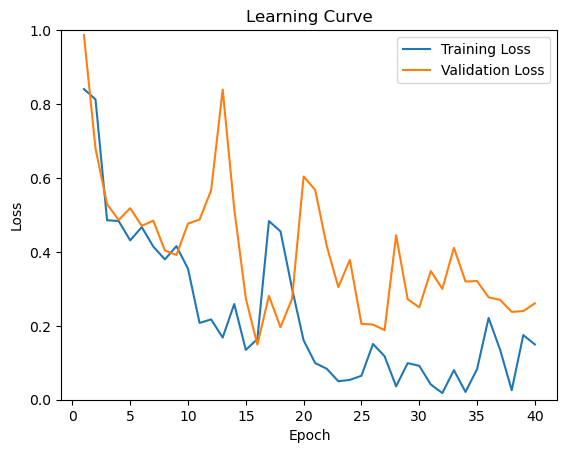

Fold 3
Accuracy Train: 0.8950000035975659. Accuracy valid: 0.8275000005960464
Recall Train: 0.8532142639160156. Recall valid: 0.7583333849906921
Precision Train: 0.8941667675971985. Precision valid: 0.925
Best Valid Accuracy Epoc: 6. Value = 0.875 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 6. Value = 0.8333333730697632 Acc val = 0.875


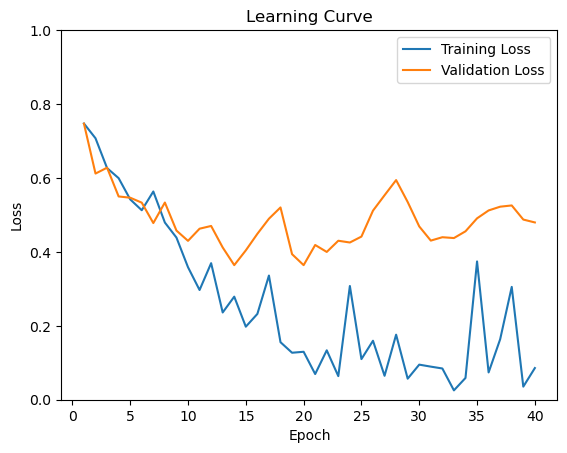

Fold 4
Accuracy Train: 0.8835714331695013. Accuracy valid: 0.760000005364418
Recall Train: 0.8357143402099609. Recall valid: 0.7916666269302368
Precision Train: 0.8836309313774109. Precision valid: 0.5843750238418579
Best Valid Accuracy Epoc: 10. Value = 0.875 Recall val = 0.5
Best Valid Recall Epoc: 4. Value = 1.0 Acc val = 0.800000011920929


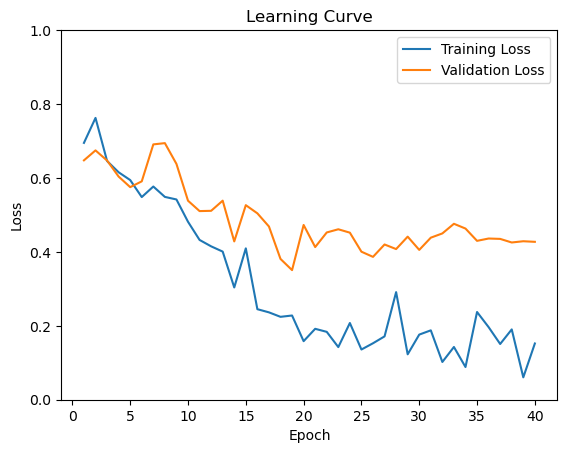

Fold 5
Accuracy Train: 0.8231250055599958. Accuracy valid: 0.807500009983778
Recall Train: 0.6857291460037231. Recall valid: 0.7437499761581421
Precision Train: 0.7361979484558105. Precision valid: 0.9154166713356972
Best Valid Accuracy Epoc: 19. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.7000000029802322


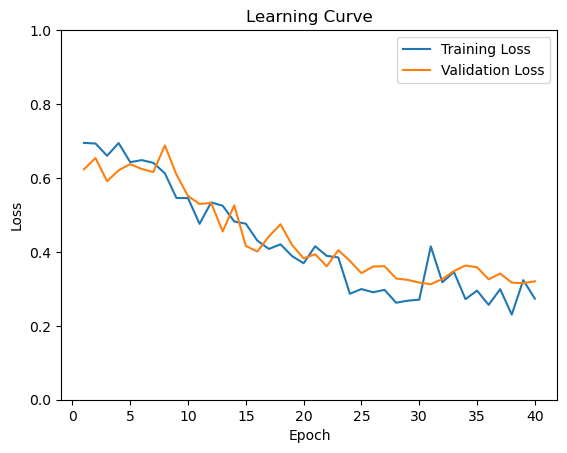

5
Fold 0: Training Loss: 0.2541019677533768, Validation Loss: 0.9695490606129169
Fold 1: Training Loss: 0.23579863654449582, Validation Loss: 0.3957473938819021
Fold 2: Training Loss: 0.2617056336253881, Validation Loss: 0.48511751759797334
Fold 3: Training Loss: 0.3086932959035039, Validation Loss: 0.49107500463724135
Fold 4: Training Loss: 0.4270374603569508, Validation Loss: 0.44225919209420683
TRAIN LOSS MEDIA: 0.29746739883674306 VALID LOSS MEDIA: 0.5567496337648481
TRAIN ACC MEDIA: 0.8783392901598877 VALID ACC MEDIA: 0.7771250047534705
TRAIN RECALL MEDIA: 0.8301458358764648 VALID RECALL MEDIA: 0.7616666555404663
TRAIN PRECISION MEDIA: 0.8548229336738586 VALID PRECISION MEDIA: 0.7811250074207783


In [ ]:
prueba_k_fold_resnet_pre_oc_impr(df_mean, 5, 5, 35, optim.SGD, 5, 0.01, True, None)

Fold 1
Accuracy Train: 0.9078571455819265. Accuracy valid: 0.7225000061094761
Recall Train: 0.8479166030883789. Recall valid: 0.45625001192092896
Precision Train: 0.8797618746757507. Precision valid: 0.866666667163372
Best Valid Accuracy Epoc: 7. Value = 0.7750000059604645 Recall val = 0.5
Best Valid Recall Epoc: 6. Value = 0.5 Acc val = 0.675000011920929


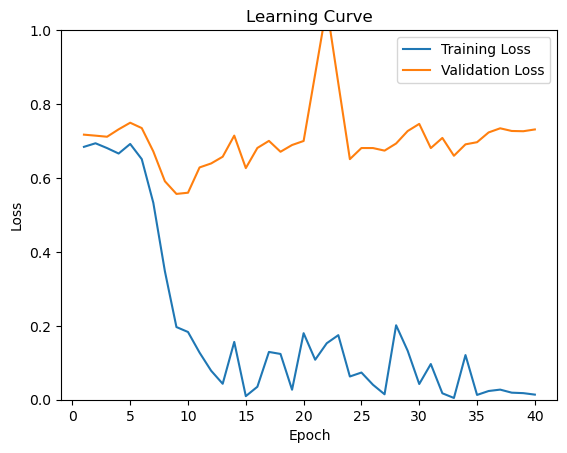

Fold 2
Accuracy Train: 0.9092857177236251. Accuracy valid: 0.8018750047311187
Recall Train: 0.8860713839530945. Recall valid: 0.8999999761581421
Precision Train: 0.8751190304756165. Precision valid: 0.7729166746139526
Best Valid Accuracy Epoc: 11. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 8. Value = 1.0 Acc val = 0.9000000059604645


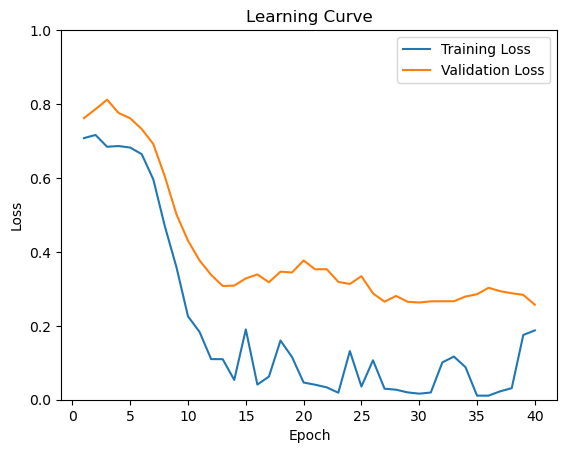

Fold 3
Accuracy Train: 0.8785714313387871. Accuracy valid: 0.7325000004842878
Recall Train: 0.9035714864730835. Recall valid: 0.7875000834465027
Precision Train: 0.8591071963310242. Precision valid: 0.8570833206176758
Best Valid Accuracy Epoc: 13. Value = 0.875 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.4750000014901161


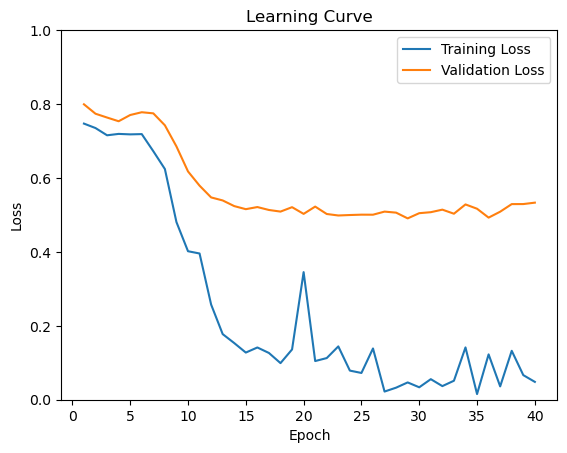

Fold 4
Accuracy Train: 0.8671428613364697. Accuracy valid: 0.7375000022351742
Recall Train: 0.70291668176651. Recall valid: 0.574999988079071
Precision Train: 0.7428571451455355. Precision valid: 0.475
Best Valid Accuracy Epoc: 21. Value = 0.875 Recall val = 1.0
Best Valid Recall Epoc: 21. Value = 1.0 Acc val = 0.875


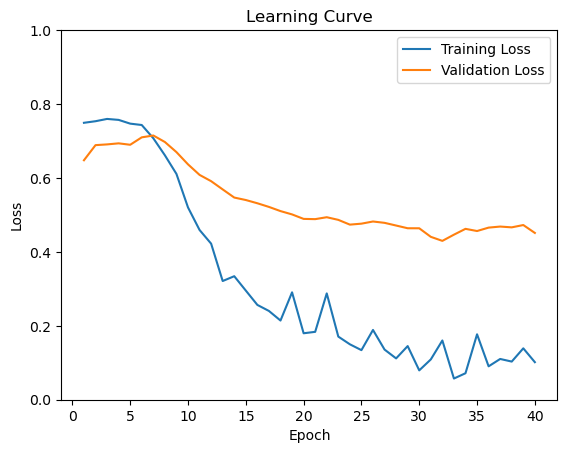

Fold 5
Accuracy Train: 0.8325000043958426. Accuracy valid: 0.6291666839271783
Recall Train: 0.5913541913032532. Recall valid: 0.29374998807907104
Precision Train: 0.64375. Precision valid: 0.5
Best Valid Accuracy Epoc: 26. Value = 0.8333333432674408 Recall val = 0.75
Best Valid Recall Epoc: 26. Value = 0.75 Acc val = 0.8333333432674408


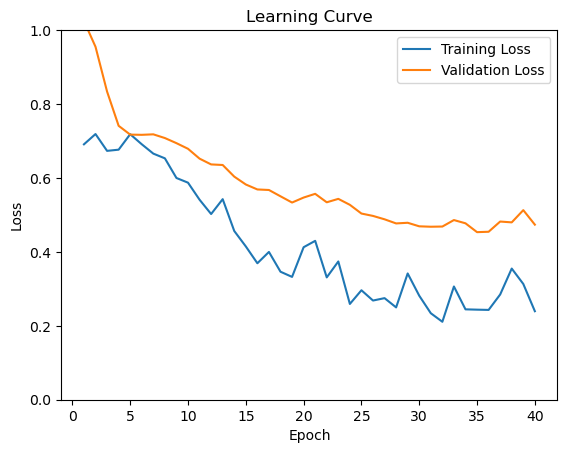

5
Fold 0: Training Loss: 0.18991521223215385, Validation Loss: 0.7045173708349466
Fold 1: Training Loss: 0.20218529398553073, Validation Loss: 0.4015822861343622
Fold 2: Training Loss: 0.24962975857779385, Validation Loss: 0.5732341595925391
Fold 3: Training Loss: 0.318251936044544, Validation Loss: 0.5397294167429209
Fold 4: Training Loss: 0.4193577580153942, Validation Loss: 0.5874357480555773
TRAIN LOSS MEDIA: 0.2758679917710833 VALID LOSS MEDIA: 0.5612997962720692
TRAIN ACC MEDIA: 0.8790714320753302 VALID ACC MEDIA: 0.724708339497447
TRAIN RECALL MEDIA: 0.7863660454750061 VALID RECALL MEDIA: 0.6025000810623169
TRAIN PRECISION MEDIA: 0.8001190493255853 VALID PRECISION MEDIA: 0.6943333324790001
Fold 1
Accuracy Train: 0.7911458376795053. Accuracy valid: 0.6722222365438938
Recall Train: 0.6360926032066345. Recall valid: 0.53125
Precision Train: 0.6710854157805443. Precision valid: 0.6733134932816028
Best Valid Accuracy Epoc: 9. Value = 0.8888888955116272 Recall val = 0.75
Best Valid Re

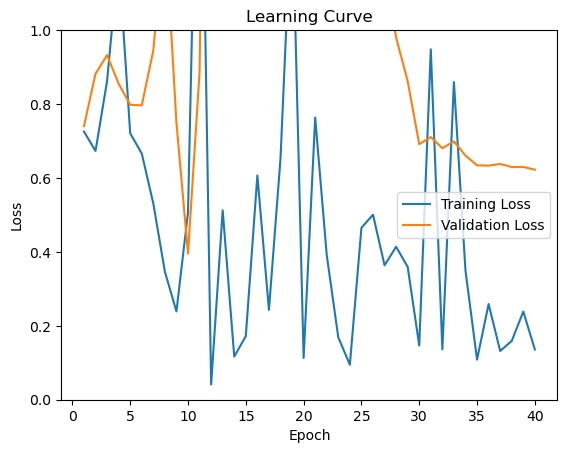

Fold 2
Accuracy Train: 0.8571614619344473. Accuracy valid: 0.8638888970017433
Recall Train: 0.768603503704071. Recall valid: 0.78125
Precision Train: 0.8042647119611501. Precision valid: 0.7316666707396507
Best Valid Accuracy Epoc: 15. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 9. Value = 1.0 Acc val = 0.8888888955116272


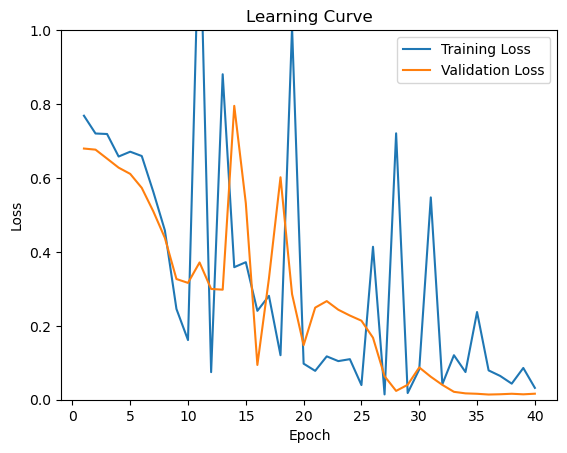

Fold 3
Accuracy Train: 0.8541666701436043. Accuracy valid: 0.7416666805744171
Recall Train: 0.7259374856948853. Recall valid: 0.612500011920929
Precision Train: 0.7393191661685705. Precision valid: 0.8494246602058411
Best Valid Accuracy Epoc: 9. Value = 0.8888888955116272 Recall val = 0.75
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.4444444477558136


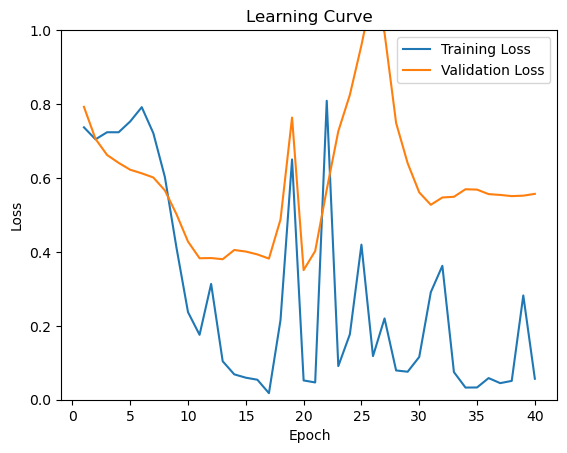

Fold 4
Accuracy Train: 0.8217447955161333. Accuracy valid: 0.6388889029622078
Recall Train: 0.7825870513916016. Recall valid: 0.762499988079071
Precision Train: 0.7886649370193481. Precision valid: 0.5179960422217846
Best Valid Accuracy Epoc: 36. Value = 0.8888888955116272 Recall val = 1.0
Best Valid Recall Epoc: 11. Value = 1.0 Acc val = 0.6666666865348816


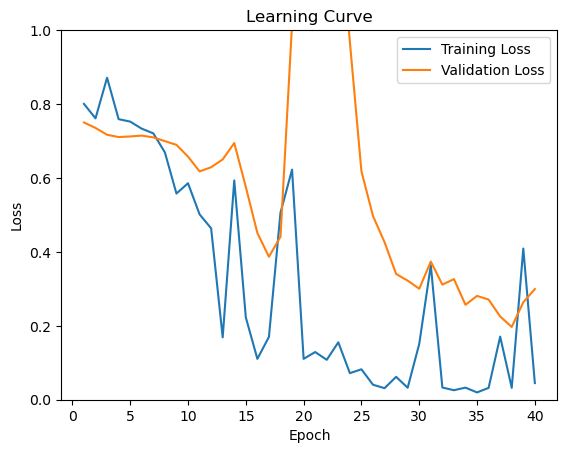

Fold 5
Accuracy Train: 0.829296875. Accuracy valid: 0.7625
Recall Train: 0.9125635027885437. Recall valid: 0.956250011920929
Precision Train: 0.8174079656600952. Precision valid: 0.7584523558616638
Best Valid Accuracy Epoc: 27. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.5


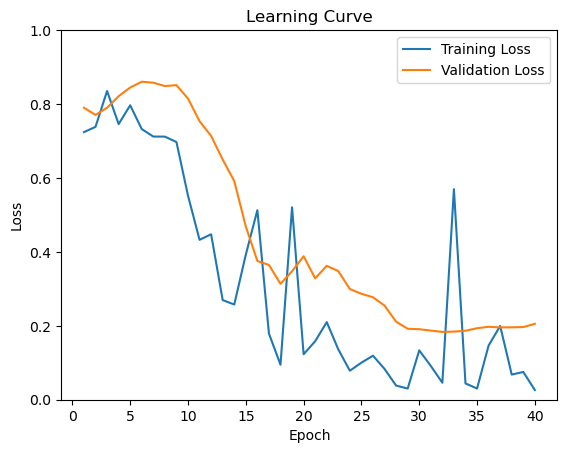

5
Fold 0: Training Loss: 0.4803038276731968, Validation Loss: 1.836020292341709
Fold 1: Training Loss: 0.335562076093629, Validation Loss: 0.27451804222073406
Fold 2: Training Loss: 0.2888918683398515, Validation Loss: 0.5881650164723397
Fold 3: Training Loss: 0.3177297477610409, Validation Loss: 0.631816889718175
Fold 4: Training Loss: 0.32150921449065206, Validation Loss: 0.44730189740657805
TRAIN LOSS MEDIA: 0.348799346871674 VALID LOSS MEDIA: 0.7555644276319071
TRAIN ACC MEDIA: 0.8307031280547381 VALID ACC MEDIA: 0.7358333434164525
TRAIN RECALL MEDIA: 0.7651568651199341 VALID RECALL MEDIA: 0.7287499904632568
TRAIN PRECISION MEDIA: 0.7641484393179416 VALID PRECISION MEDIA: 0.7061706444621085


In [ ]:
prueba_k_fold_resnet_pre_oc_impr(df_mean, 5, 5, 35, optim.RMSprop, 5, 1e-5, False, None)
prueba_k_fold_resnet_pre_oc_impr(df_mean, 5, 5, 35, optim.RMSprop, 32, 0.0001, True, None)

### MOSAIC

Se usan las mismas funciones pero con el dataset Mosaic

#### SIN TL NI OC

Fold 1
Accuracy Train: 0.9614285733018603. Accuracy valid: 0.7225000064820051
Recall Train: 0.9619047045707703. Recall valid: 0.737500011920929
Precision Train: 0.9574404954910278. Precision valid: 0.783333420753479
Best Valid Accuracy Epoc: 7. Value = 0.7750000059604645 Recall val = 0.5
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.5750000029802322


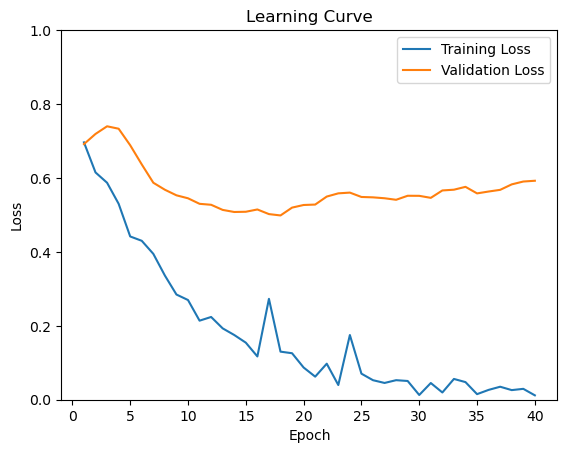

Fold 2
Accuracy Train: 0.9492857165102448. Accuracy valid: 0.7837500112131238
Recall Train: 0.8541070818901062. Recall valid: 0.6625000238418579
Precision Train: 0.885714289918542. Precision valid: 0.9491666674613952
Best Valid Accuracy Epoc: 4. Value = 0.800000011920929 Recall val = 0.6666666865348816
Best Valid Recall Epoc: 1. Value = 1.0 Acc val = 0.675000011920929


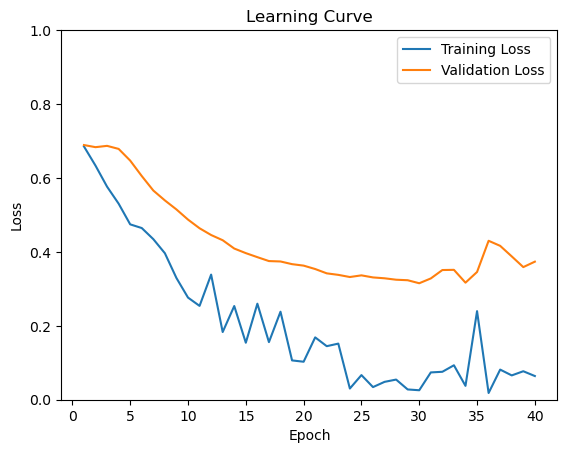

Fold 3
Accuracy Train: 0.9421428596334799. Accuracy valid: 0.7412500008940697
Recall Train: 0.8684523701667786. Recall valid: 0.6499999761581421
Precision Train: 0.9071428596973419. Precision valid: 0.9166666671633721
Best Valid Accuracy Epoc: 26. Value = 0.875 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 3. Value = 0.8333333730697632 Acc val = 0.675000011920929


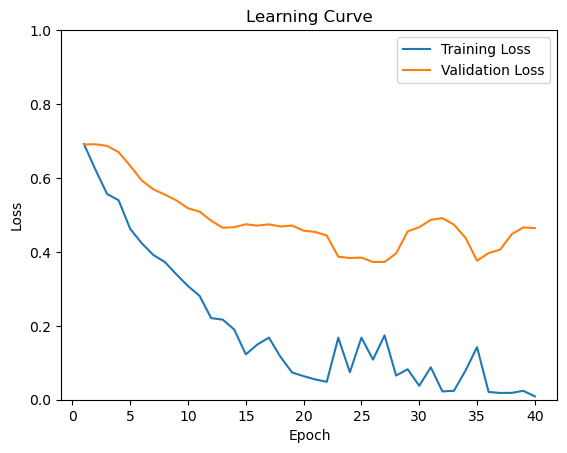

Fold 4
Accuracy Train: 0.921428574462022. Accuracy valid: 0.6837500046938658
Recall Train: 0.8117262721061707. Recall valid: 0.4333333373069763
Precision Train: 0.8571428604424. Precision valid: 0.3668750002980232
Best Valid Accuracy Epoc: 7. Value = 0.875 Recall val = 0.5
Best Valid Recall Epoc: 31. Value = 1.0 Acc val = 0.675000011920929


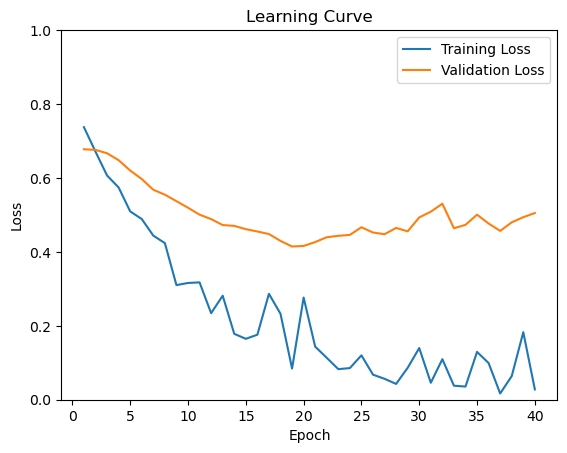

Fold 5
Accuracy Train: 0.9200000017881393. Accuracy valid: 0.7425000090152025
Recall Train: 0.8978124856948853. Recall valid: 0.7875000238418579
Precision Train: 0.8418229818344116. Precision valid: 0.8612499237060547
Best Valid Accuracy Epoc: 6. Value = 0.8333333432674408 Recall val = 0.75
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.533333346247673


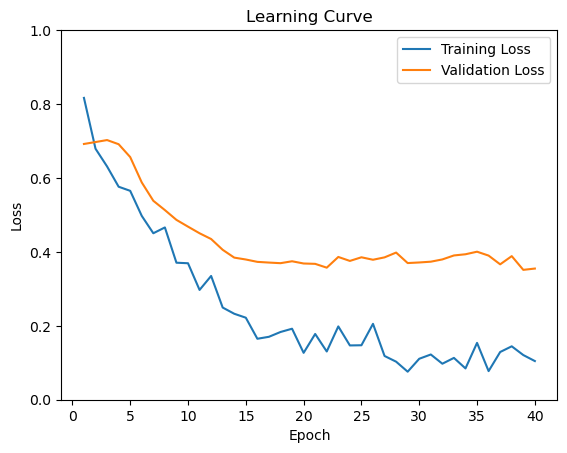

5
Fold 0: Training Loss: 0.18128244632389395, Validation Loss: 0.5701380837708712
Fold 1: Training Loss: 0.21065699108876287, Validation Loss: 0.4273108190856874
Fold 2: Training Loss: 0.19340971142519264, Validation Loss: 0.4863390041515231
Fold 3: Training Loss: 0.22502524708397686, Validation Loss: 0.5011992536485195
Fold 4: Training Loss: 0.2539439104497433, Validation Loss: 0.4377175909932703
TRAIN LOSS MEDIA: 0.21286366127431391 VALID LOSS MEDIA: 0.48454095032997424
TRAIN ACC MEDIA: 0.9388571451391492 VALID ACC MEDIA: 0.7347500064596535
TRAIN RECALL MEDIA: 0.8788005709648132 VALID RECALL MEDIA: 0.6541666984558105
TRAIN PRECISION MEDIA: 0.8898526974767446 VALID PRECISION MEDIA: 0.7754583358764648
Fold 1
Accuracy Train: 0.9642857155629567. Accuracy valid: 0.776875002682209
Recall Train: 0.9536905288696289. Recall valid: 0.7250000238418579
Precision Train: 0.9572619199752808. Precision valid: 0.8700000017881393
Best Valid Accuracy Epoc: 4. Value = 0.875 Recall val = 0.75
Best Valid 

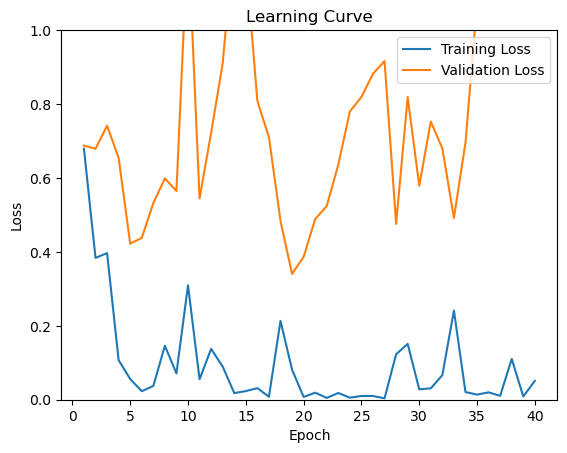

Fold 2
Accuracy Train: 0.9585714302957058. Accuracy valid: 0.8425000064074993
Recall Train: 0.9475000500679016. Recall valid: 0.8166667222976685
Precision Train: 0.9539285898208618. Precision valid: 0.8389583364129066
Best Valid Accuracy Epoc: 6. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 1. Value = 1.0 Acc val = 0.675000011920929


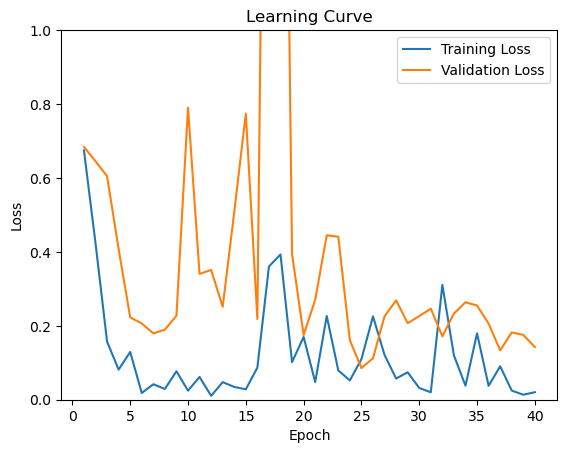

Fold 3
Accuracy Train: 0.9642857157226121. Accuracy valid: 0.781250000372529
Recall Train: 0.9401785731315613. Recall valid: 0.8000000715255737
Precision Train: 0.9436904788017273. Precision valid: 0.8631250262260437
Best Valid Accuracy Epoc: 6. Value = 0.875 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.4750000014901161


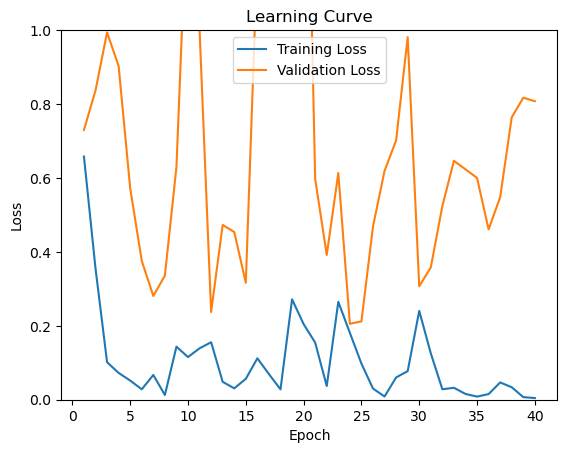

Fold 4
Accuracy Train: 0.9614285729825497. Accuracy valid: 0.7162500061094761
Recall Train: 0.9495833516120911. Recall valid: 0.8291667103767395
Precision Train: 0.9429166913032532. Precision valid: 0.56270831823349
Best Valid Accuracy Epoc: 21. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.42500001192092896


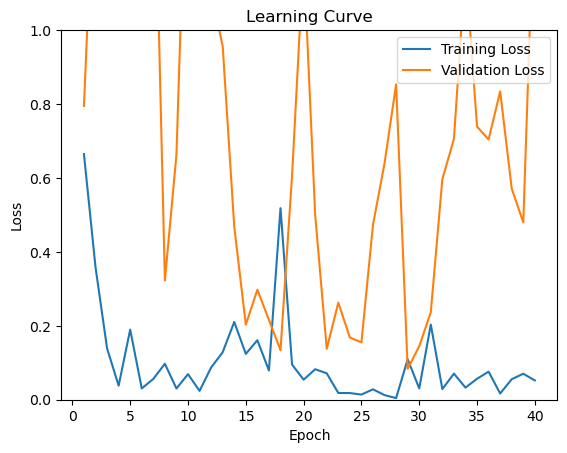

Fold 5
Accuracy Train: 0.9487500012852251. Accuracy valid: 0.7516666766256094
Recall Train: 0.8191666603088379. Recall valid: 0.800000011920929
Precision Train: 0.8374999761581421. Precision valid: 0.8524999618530273
Best Valid Accuracy Epoc: 0. Value = 0.8333333432674408 Recall val = 0.75
Best Valid Recall Epoc: 1. Value = 1.0 Acc val = 0.533333346247673


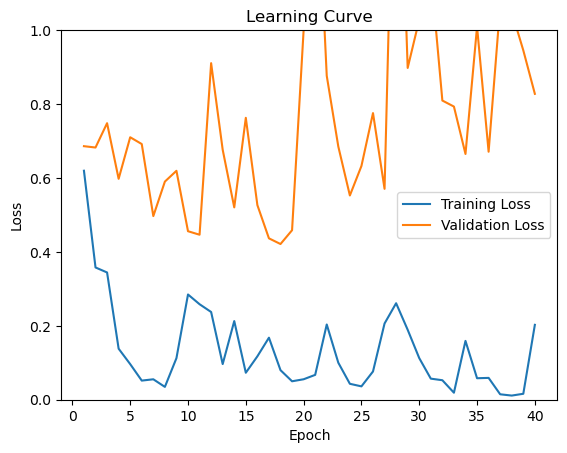

5
Fold 0: Training Loss: 0.09559073295677081, Validation Loss: 0.7487573365680873
Fold 1: Training Loss: 0.12081203223206102, Validation Loss: 0.4408250562803005
Fold 2: Training Loss: 0.10477380850352347, Validation Loss: 0.7103254651767201
Fold 3: Training Loss: 0.10517961195437238, Validation Loss: 0.8102968526771293
Fold 4: Training Loss: 0.13472119383513928, Validation Loss: 0.7698409965261817
TRAIN LOSS MEDIA: 0.1122154758963734 VALID LOSS MEDIA: 0.6960091414456837
TRAIN ACC MEDIA: 0.9594642871698099 VALID ACC MEDIA: 0.7737083384394646
TRAIN RECALL MEDIA: 0.9220237731933594 VALID RECALL MEDIA: 0.7941666841506958
TRAIN PRECISION MEDIA: 0.927059531211853 VALID PRECISION MEDIA: 0.7974583289027214


In [ ]:
prueba_k_fold_resnet_no_pre_impr(df_mosaic, 5, 40, optim.Adam, 5, 1e-5, False, None)
prueba_k_fold_resnet_no_pre_impr(df_mosaic, 5, 40, optim.Adam, 5, 0.0001, False, None)

Fold 1
Accuracy Train: 0.9142857179577861. Accuracy valid: 0.7812500033527613
Recall Train: 0.8774404525756836. Recall valid: 0.668749988079071
Precision Train: 0.8939285278320312. Precision valid: 0.8058333396911621
Best Valid Accuracy Epoc: 13. Value = 0.875 Recall val = 0.75
Best Valid Recall Epoc: 2. Value = 1.0 Acc val = 0.45000000298023224


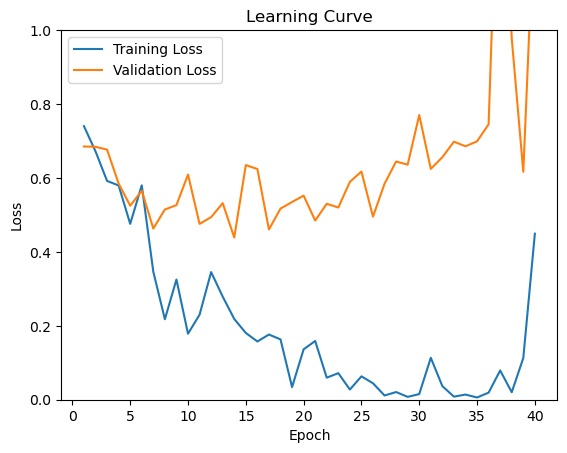

Fold 2
Accuracy Train: 0.8964285751006432. Accuracy valid: 0.8712500058114528
Recall Train: 0.8677976727485657. Recall valid: 0.800000011920929
Precision Train: 0.8738095164299011. Precision valid: 0.9293750002980232
Best Valid Accuracy Epoc: 4. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 4. Value = 1.0 Acc val = 1.0


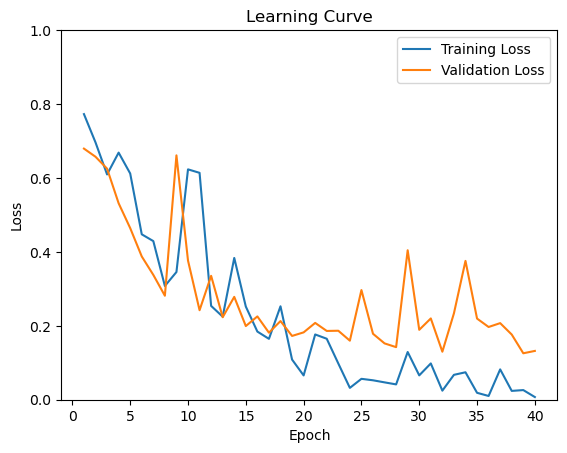

Fold 3
Accuracy Train: 0.8878571471465486. Accuracy valid: 0.7375000009313226
Recall Train: 0.8539880514144897. Recall valid: 0.7083333730697632
Precision Train: 0.8510118722915649. Precision valid: 0.7585416667163372
Best Valid Accuracy Epoc: 8. Value = 0.9000000059604645 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.4750000014901161


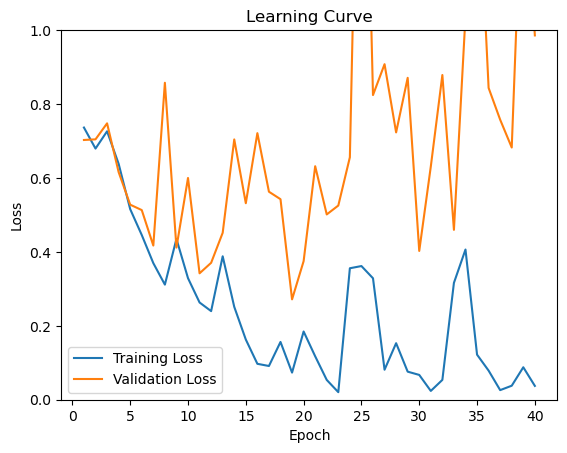

Fold 4
Accuracy Train: 0.8585714333823748. Accuracy valid: 0.7000000044703484
Recall Train: 0.8177381753921509. Recall valid: 0.5791667103767395
Precision Train: 0.8297023773193359. Precision valid: 0.4437500014901161
Best Valid Accuracy Epoc: 7. Value = 0.875 Recall val = 0.5
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.42500001192092896


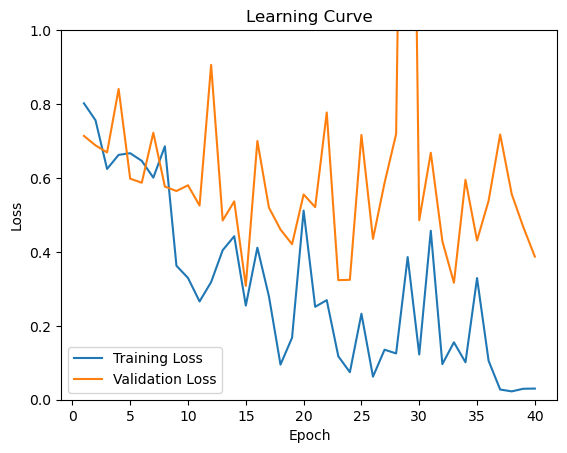

Fold 5
Accuracy Train: 0.8225000040605664. Accuracy valid: 0.7016666773706675
Recall Train: 0.7162500619888306. Recall valid: 0.675000011920929
Precision Train: 0.73395836353302. Precision valid: 0.681666673719883
Best Valid Accuracy Epoc: 11. Value = 0.8333333432674408 Recall val = 0.75
Best Valid Recall Epoc: 6. Value = 1.0 Acc val = 0.533333346247673


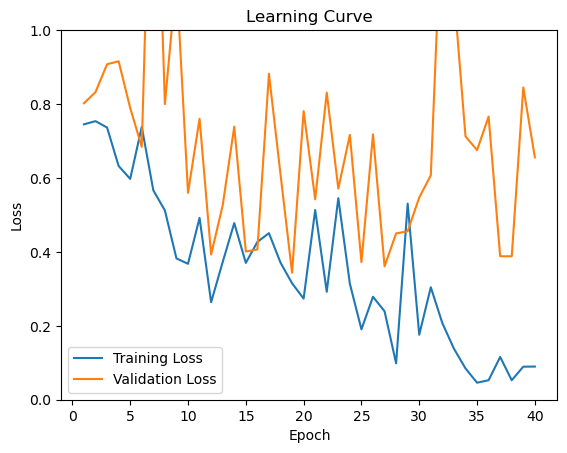

5
Fold 0: Training Loss: 0.1992249304195866, Validation Loss: 0.6425850749015808
Fold 1: Training Loss: 0.23283230025554075, Validation Loss: 0.28438248532474975
Fold 2: Training Loss: 0.247467989474535, Validation Loss: 0.7098008594795828
Fold 3: Training Loss: 0.3104826811701059, Validation Loss: 0.62186434478499
Fold 4: Training Loss: 0.35510632656514646, Validation Loss: 0.7032109174935612
TRAIN LOSS MEDIA: 0.2690228455769829 VALID LOSS MEDIA: 0.5923687363968929
TRAIN ACC MEDIA: 0.8759285755295838 VALID ACC MEDIA: 0.7583333383873104
TRAIN RECALL MEDIA: 0.8266428112983704 VALID RECALL MEDIA: 0.6862500309944153
TRAIN PRECISION MEDIA: 0.8364821672439575 VALID PRECISION MEDIA: 0.7238333363831043


In [ ]:
prueba_k_fold_resnet_no_pre_impr(df_mosaic, 5, 40, optim.SGD, 5, 0.01, False, None)

Fold 1
Accuracy Train: 0.9607142875769309. Accuracy valid: 0.8112500011920929
Recall Train: 0.9349405169487. Recall valid: 0.7562500238418579
Precision Train: 0.9339284896850586. Precision valid: 0.9108333587646484
Best Valid Accuracy Epoc: 5. Value = 0.875 Recall val = 0.75
Best Valid Recall Epoc: 1. Value = 1.0 Acc val = 0.45000000298023224


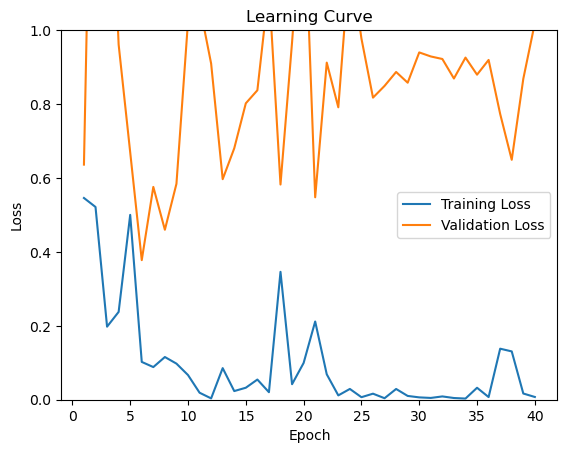

Fold 2
Accuracy Train: 0.9492857163505894. Accuracy valid: 0.9125000022351741
Recall Train: 0.9164880514144897. Recall valid: 0.987500011920929
Precision Train: 0.92291659116745. Precision valid: 0.9143750071525574
Best Valid Accuracy Epoc: 3. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.42500001192092896


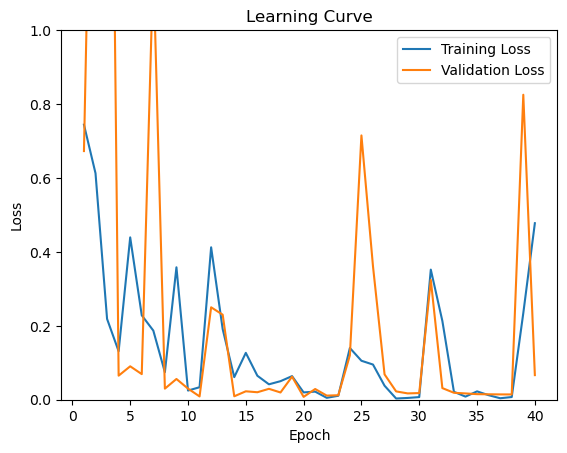

Fold 3
Accuracy Train: 0.9535714304872922. Accuracy valid: 0.800000000372529
Recall Train: 0.9355953335762024. Recall valid: 0.7791666984558105
Precision Train: 0.9446428418159485. Precision valid: 0.9122917056083679
Best Valid Accuracy Epoc: 1. Value = 0.875 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.4750000014901161


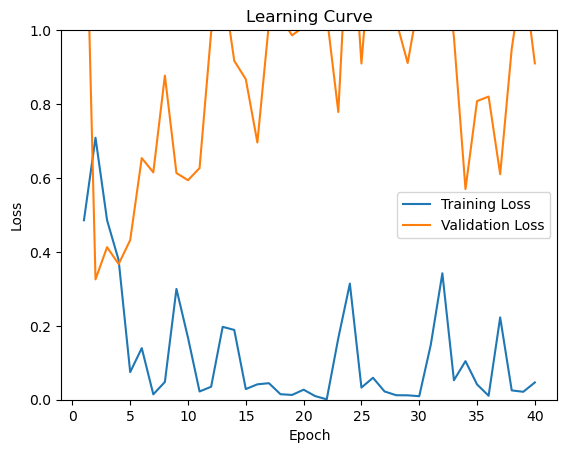

Fold 4
Accuracy Train: 0.9464285737701825. Accuracy valid: 0.7375000063329935
Recall Train: 0.9129167795181274. Recall valid: 0.95416659116745
Precision Train: 0.9192261695861816. Precision valid: 0.6122916340827942
Best Valid Accuracy Epoc: 18. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.42500001192092896


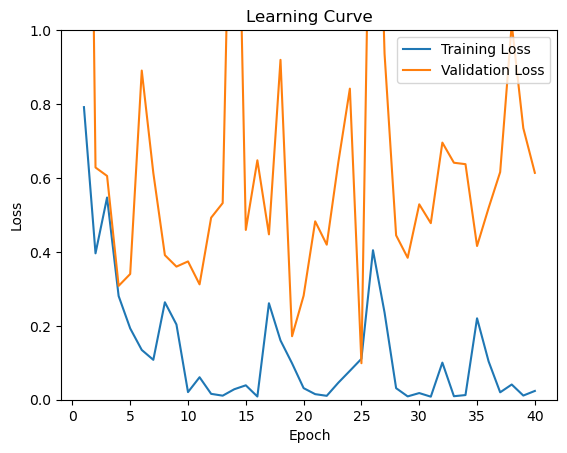

Fold 5
Accuracy Train: 0.9237500020302832. Accuracy valid: 0.682500010728836
Recall Train: 0.841249942779541. Recall valid: 0.7749999761581421
Precision Train: 0.83697909116745. Precision valid: 0.7458333432674408
Best Valid Accuracy Epoc: 5. Value = 0.8333333432674408 Recall val = 0.75
Best Valid Recall Epoc: 1. Value = 1.0 Acc val = 0.533333346247673


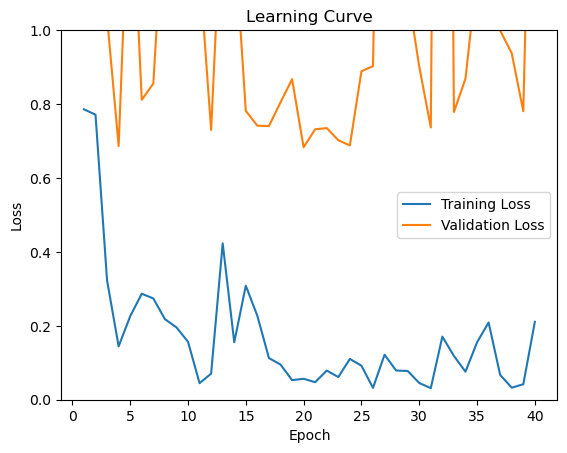

5
Fold 0: Training Loss: 0.0986984331801068, Validation Loss: 0.8915476050460711
Fold 1: Training Loss: 0.14671851209714076, Validation Loss: 0.26798801584664034
Fold 2: Training Loss: 0.1268118087638868, Validation Loss: 0.9140239743854182
Fold 3: Training Loss: 0.12908940510824324, Validation Loss: 0.6785156019614078
Fold 4: Training Loss: 0.16967058815062047, Validation Loss: 1.1569435090903426
TRAIN LOSS MEDIA: 0.1341977494599996 VALID LOSS MEDIA: 0.781803741265976
TRAIN ACC MEDIA: 0.9467500020430556 VALID ACC MEDIA: 0.7887500041723252
TRAIN RECALL MEDIA: 0.9082381129264832 VALID RECALL MEDIA: 0.8504166603088379
TRAIN PRECISION MEDIA: 0.9115386009216309 VALID PRECISION MEDIA: 0.8191250097751617
Fold 1
Accuracy Train: 0.9770833338300389. Accuracy valid: 0.6916666761040687
Recall Train: 0.9484127163887024. Recall valid: 0.75
Precision Train: 0.9666666984558105. Precision valid: 0.7295833349227905
Best Valid Accuracy Epoc: 21. Value = 0.8888888955116272 Recall val = 0.75
Best Valid Re

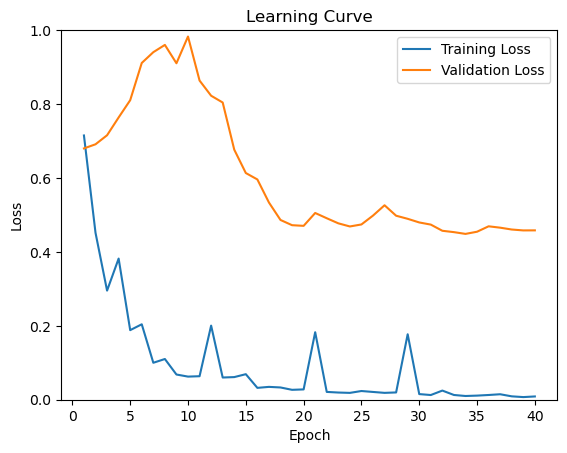

Fold 2
Accuracy Train: 0.9767361119389534. Accuracy valid: 0.8361111149191857
Recall Train: 0.9602777361869812. Recall valid: 0.9375
Precision Train: 0.9494792222976685. Precision valid: 0.82972222417593
Best Valid Accuracy Epoc: 13. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 1. Value = 1.0 Acc val = 0.7777777910232544


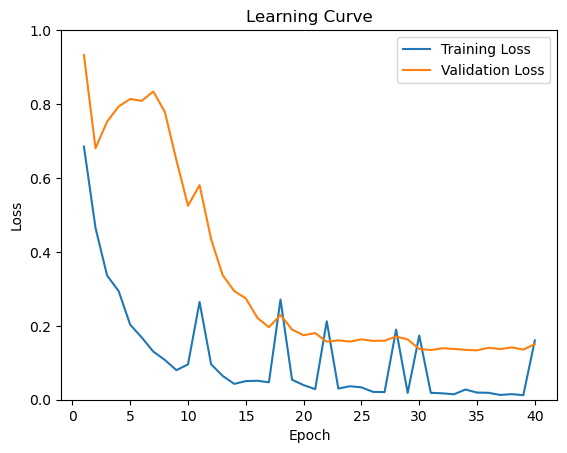

Fold 3
Accuracy Train: 0.9711805564661822. Accuracy valid: 0.8277777872979641
Recall Train: 0.955208420753479. Recall valid: 0.643750011920929
Precision Train: 0.9791666865348816. Precision valid: 0.9111111111938953
Best Valid Accuracy Epoc: 2. Value = 0.8888888955116272 Recall val = 0.75
Best Valid Recall Epoc: 1. Value = 1.0 Acc val = 0.4444444477558136


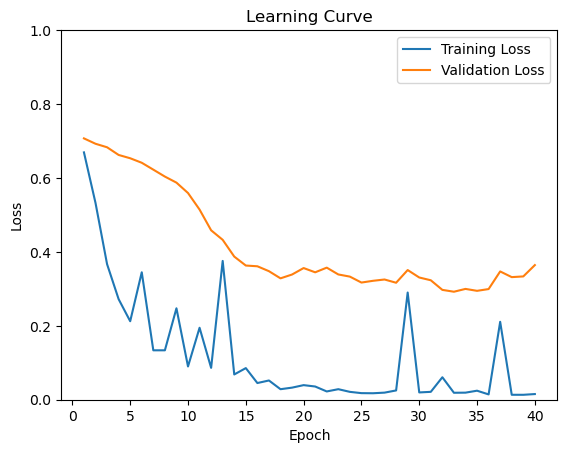

Fold 4
Accuracy Train: 0.9739583338300388. Accuracy valid: 0.708333345502615
Recall Train: 0.8988790512084961. Recall valid: 0.90625
Precision Train: 0.9229167103767395. Precision valid: 0.642896831035614
Best Valid Accuracy Epoc: 21. Value = 0.8888888955116272 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.4444444477558136


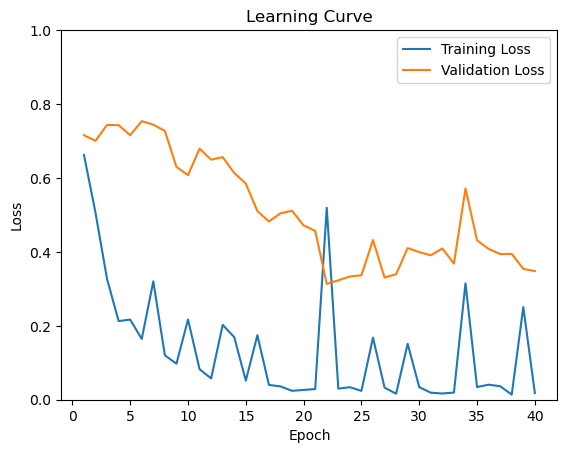

Fold 5
Accuracy Train: 0.9744791666666666. Accuracy valid: 0.69375
Recall Train: 0.9659723043441772. Recall valid: 0.8187500238418579
Precision Train: 0.9621362686157227. Precision valid: 0.7084524035453796
Best Valid Accuracy Epoc: 15. Value = 0.875 Recall val = 0.75
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.5


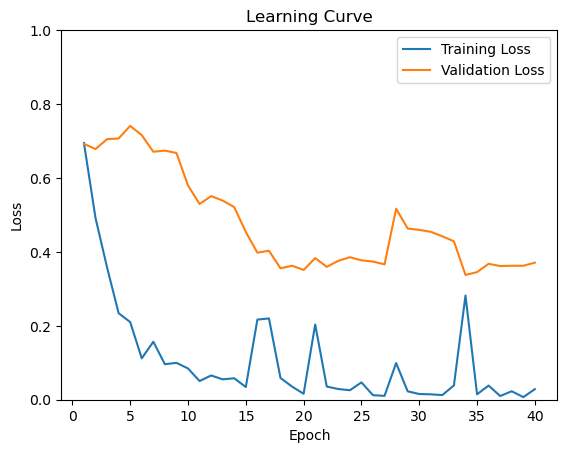

5
Fold 0: Training Loss: 0.09568696825299412, Validation Loss: 0.6052639998495579
Fold 1: Training Loss: 0.11568633939605207, Validation Loss: 0.3372591037303209
Fold 2: Training Loss: 0.12298541918862611, Validation Loss: 0.42049012556672094
Fold 3: Training Loss: 0.1377869566436857, Validation Loss: 0.5122324801981449
Fold 4: Training Loss: 0.10797195817576721, Validation Loss: 0.4797424539923668
TRAIN LOSS MEDIA: 0.11602352833142504 VALID LOSS MEDIA: 0.4709976326674223
TRAIN ACC MEDIA: 0.974687500546376 VALID ACC MEDIA: 0.7515277847647667
TRAIN RECALL MEDIA: 0.9457500576972961 VALID RECALL MEDIA: 0.8112500309944153
TRAIN PRECISION MEDIA: 0.9560731053352356 VALID PRECISION MEDIA: 0.7643531809747219


In [ ]:
prueba_k_fold_resnet_no_pre_impr(df_mosaic, 5, 40, optim.RMSprop, 5, 0.0001, False, None)
prueba_k_fold_resnet_no_pre_impr(df_mosaic, 5, 40, optim.RMSprop, 16, 1e-5, False, None)

#### SIN TL CON OC

Fold 1
Accuracy Train: 0.9357142878962413. Accuracy valid: 0.7868750028312206
Recall Train: 0.8863095045089722. Recall valid: 0.6187499761581421
Precision Train: 0.9130952954292297. Precision valid: 0.9125000238418579
Best Valid Accuracy Epoc: 5. Value = 0.875 Recall val = 0.75
Best Valid Recall Epoc: 13. Value = 1.0 Acc val = 0.875


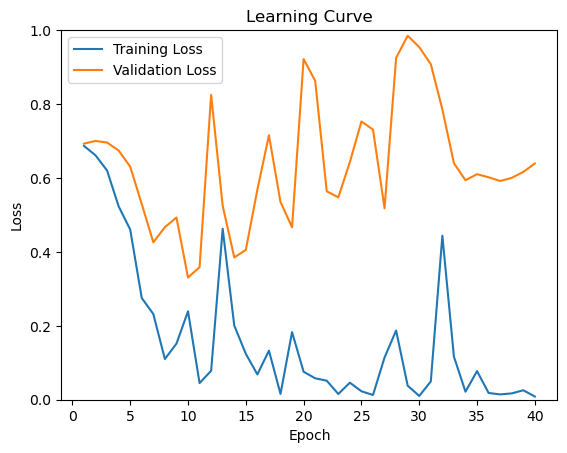

Fold 2
Accuracy Train: 0.9442857162228652. Accuracy valid: 0.8556250046938658
Recall Train: 0.9011904001235962. Recall valid: 0.7666667103767395
Precision Train: 0.9244047630578279. Precision valid: 0.839583334326744
Best Valid Accuracy Epoc: 27. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 16. Value = 1.0 Acc val = 0.75


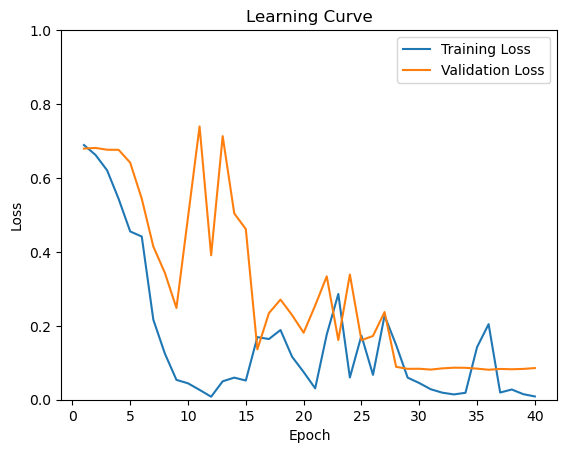

Fold 3
Accuracy Train: 0.9392857164676702. Accuracy valid: 0.8006250005215406
Recall Train: 0.940595269203186. Recall valid: 0.7375000715255737
Precision Train: 0.9225000143051147. Precision valid: 0.875
Best Valid Accuracy Epoc: 6. Value = 0.875 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 13. Value = 1.0 Acc val = 0.5750000029802322


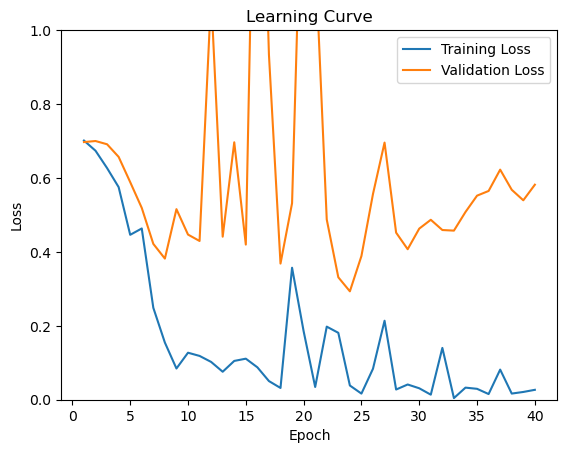

Fold 4
Accuracy Train: 0.9578571447836502. Accuracy valid: 0.6993750084191561
Recall Train: 0.928928554058075. Recall valid: 0.908333420753479
Precision Train: 0.9607143402099609. Precision valid: 0.5620833419263362
Best Valid Accuracy Epoc: 12. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 4. Value = 1.0 Acc val = 0.550000011920929


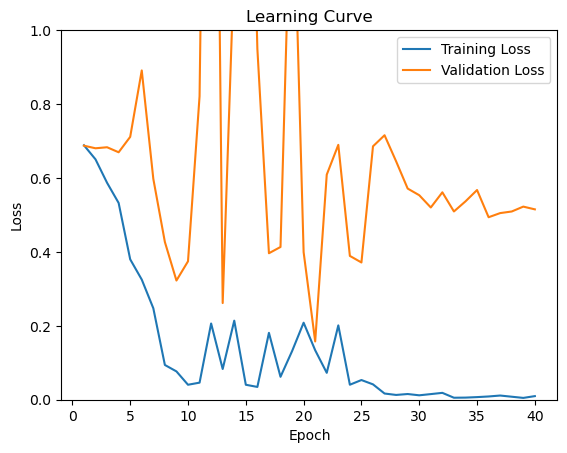

Fold 5
Accuracy Train: 0.9225000021979213. Accuracy valid: 0.7591666769236326
Recall Train: 0.8137499690055847. Recall valid: 0.7250000238418579
Precision Train: 0.816145834326744. Precision valid: 0.8725000619888306
Best Valid Accuracy Epoc: 3. Value = 0.8333333432674408 Recall val = 0.75
Best Valid Recall Epoc: 1. Value = 1.0 Acc val = 0.6333333551883698


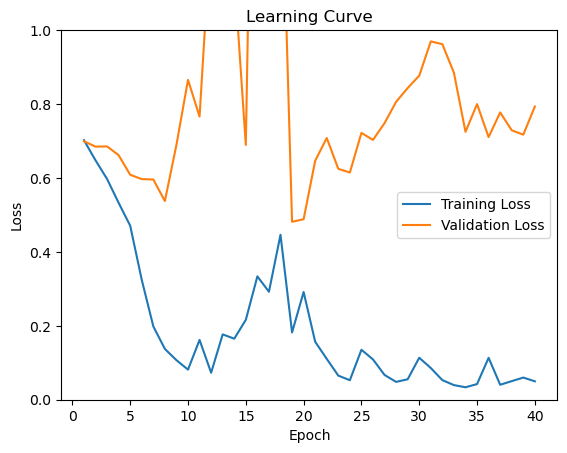

5
Fold 0: Training Loss: 0.16738572095055132, Validation Loss: 0.6353688144590706
Fold 1: Training Loss: 0.16336403738241642, Validation Loss: 0.3003755809368158
Fold 2: Training Loss: 0.16434333012439312, Validation Loss: 0.6188142997139948
Fold 3: Training Loss: 0.1381025460897945, Validation Loss: 0.6983571543358267
Fold 4: Training Loss: 0.1904781457968056, Validation Loss: 0.8693195719621144
TRAIN LOSS MEDIA: 0.16473475606879218 VALID LOSS MEDIA: 0.6244470842815646
TRAIN ACC MEDIA: 0.9399285735136698 VALID ACC MEDIA: 0.7803333386778832
TRAIN RECALL MEDIA: 0.8941547274589539 VALID RECALL MEDIA: 0.7512499690055847
TRAIN PRECISION MEDIA: 0.9073720494657754 VALID PRECISION MEDIA: 0.8123333524167539
Fold 1
Accuracy Train: 0.9350694465140503. Accuracy valid: 0.6444444559514523
Recall Train: 0.8635780215263367. Recall valid: 0.800000011920929
Precision Train: 0.9166666865348816. Precision valid: 0.6791864633560181
Best Valid Accuracy Epoc: 15. Value = 0.8888888955116272 Recall val = 0.75

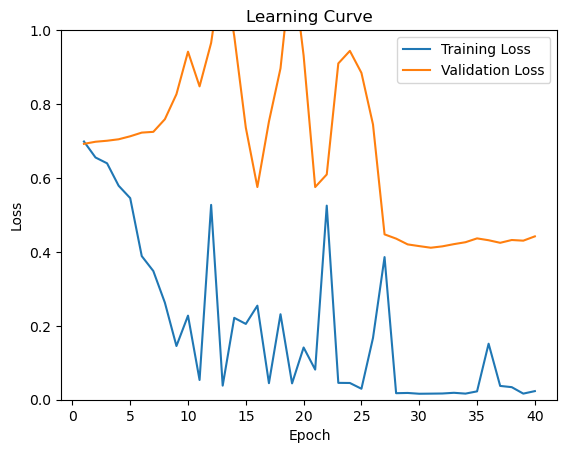

Fold 2
Accuracy Train: 0.9381944455206395. Accuracy valid: 0.7833333417773247
Recall Train: 0.9074569940567017. Recall valid: 0.8812500238418579
Precision Train: 0.9216945767402649. Precision valid: 0.7818650841712952
Best Valid Accuracy Epoc: 17. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 2. Value = 1.0 Acc val = 0.4444444477558136


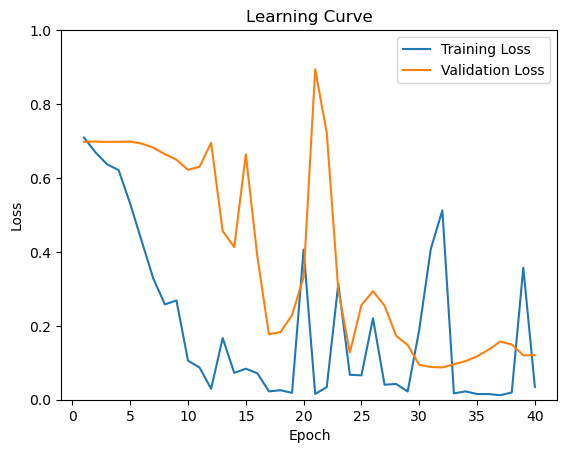

Fold 3
Accuracy Train: 0.9105902791023255. Accuracy valid: 0.669444452226162
Recall Train: 0.9283565282821655. Recall valid: 0.762499988079071
Precision Train: 0.9040542840957642. Precision valid: 0.7416666686534882
Best Valid Accuracy Epoc: 14. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 2. Value = 1.0 Acc val = 0.4444444477558136


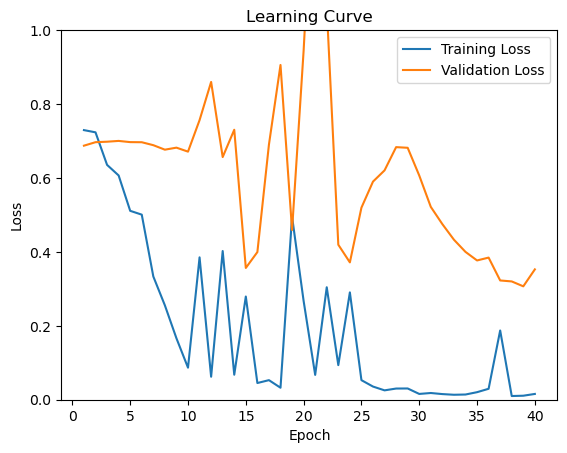

Fold 4
Accuracy Train: 0.9184027791023255. Accuracy valid: 0.6611111246049404
Recall Train: 0.9649831652641296. Recall valid: 0.96875
Precision Train: 0.9145517349243164. Precision valid: 0.5938690900802612
Best Valid Accuracy Epoc: 18. Value = 0.8888888955116272 Recall val = 0.75
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.4444444477558136


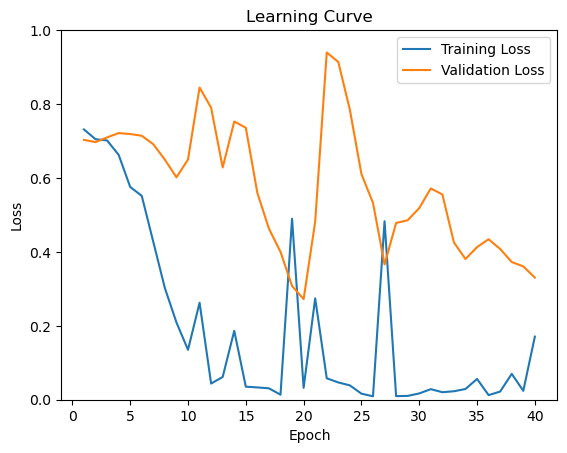

Fold 5
Accuracy Train: 0.9140625. Accuracy valid: 0.765625
Recall Train: 0.96979159116745. Recall valid: 0.8187500238418579
Precision Train: 0.9006365537643433. Precision valid: 0.8455356359481812
Best Valid Accuracy Epoc: 11. Value = 0.875 Recall val = 0.75
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.5


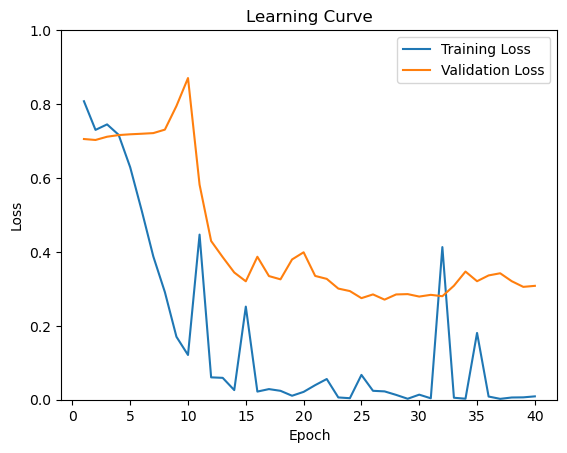

5
Fold 0: Training Loss: 0.1984496721997857, Validation Loss: 0.6798983111977577
Fold 1: Training Loss: 0.19917042769957333, Validation Loss: 0.3851043859496713
Fold 2: Training Loss: 0.19796464901883154, Validation Loss: 0.615921451151371
Fold 3: Training Loss: 0.1902522903867066, Validation Loss: 0.5743274807929992
Fold 4: Training Loss: 0.17370148429763504, Validation Loss: 0.4341723345220089
TRAIN LOSS MEDIA: 0.19190770472050644 VALID LOSS MEDIA: 0.5378847927227617
TRAIN ACC MEDIA: 0.9232638900478681 VALID ACC MEDIA: 0.7047916749119759
TRAIN RECALL MEDIA: 0.9268332719802856 VALID RECALL MEDIA: 0.846250057220459
TRAIN PRECISION MEDIA: 0.911520779132843 VALID PRECISION MEDIA: 0.7284245884418488


In [ ]:
prueba_k_fold_resnet_no_pre_oc_impr(df_mosaic, 5, 40, optim.Adam, 5, 0.0001, False, None)
prueba_k_fold_resnet_no_pre_oc_impr(df_mosaic, 5, 40, optim.Adam, 16, 0.0001, False, None)

Fold 1
Accuracy Train: 0.9821428578346968. Accuracy valid: 0.7937500018626451
Recall Train: 0.9298809170722961. Recall valid: 0.78125
Precision Train: 0.9428571462631226. Precision valid: 0.8854166269302368
Best Valid Accuracy Epoc: 7. Value = 0.875 Recall val = 0.75
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.45000000298023224


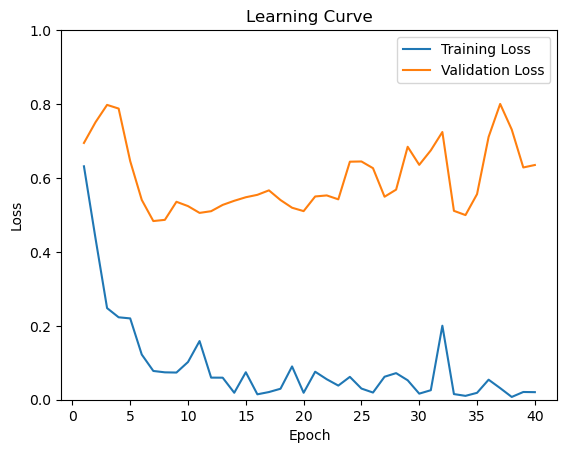

Fold 2
Accuracy Train: 0.9728571440492357. Accuracy valid: 0.8768750049173832
Recall Train: 0.9453571438789368. Recall valid: 0.9125000238418579
Precision Train: 0.9373809695243835. Precision valid: 0.9118749499320984
Best Valid Accuracy Epoc: 8. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.5250000059604645


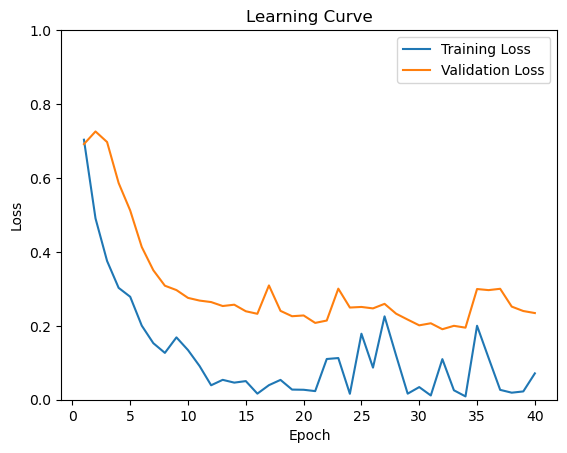

Fold 3
Accuracy Train: 0.9685714297528778. Accuracy valid: 0.8225000005215406
Recall Train: 0.9226785898208618. Recall valid: 0.783333420753479
Precision Train: 0.9428571447730064. Precision valid: 0.9174999997019768
Best Valid Accuracy Epoc: 4. Value = 0.9000000059604645 Recall val = 1.0
Best Valid Recall Epoc: 2. Value = 1.0 Acc val = 0.4750000014901161


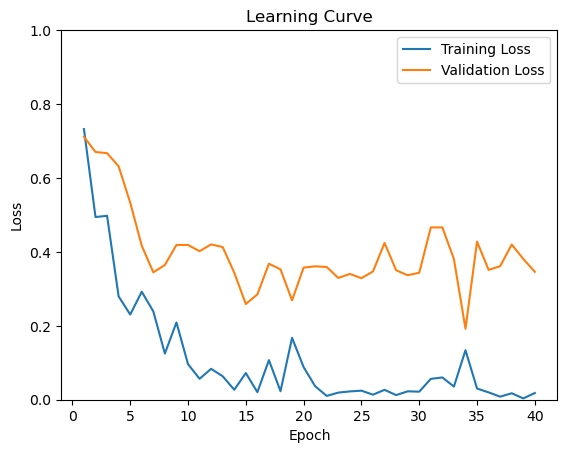

Fold 4
Accuracy Train: 0.976428572461009. Accuracy valid: 0.6600000064820051
Recall Train: 0.9691071510314941. Recall valid: 0.5708333253860474
Precision Train: 0.9640476107597351. Precision valid: 0.40520833507180215
Best Valid Accuracy Epoc: 4. Value = 0.7750000059604645 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.675000011920929


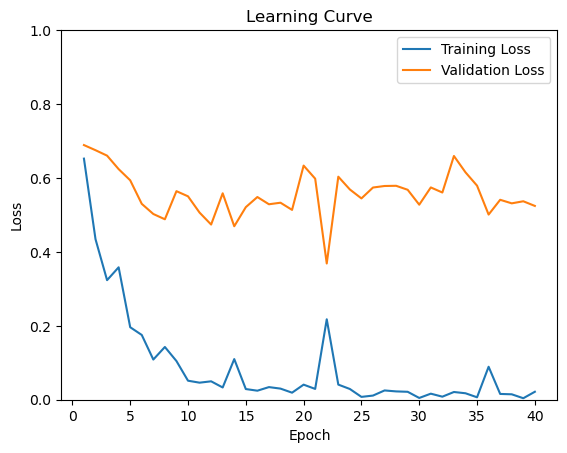

Fold 5
Accuracy Train: 0.9543750008102506. Accuracy valid: 0.7325000081211328
Recall Train: 0.8566145896911621. Recall valid: 0.7749999761581421
Precision Train: 0.8649999499320984. Precision valid: 0.8470832705497742
Best Valid Accuracy Epoc: 4. Value = 0.8333333432674408 Recall val = 0.75
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.533333346247673


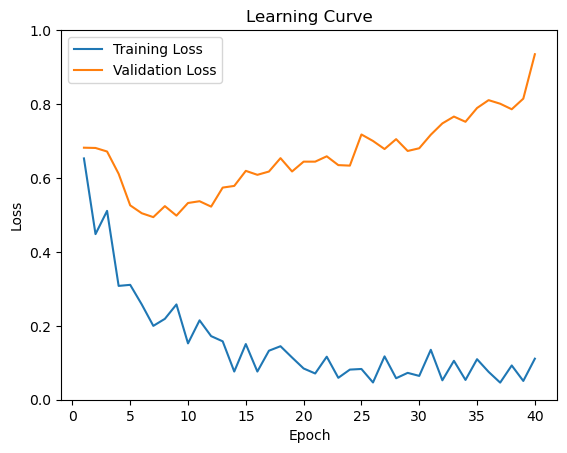

5
Fold 0: Training Loss: 0.09107347445096821, Validation Loss: 0.600891656242311
Fold 1: Training Loss: 0.12275336682796478, Validation Loss: 0.30427491422742603
Fold 2: Training Loss: 0.11247688893927262, Validation Loss: 0.39898966503096744
Fold 3: Training Loss: 0.08970026192255318, Validation Loss: 0.5574466018006206
Fold 4: Training Loss: 0.15610345192253589, Validation Loss: 0.6585178316570819
TRAIN LOSS MEDIA: 0.11442148881265894 VALID LOSS MEDIA: 0.5040241337916814
TRAIN ACC MEDIA: 0.9708750009816141 VALID ACC MEDIA: 0.7771250043809415
TRAIN RECALL MEDIA: 0.9247276186943054 VALID RECALL MEDIA: 0.76458340883255
TRAIN PRECISION MEDIA: 0.9304285642504692 VALID PRECISION MEDIA: 0.7934166364371776


In [ ]:
prueba_k_fold_resnet_no_pre_impr(df_mosaic, 5, 40, optim.RMSprop, 5, 1e-5, False, None)

#### CON TL SIN OC

Fold 1
Accuracy Train: 0.7951388915379842. Accuracy valid: 0.5916666844859719
Recall Train: 0.5738723278045654. Recall valid: 0.23125000298023224
Precision Train: 0.7166666708886623. Precision valid: 0.5411111112684012
Best Valid Accuracy Epoc: 34. Value = 0.7777777910232544 Recall val = 0.5
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.4444444477558136


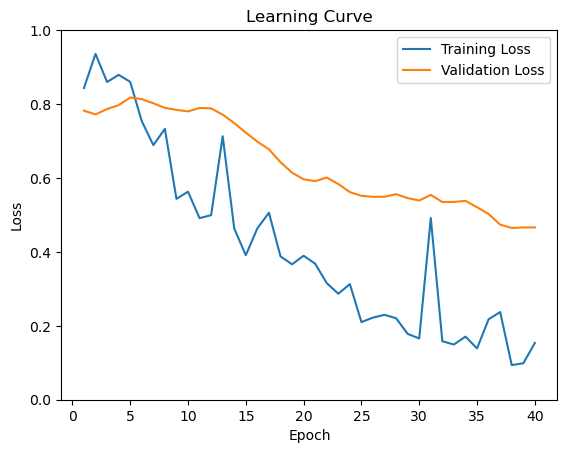

Fold 2
Accuracy Train: 0.8680555572112401. Accuracy valid: 0.7277777940034866
Recall Train: 0.8350363969802856. Recall valid: 0.8500000238418579
Precision Train: 0.8626521229743958. Precision valid: 0.6450595408678055
Best Valid Accuracy Epoc: 29. Value = 0.8888888955116272 Recall val = 1.0
Best Valid Recall Epoc: 11. Value = 1.0 Acc val = 0.6666666865348816


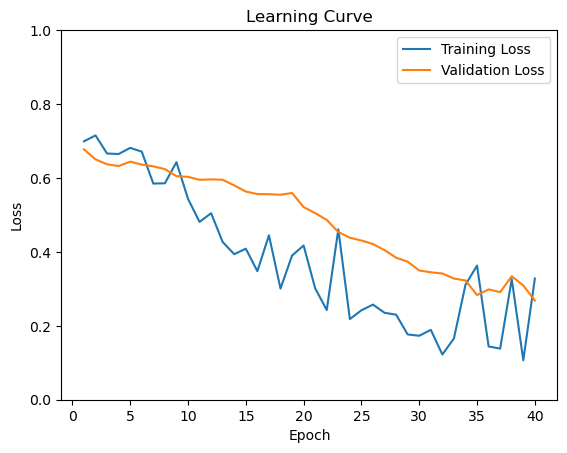

Fold 3
Accuracy Train: 0.8173611131807167. Accuracy valid: 0.7333333425223827
Recall Train: 0.8946320414543152. Recall valid: 0.612500011920929
Precision Train: 0.8101791143417358. Precision valid: 0.8430654406547546
Best Valid Accuracy Epoc: 13. Value = 0.8888888955116272 Recall val = 0.75
Best Valid Recall Epoc: 2. Value = 0.75 Acc val = 0.3333333432674408


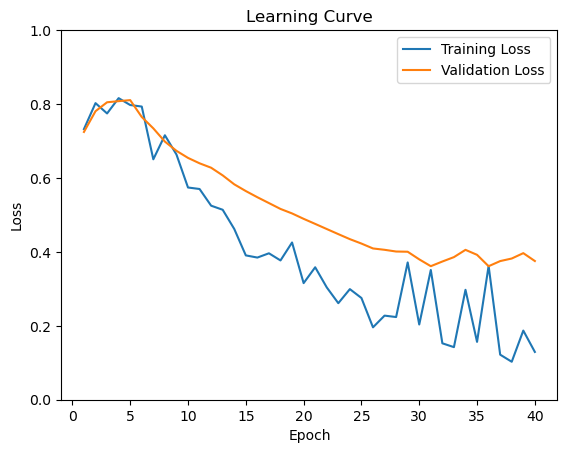

Fold 4
Accuracy Train: 0.8595486134290695. Accuracy valid: 0.8305555656552315
Recall Train: 0.6794477701187134. Recall valid: 0.6625000238418579
Precision Train: 0.7833333373069763. Precision valid: 0.8183333352208138
Best Valid Accuracy Epoc: 17. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 17. Value = 1.0 Acc val = 1.0


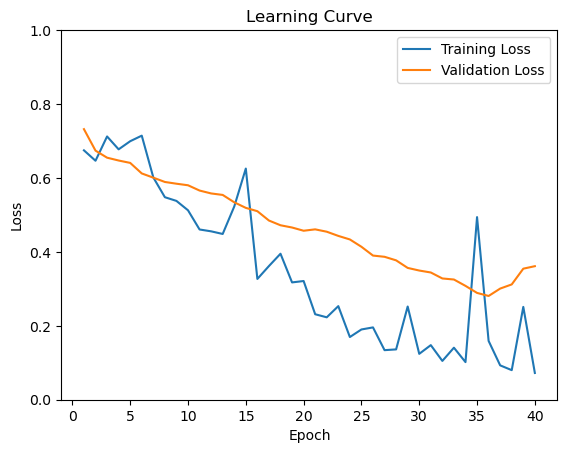

Fold 5
Accuracy Train: 0.8854166666666667. Accuracy valid: 0.8625
Recall Train: 0.8466922640800476. Recall valid: 0.768750011920929
Precision Train: 0.8745039701461792. Precision valid: 0.8291666671633721
Best Valid Accuracy Epoc: 16. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 16. Value = 1.0 Acc val = 1.0


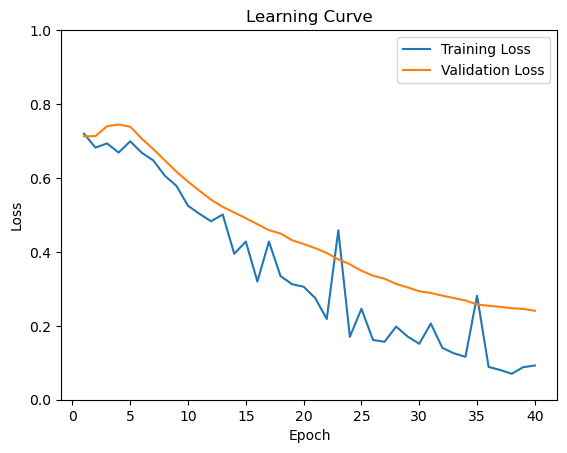

5
Fold 0: Training Loss: 0.4187329836189747, Validation Loss: 0.6414482809603215
Fold 1: Training Loss: 0.3825453007593751, Validation Loss: 0.48464763090014457
Fold 2: Training Loss: 0.41006656289100646, Validation Loss: 0.5278100721538067
Fold 3: Training Loss: 0.3528479527682066, Validation Loss: 0.4676772356033325
Fold 4: Training Loss: 0.34987768437713385, Validation Loss: 0.4459283359348774
TRAIN LOSS MEDIA: 0.3828140968829393 VALID LOSS MEDIA: 0.5135023111104966
TRAIN ACC MEDIA: 0.8451041684051355 VALID ACC MEDIA: 0.7491666773334146
TRAIN RECALL MEDIA: 0.7659361362457275 VALID RECALL MEDIA: 0.6250000596046448
TRAIN PRECISION MEDIA: 0.8094670431315899 VALID PRECISION MEDIA: 0.7353472190350294
Fold 1
Accuracy Train: 0.887142861155527. Accuracy valid: 0.7937500029802322
Recall Train: 0.8213094472885132. Recall valid: 0.612500011920929
Precision Train: 0.8398809481412173. Precision valid: 0.8562500029802322
Best Valid Accuracy Epoc: 7. Value = 0.875 Recall val = 0.75
Best Valid Reca

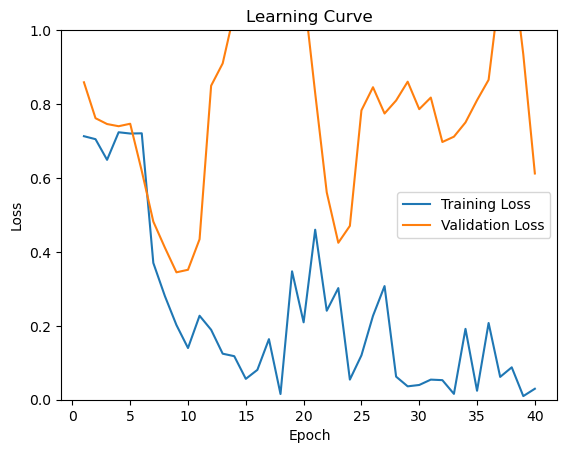

Fold 2
Accuracy Train: 0.8828571475510086. Accuracy valid: 0.8500000014901161
Recall Train: 0.8396428823471069. Recall valid: 0.908333420753479
Precision Train: 0.8791666030883789. Precision valid: 0.7770833373069763
Best Valid Accuracy Epoc: 5. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 5. Value = 1.0 Acc val = 1.0


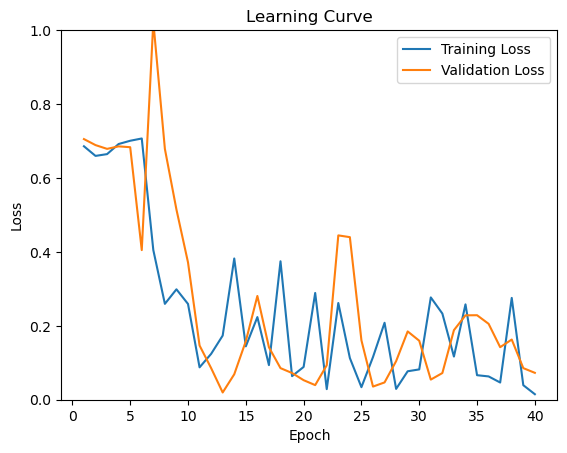

Fold 3
Accuracy Train: 0.8878571470933302. Accuracy valid: 0.7850000003352762
Recall Train: 0.9067261815071106. Recall valid: 0.7500000596046448
Precision Train: 0.867440402507782. Precision valid: 0.9045833349227905
Best Valid Accuracy Epoc: 6. Value = 0.875 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 6. Value = 0.8333333730697632 Acc val = 0.875


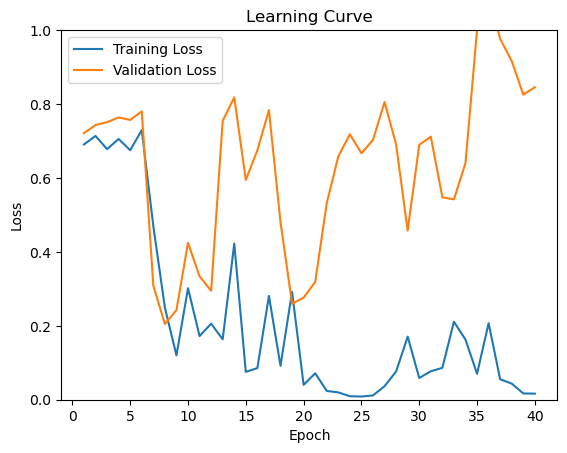

Fold 4
Accuracy Train: 0.8828571472849165. Accuracy valid: 0.7968750037252903
Recall Train: 0.8638690710067749. Recall valid: 0.82916659116745
Precision Train: 0.8741071820259094. Precision valid: 0.6791666686534882
Best Valid Accuracy Epoc: 10. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 5. Value = 1.0 Acc val = 0.5250000059604645


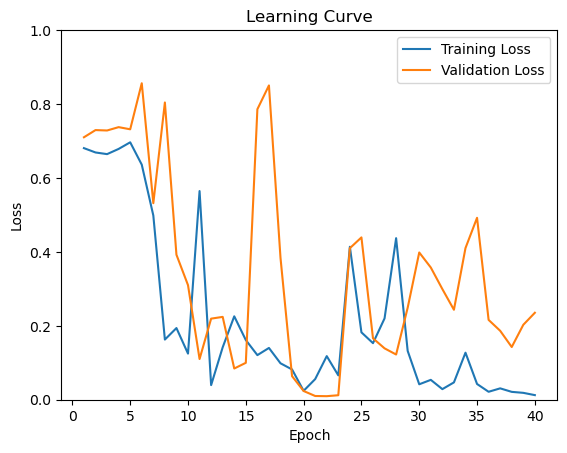

Fold 5
Accuracy Train: 0.8325000036042184. Accuracy valid: 0.7641666766256094
Recall Train: 0.7551562190055847. Recall valid: 0.78125
Precision Train: 0.7338541746139526. Precision valid: 0.8487499952316284
Best Valid Accuracy Epoc: 14. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 6. Value = 1.0 Acc val = 0.8333333432674408


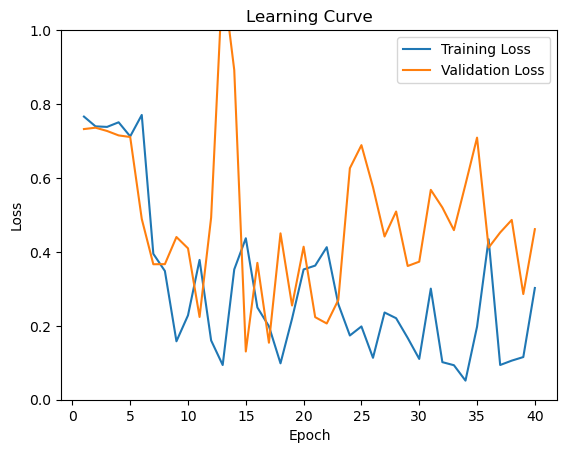

5
Fold 0: Training Loss: 0.23355189051944764, Validation Loss: 0.807003486645408
Fold 1: Training Loss: 0.2428915770491585, Validation Loss: 0.2673872823826969
Fold 2: Training Loss: 0.21490596008952706, Validation Loss: 0.6326823470502859
Fold 3: Training Loss: 0.22067053632345052, Validation Loss: 0.3529797769355355
Fold 4: Training Loss: 0.3049557350575924, Validation Loss: 0.48584425659500996
TRAIN LOSS MEDIA: 0.2433951398078352 VALID LOSS MEDIA: 0.5091794299217872
TRAIN ACC MEDIA: 0.8746428613378002 VALID ACC MEDIA: 0.7979583370313048
TRAIN RECALL MEDIA: 0.8373407125473022 VALID RECALL MEDIA: 0.7762500047683716
TRAIN PRECISION MEDIA: 0.838889862075448 VALID PRECISION MEDIA: 0.8131666678190232


In [ ]:
prueba_k_fold_resnet_pre_impr(df_mosaic, 5, 5, 35, optim.Adam, 16, 1e-5, True, None)
prueba_k_fold_resnet_pre_impr(df_mosaic, 5, 5, 35, optim.Adam, 5, 0.0001, True, None)

Fold 1
Accuracy Train: 0.9000000031398876. Accuracy valid: 0.7762500043958426
Recall Train: 0.8764286041259766. Recall valid: 0.606249988079071
Precision Train: 0.8688095211982727. Precision valid: 0.8258333370089531
Best Valid Accuracy Epoc: 7. Value = 0.875 Recall val = 0.75
Best Valid Recall Epoc: 6. Value = 1.0 Acc val = 0.550000011920929


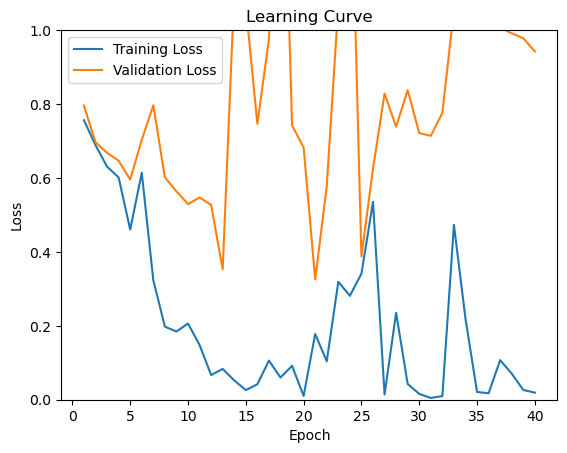

Fold 2
Accuracy Train: 0.895714288896748. Accuracy valid: 0.8718750018626451
Recall Train: 0.8692857623100281. Recall valid: 0.904166579246521
Precision Train: 0.8573809862136841. Precision valid: 0.8016666695475578
Best Valid Accuracy Epoc: 7. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.42500001192092896


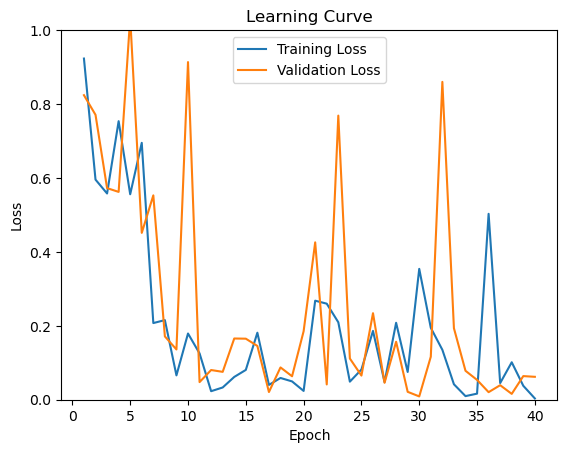

Fold 3
Accuracy Train: 0.9014285742704358. Accuracy valid: 0.8037500003352761
Recall Train: 0.8850595355033875. Recall valid: 0.7583333849906921
Precision Train: 0.8670833706855774. Precision valid: 0.9368749998509884
Best Valid Accuracy Epoc: 15. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 3. Value = 1.0 Acc val = 0.4750000014901161


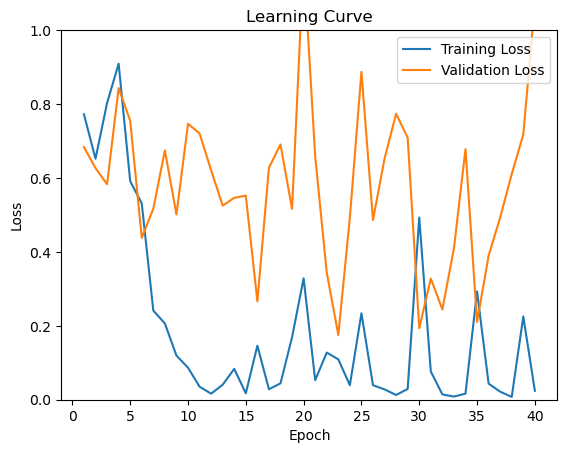

Fold 4
Accuracy Train: 0.8978571460183178. Accuracy valid: 0.7675000037997961
Recall Train: 0.875952422618866. Recall valid: 0.7541666626930237
Precision Train: 0.8660119771957397. Precision valid: 0.5668750017881393
Best Valid Accuracy Epoc: 17. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 4. Value = 1.0 Acc val = 0.42500001192092896


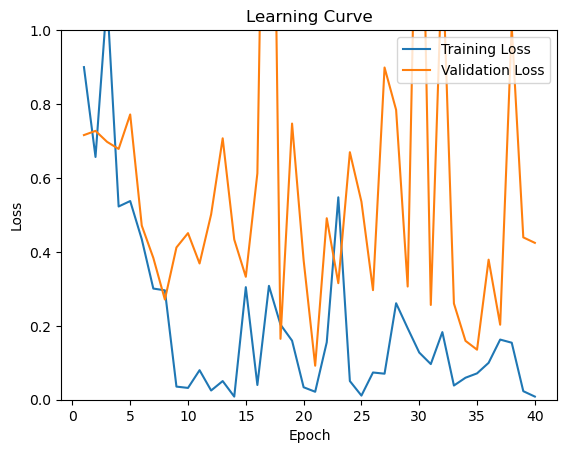

Fold 5
Accuracy Train: 0.8112500027753413. Accuracy valid: 0.7275000110268592
Recall Train: 0.7751562595367432. Recall valid: 0.78125
Precision Train: 0.7590624690055847. Precision valid: 0.774166677892208
Best Valid Accuracy Epoc: 10. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 1. Value = 1.0 Acc val = 0.533333346247673


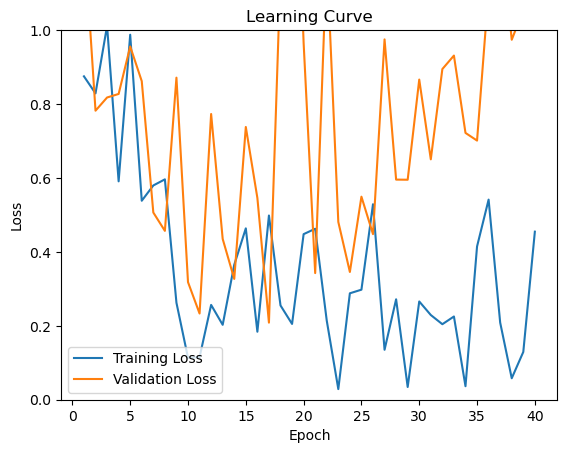

5
Fold 0: Training Loss: 0.20960976956412197, Validation Loss: 0.8202628848608583
Fold 1: Training Loss: 0.2063378524617292, Validation Loss: 0.260207409405848
Fold 2: Training Loss: 0.19294701016042382, Validation Loss: 0.5787182820495218
Fold 3: Training Loss: 0.21061305981129408, Validation Loss: 0.5770171570591629
Fold 4: Training Loss: 0.36016207952052354, Validation Loss: 0.7667134224757319
TRAIN LOSS MEDIA: 0.23593395430361852 VALID LOSS MEDIA: 0.6005838311702246
TRAIN ACC MEDIA: 0.8812500030201461 VALID ACC MEDIA: 0.7893750042840839
TRAIN RECALL MEDIA: 0.8563765287399292 VALID RECALL MEDIA: 0.7608333230018616
TRAIN PRECISION MEDIA: 0.843669593334198 VALID PRECISION MEDIA: 0.7810833372175694
Fold 1
Accuracy Train: 0.9178819452722866. Accuracy valid: 0.7805555656552314
Recall Train: 0.9063226580619812. Recall valid: 0.675000011920929
Precision Train: 0.9007301330566406. Precision valid: 0.8381944447755814
Best Valid Accuracy Epoc: 7. Value = 0.8888888955116272 Recall val = 0.75
B

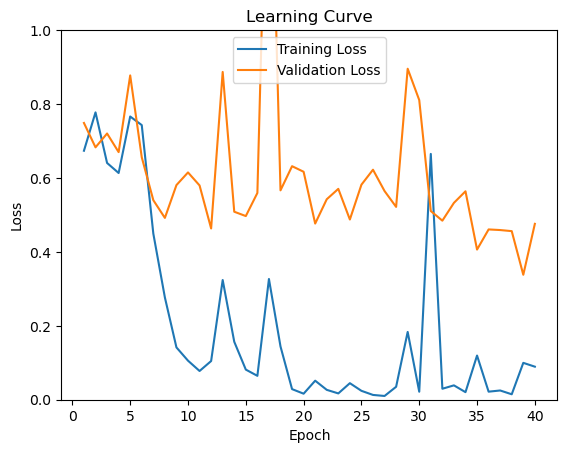

Fold 2
Accuracy Train: 0.8524305572112401. Accuracy valid: 0.7888888999819755
Recall Train: 0.8034785389900208. Recall valid: 0.800000011920929
Precision Train: 0.8200777173042297. Precision valid: 0.744603180885315
Best Valid Accuracy Epoc: 11. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 4. Value = 1.0 Acc val = 0.6666666865348816


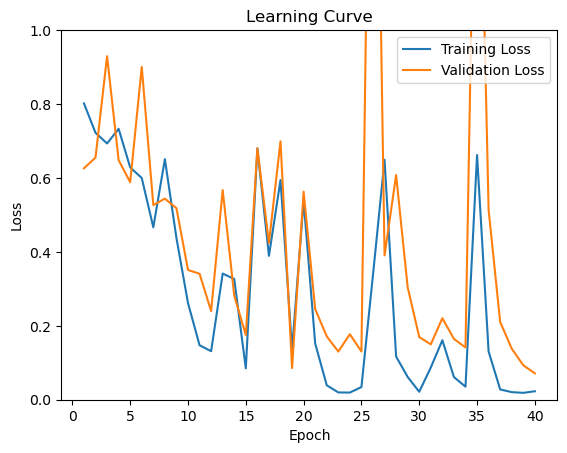

Fold 3
Accuracy Train: 0.9026041679084301. Accuracy valid: 0.7750000119209289
Recall Train: 0.8760747909545898. Recall valid: 0.59375
Precision Train: 0.8904398083686829. Precision valid: 0.7688888907432556
Best Valid Accuracy Epoc: 12. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 4. Value = 1.0 Acc val = 0.8888888955116272


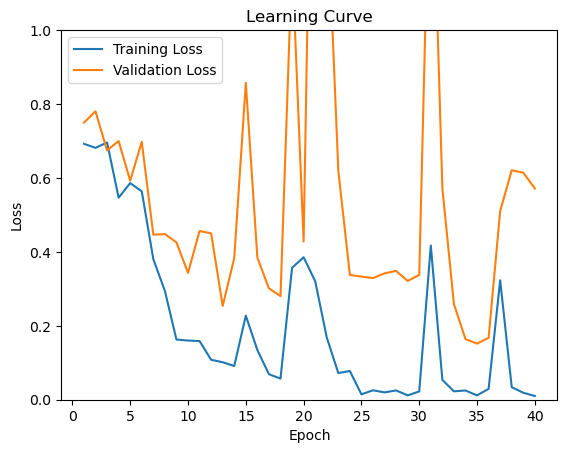

Fold 4
Accuracy Train: 0.8776041681567829. Accuracy valid: 0.7361111231148243
Recall Train: 0.8161805868148804. Recall valid: 0.737500011920929
Precision Train: 0.8240633010864258. Precision valid: 0.595813499391079
Best Valid Accuracy Epoc: 11. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 2. Value = 1.0 Acc val = 0.4444444477558136


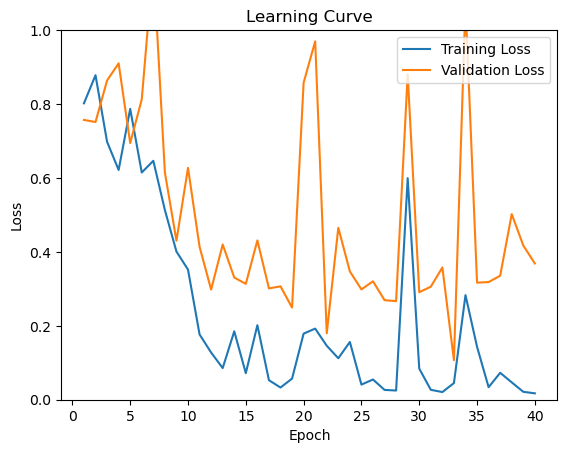

Fold 5
Accuracy Train: 0.9. Accuracy valid: 0.71875
Recall Train: 0.8595932126045227. Recall valid: 0.637499988079071
Precision Train: 0.8749338388442993. Precision valid: 0.690535718202591
Best Valid Accuracy Epoc: 14. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 2. Value = 1.0 Acc val = 0.75


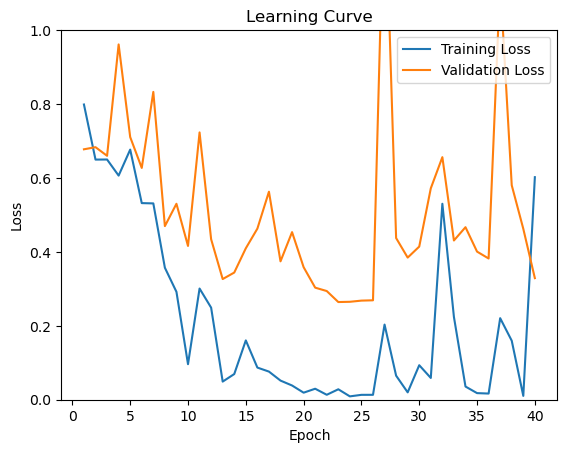

5
Fold 0: Training Loss: 0.20160947183612735, Validation Loss: 0.6099700354039669
Fold 1: Training Loss: 0.30108959334902463, Validation Loss: 0.46628225650638344
Fold 2: Training Loss: 0.20395347746089101, Validation Loss: 0.5671541705727577
Fold 3: Training Loss: 0.2408228657208383, Validation Loss: 0.49891725573688744
Fold 4: Training Loss: 0.21639526057988406, Validation Loss: 0.5191661477088928
TRAIN LOSS MEDIA: 0.23277413378935305 VALID LOSS MEDIA: 0.5322979731857777
TRAIN ACC MEDIA: 0.890104167709748 VALID ACC MEDIA: 0.7598611201345921
TRAIN RECALL MEDIA: 0.8523300290107727 VALID RECALL MEDIA: 0.6887499690055847
TRAIN PRECISION MEDIA: 0.8620489239692688 VALID PRECISION MEDIA: 0.7276071467995643
Fold 1
Accuracy Train: 0.8939236126840114. Accuracy valid: 0.7444444559514523
Recall Train: 0.849871039390564. Recall valid: 0.5874999761581421
Precision Train: 0.8875859975814819. Precision valid: 0.7755555562675
Best Valid Accuracy Epoc: 13. Value = 0.8888888955116272 Recall val = 0.75


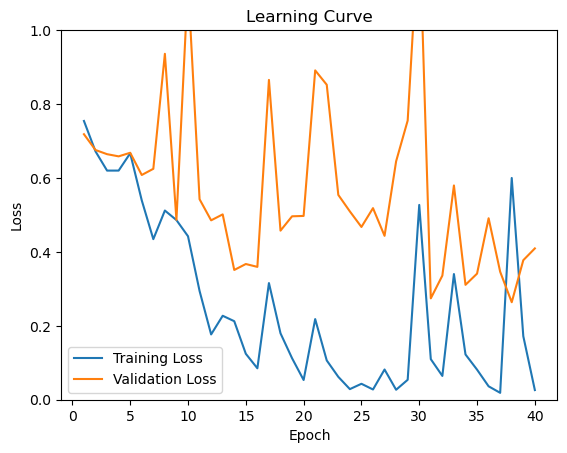

Fold 2
Accuracy Train: 0.8628472238779068. Accuracy valid: 0.8083333410322666
Recall Train: 0.8055456280708313. Recall valid: 0.762499988079071
Precision Train: 0.8307034373283386. Precision valid: 0.7565079383552075
Best Valid Accuracy Epoc: 12. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.4444444477558136


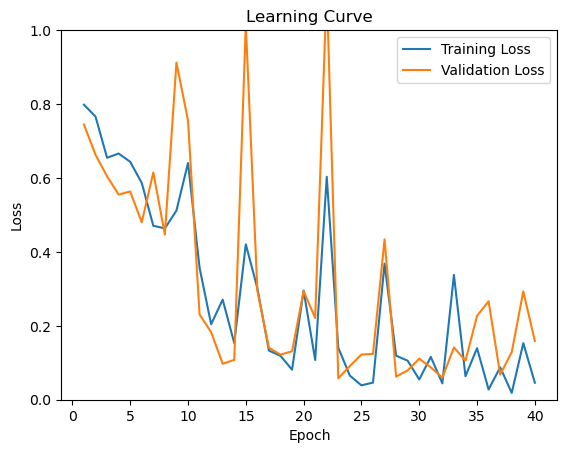

Fold 3
Accuracy Train: 0.8496527798473835. Accuracy valid: 0.7416666805744171
Recall Train: 0.7939216494560242. Recall valid: 0.53125
Precision Train: 0.8109332919120789. Precision valid: 0.7638888895511627
Best Valid Accuracy Epoc: 6. Value = 0.8888888955116272 Recall val = 0.75
Best Valid Recall Epoc: 5. Value = 1.0 Acc val = 0.4444444477558136


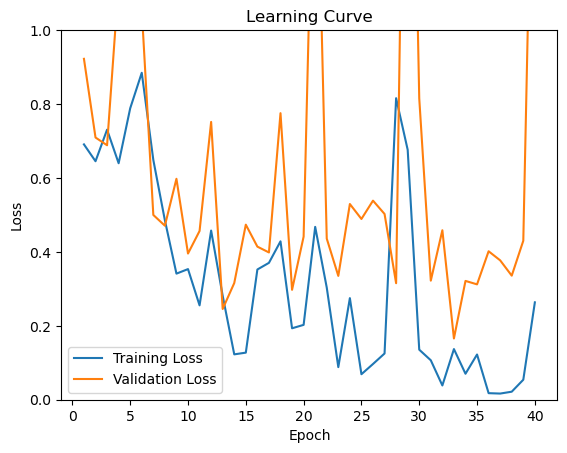

Fold 4
Accuracy Train: 0.8612847233812013. Accuracy valid: 0.7222222357988357
Recall Train: 0.7761243581771851. Recall valid: 0.8062499761581421
Precision Train: 0.8229295015335083. Precision valid: 0.6488492175936699
Best Valid Accuracy Epoc: 31. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 1. Value = 1.0 Acc val = 0.4444444477558136


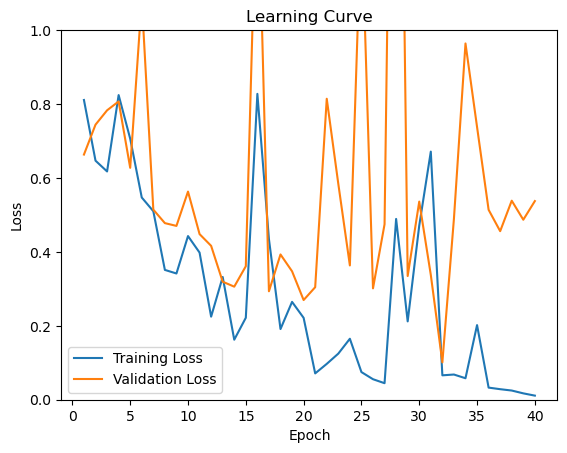

Fold 5
Accuracy Train: 0.8854166666666667. Accuracy valid: 0.828125
Recall Train: 0.8477910161018372. Recall valid: 0.7437499761581421
Precision Train: 0.8955141305923462. Precision valid: 0.8116666689515114
Best Valid Accuracy Epoc: 17. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 1. Value = 1.0 Acc val = 0.5


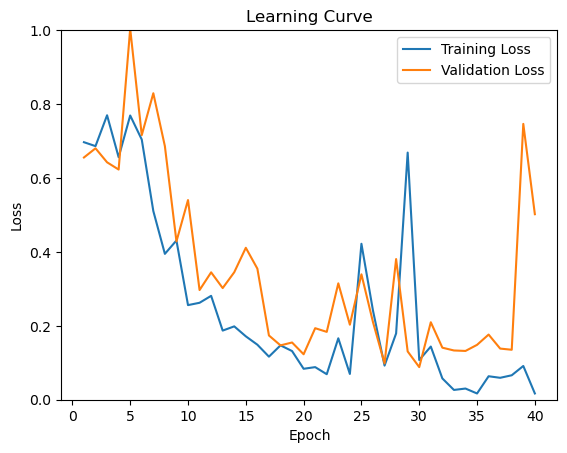

5
Fold 0: Training Loss: 0.2568553499877453, Validation Loss: 0.5688713476061821
Fold 1: Training Loss: 0.280517529277131, Validation Loss: 0.32274085758253934
Fold 2: Training Loss: 0.32251604055054484, Validation Loss: 0.630746791884303
Fold 3: Training Loss: 0.30155312272254375, Validation Loss: 0.6088272735476494
Fold 4: Training Loss: 0.2569497084710747, Validation Loss: 0.35152163095772265
TRAIN LOSS MEDIA: 0.2836783502018079 VALID LOSS MEDIA: 0.4965415803156793
TRAIN ACC MEDIA: 0.870625001291434 VALID ACC MEDIA: 0.7689583426713943
TRAIN RECALL MEDIA: 0.81465083360672 VALID RECALL MEDIA: 0.6862500309944153
TRAIN PRECISION MEDIA: 0.8495332598686218 VALID PRECISION MEDIA: 0.7512936541438103


In [ ]:
prueba_k_fold_resnet_pre_impr(df_mosaic, 5, 5, 35, optim.SGD, 5, 0.01, False, None)
prueba_k_fold_resnet_pre_impr(df_mosaic, 5, 5, 35, optim.SGD, 16, 0.01, False, None)
prueba_k_fold_resnet_pre_impr(df_mosaic, 5, 5, 35, optim.SGD, 16, 0.01, True, None)

Fold 1
Accuracy Train: 0.8771428606339862. Accuracy valid: 0.783125001937151
Recall Train: 0.9289880990982056. Recall valid: 0.7562500238418579
Precision Train: 0.8691666722297668. Precision valid: 0.8791666030883789
Best Valid Accuracy Epoc: 10. Value = 0.875 Recall val = 0.75
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.45000000298023224


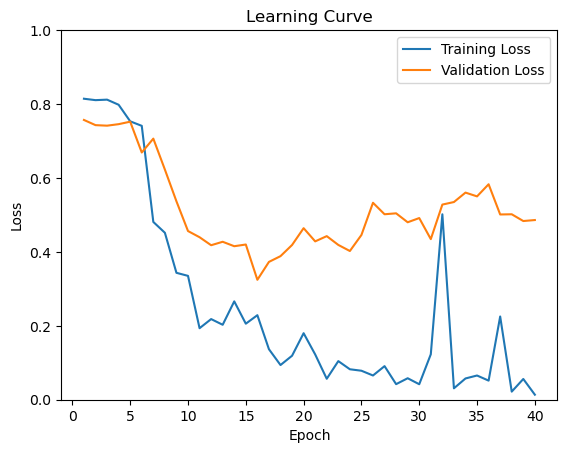

Fold 2
Accuracy Train: 0.896428575313517. Accuracy valid: 0.7875000009313226
Recall Train: 0.924761950969696. Recall valid: 0.9791666865348816
Precision Train: 0.8832737803459167. Precision valid: 0.6952083706855774
Best Valid Accuracy Epoc: 30. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.42500001192092896


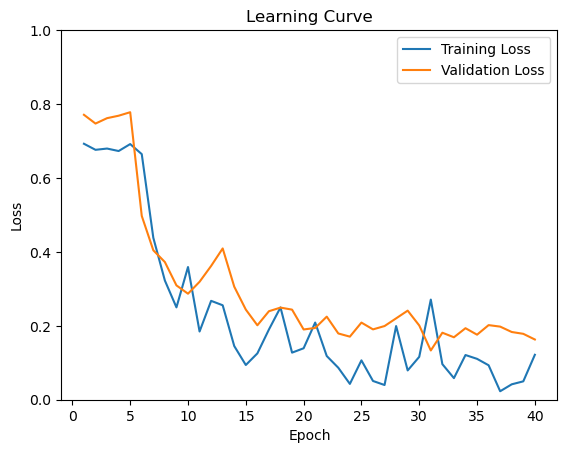

Fold 3
Accuracy Train: 0.8957142892692771. Accuracy valid: 0.7918750004842877
Recall Train: 0.924464225769043. Recall valid: 0.8291667103767395
Precision Train: 0.8723214268684387. Precision valid: 0.9114583134651184
Best Valid Accuracy Epoc: 10. Value = 0.875 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.4750000014901161


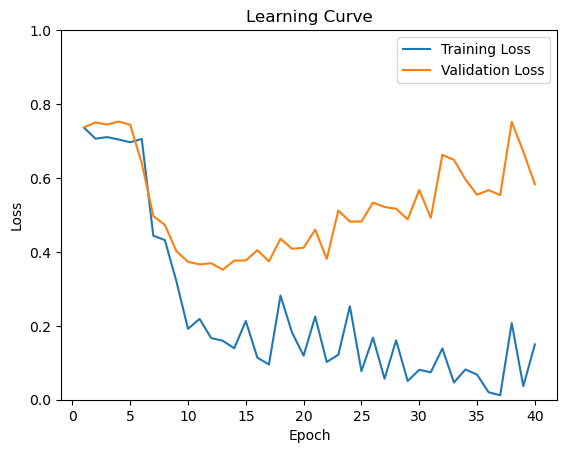

Fold 4
Accuracy Train: 0.8742857172553027. Accuracy valid: 0.7556250054389239
Recall Train: 0.8821428418159485. Recall valid: 0.9416667222976685
Precision Train: 0.8679167032241821. Precision valid: 0.625
Best Valid Accuracy Epoc: 26. Value = 0.875 Recall val = 1.0
Best Valid Recall Epoc: 7. Value = 1.0 Acc val = 0.7750000059604645


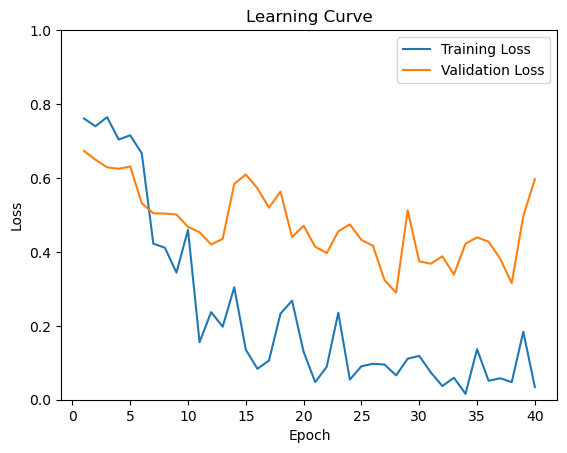

Fold 5
Accuracy Train: 0.8412500030826777. Accuracy valid: 0.8258333411067724
Recall Train: 0.7136458158493042. Recall valid: 0.7437499761581421
Precision Train: 0.7322916984558105. Precision valid: 0.8520833373069763
Best Valid Accuracy Epoc: 9. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 5. Value = 1.0 Acc val = 0.8333333432674408


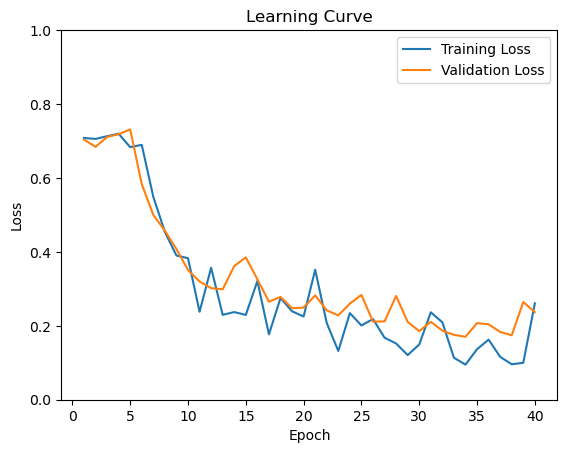

5
Fold 0: Training Loss: 0.25187303563579916, Validation Loss: 0.5157830286771059
Fold 1: Training Loss: 0.2314901940058917, Validation Loss: 0.30667133182287215
Fold 2: Training Loss: 0.23667804428841918, Validation Loss: 0.5252757463196758
Fold 3: Training Loss: 0.23855379791930317, Validation Loss: 0.4761801136657596
Fold 4: Training Loss: 0.2996376009657979, Validation Loss: 0.33228948852047324
TRAIN LOSS MEDIA: 0.2516465345630422 VALID LOSS MEDIA: 0.43123994180117736
TRAIN ACC MEDIA: 0.8769642891109521 VALID ACC MEDIA: 0.7887916699796915
TRAIN RECALL MEDIA: 0.8748005628585815 VALID RECALL MEDIA: 0.8500000238418579
TRAIN PRECISION MEDIA: 0.844994068145752 VALID PRECISION MEDIA: 0.7925833249092102


In [ ]:
prueba_k_fold_resnet_pre_impr(df_mosaic, 5, 5, 35, optim.RMSprop, 5, 1e-5, True, None)

#### CON TL Y OC

Fold 1
Accuracy Train: 0.8406250033527612. Accuracy valid: 0.6916666805744172
Recall Train: 0.7879544496536255. Recall valid: 0.612500011920929
Precision Train: 0.8272806406021118. Precision valid: 0.643700399249792
Best Valid Accuracy Epoc: 13. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 13. Value = 1.0 Acc val = 1.0


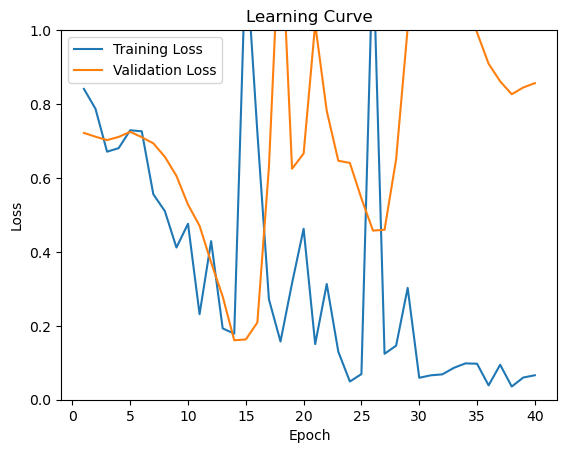

Fold 2
Accuracy Train: 0.8000000044703484. Accuracy valid: 0.8500000052154064
Recall Train: 0.7250549793243408. Recall valid: 0.875
Precision Train: 0.78911292552948. Precision valid: 0.8271428942680359
Best Valid Accuracy Epoc: 11. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 11. Value = 1.0 Acc val = 1.0


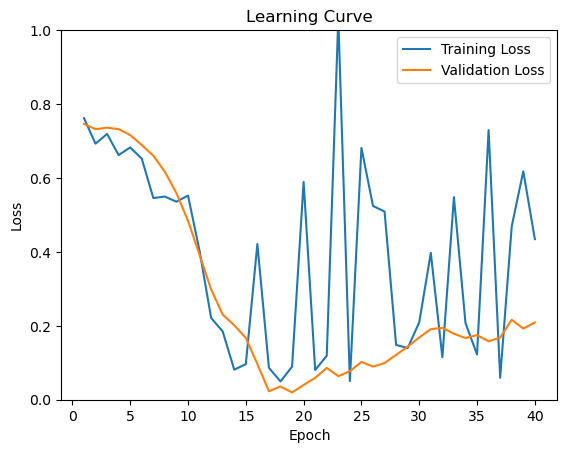

Fold 3
Accuracy Train: 0.8583333369344472. Accuracy valid: 0.7000000171363354
Recall Train: 0.7994551062583923. Recall valid: 0.4625000059604645
Precision Train: 0.8631196022033691. Precision valid: 0.6500992082059384
Best Valid Accuracy Epoc: 13. Value = 0.8888888955116272 Recall val = 0.75
Best Valid Recall Epoc: 21. Value = 1.0 Acc val = 0.6666666865348816


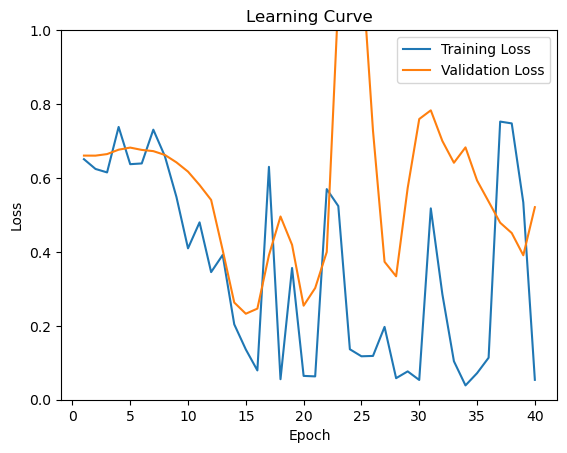

Fold 4
Accuracy Train: 0.7757812540978193. Accuracy valid: 0.7000000081956387
Recall Train: 0.830965518951416. Recall valid: 0.9375
Precision Train: 0.7476251721382141. Precision valid: 0.6216666758060455
Best Valid Accuracy Epoc: 24. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 3. Value = 1.0 Acc val = 0.4444444477558136


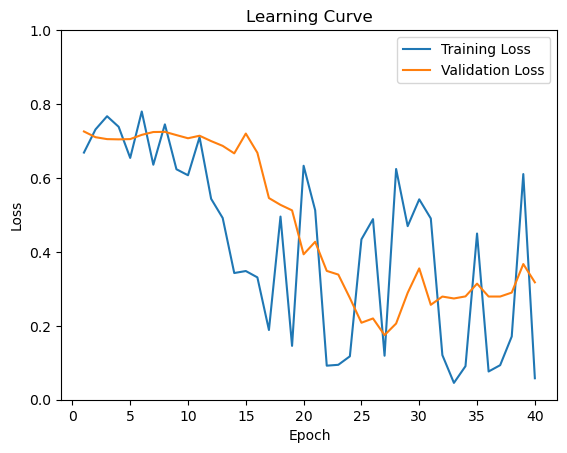

Fold 5
Accuracy Train: 0.802734375. Accuracy valid: 0.69375
Recall Train: 0.8822526931762695. Recall valid: 0.893750011920929
Precision Train: 0.8142577409744263. Precision valid: 0.664821445941925
Best Valid Accuracy Epoc: 19. Value = 0.875 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.5


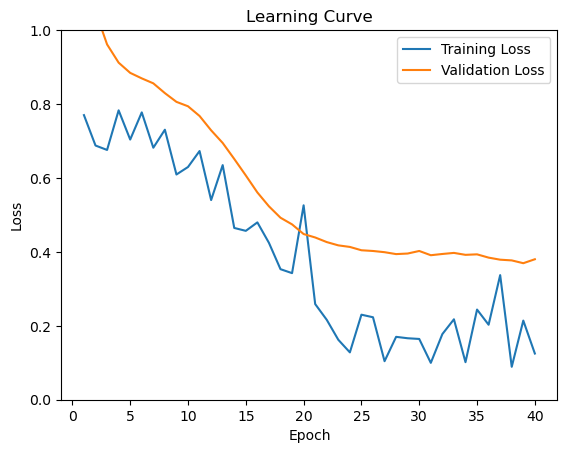

5
Fold 0: Training Loss: 0.34601872731000183, Validation Loss: 0.7326745796948672
Fold 1: Training Loss: 0.3942816757597029, Validation Loss: 0.27592013706453145
Fold 2: Training Loss: 0.35323037337511776, Validation Loss: 0.5818119954317809
Fold 3: Training Loss: 0.4220688447356224, Validation Loss: 0.47634919695556166
Fold 4: Training Loss: 0.38942340705543754, Validation Loss: 0.5756727941334248
TRAIN LOSS MEDIA: 0.3810046056471765 VALID LOSS MEDIA: 0.5284857406560332
TRAIN ACC MEDIA: 0.8154947947710752 VALID ACC MEDIA: 0.7270833422243596
TRAIN RECALL MEDIA: 0.805136501789093 VALID RECALL MEDIA: 0.7562499642372131
TRAIN PRECISION MEDIA: 0.8082792162895203 VALID PRECISION MEDIA: 0.6814861246943474
Fold 1
Accuracy Train: 0.8864583353201549. Accuracy valid: 0.7000000163912773
Recall Train: 0.8025232553482056. Recall valid: 0.512499988079071
Precision Train: 0.8066007841378451. Precision valid: 0.6800992101430893
Best Valid Accuracy Epoc: 10. Value = 0.8888888955116272 Recall val = 0.75

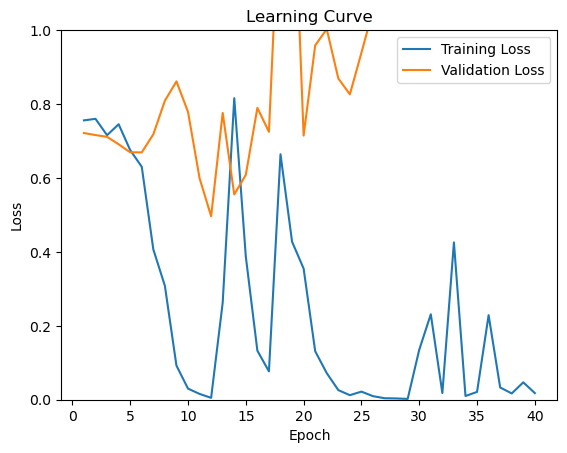

Fold 2
Accuracy Train: 0.8630208350718022. Accuracy valid: 0.8333333425223828
Recall Train: 0.8156536221504211. Recall valid: 0.9125000238418579
Precision Train: 0.8438326716423035. Precision valid: 0.755357152223587
Best Valid Accuracy Epoc: 9. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 5. Value = 1.0 Acc val = 0.7777777910232544


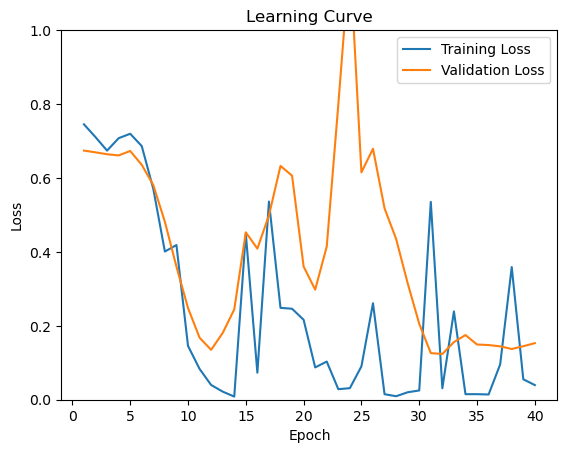

Fold 3
Accuracy Train: 0.8871527791023255. Accuracy valid: 0.7222222335636616
Recall Train: 0.930476188659668. Recall valid: 0.53125
Precision Train: 0.8679124116897583. Precision valid: 0.846875011920929
Best Valid Accuracy Epoc: 16. Value = 0.8888888955116272 Recall val = 0.75
Best Valid Recall Epoc: 0. Value = 0.75 Acc val = 0.3333333432674408


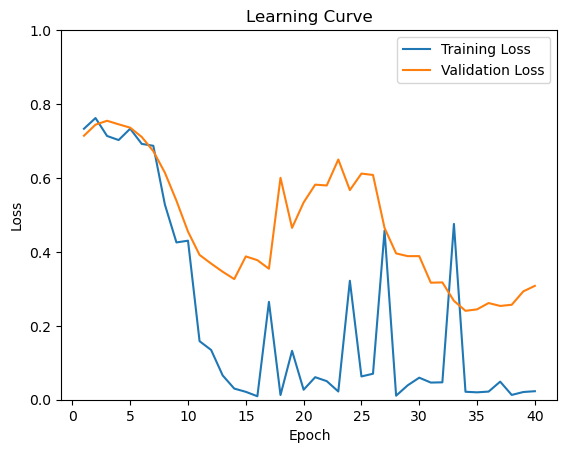

Fold 4
Accuracy Train: 0.882291668901841. Accuracy valid: 0.6361111219972372
Recall Train: 0.9110315442085266. Recall valid: 0.862500011920929
Precision Train: 0.850674033164978. Precision valid: 0.5952281951904297
Best Valid Accuracy Epoc: 21. Value = 0.8888888955116272 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.4444444477558136


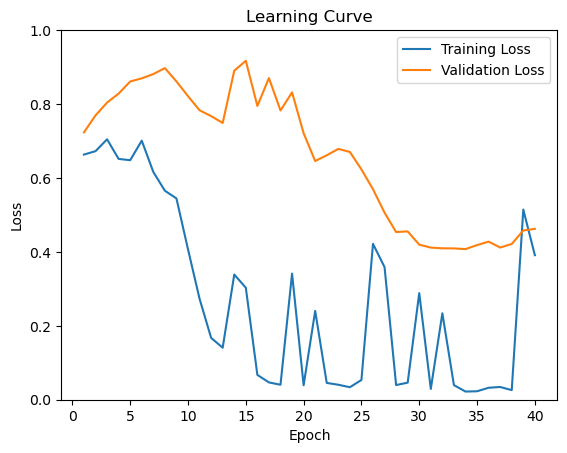

Fold 5
Accuracy Train: 0.8864583333333333. Accuracy valid: 0.775
Recall Train: 0.8157075643539429. Recall valid: 0.625
Precision Train: 0.8777777552604675. Precision valid: 0.7645833358168602
Best Valid Accuracy Epoc: 11. Value = 0.875 Recall val = 0.75
Best Valid Recall Epoc: 29. Value = 1.0 Acc val = 0.875


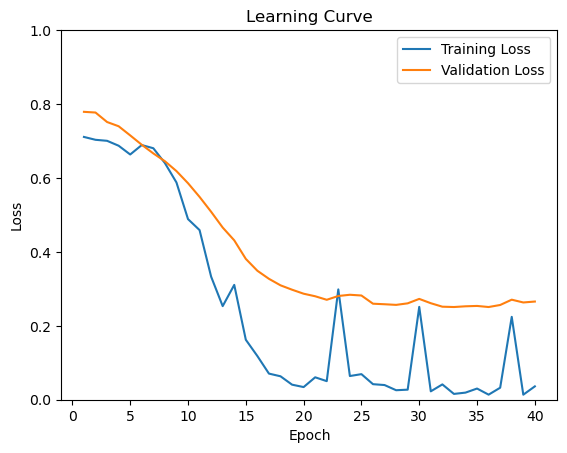

5
Fold 0: Training Loss: 0.2432472339074593, Validation Loss: 0.9616289168596268
Fold 1: Training Loss: 0.24429346432443708, Validation Loss: 0.40677527207881214
Fold 2: Training Loss: 0.22896127826534213, Validation Loss: 0.4708321377635002
Fold 3: Training Loss: 0.2711471184156835, Validation Loss: 0.6586107909679413
Fold 4: Training Loss: 0.24438387246336787, Validation Loss: 0.4038969412446022
TRAIN LOSS MEDIA: 0.24640659347525795 VALID LOSS MEDIA: 0.5803488117828965
TRAIN ACC MEDIA: 0.8810763903458915 VALID ACC MEDIA: 0.7333333428949118
TRAIN RECALL MEDIA: 0.855078399181366 VALID RECALL MEDIA: 0.6887499690055847
TRAIN PRECISION MEDIA: 0.8493595311790705 VALID PRECISION MEDIA: 0.728428581058979


In [ ]:
prueba_k_fold_resnet_pre_oc_impr(df_mosaic, 5, 5, 35, optim.Adam, 32, 0.001, True, None)
prueba_k_fold_resnet_pre_oc_impr(df_mosaic, 5, 5, 35, optim.Adam, 16, 0.001, False, None)

Fold 1
Accuracy Train: 0.9442708348234493. Accuracy valid: 0.7861111231148243
Recall Train: 0.8962036967277527. Recall valid: 0.5874999761581421
Precision Train: 0.9069278836250305. Precision valid: 0.9011111117899417
Best Valid Accuracy Epoc: 10. Value = 0.8888888955116272 Recall val = 0.75
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.4444444477558136


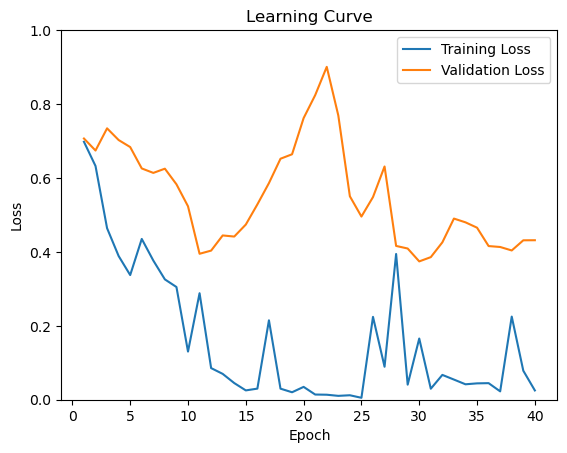

Fold 2
Accuracy Train: 0.9050347238779068. Accuracy valid: 0.8638888955116272
Recall Train: 0.8223304748535156. Recall valid: 0.925000011920929
Precision Train: 0.8440774083137512. Precision valid: 0.831527829170227
Best Valid Accuracy Epoc: 7. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 1. Value = 1.0 Acc val = 0.4444444477558136


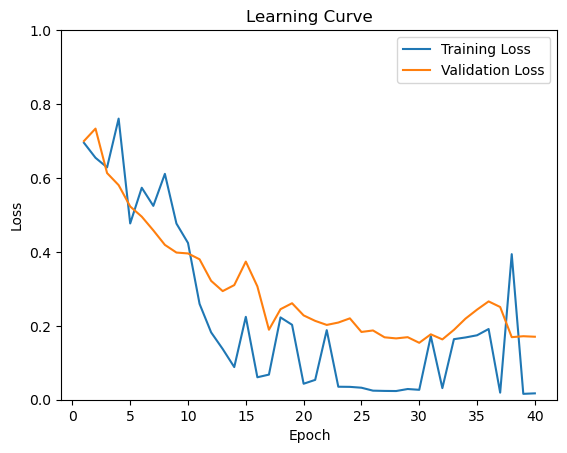

Fold 3
Accuracy Train: 0.8861111129323642. Accuracy valid: 0.8388888977468014
Recall Train: 0.8551918268203735. Recall valid: 0.699999988079071
Precision Train: 0.85474868491292. Precision valid: 0.9027777783572674
Best Valid Accuracy Epoc: 8. Value = 0.8888888955116272 Recall val = 0.75
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.4444444477558136


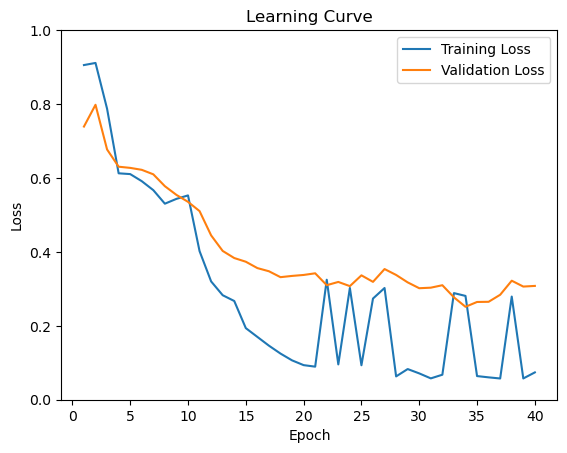

Fold 4
Accuracy Train: 0.7979166686534882. Accuracy valid: 0.611111132800579
Recall Train: 0.6365500688552856. Recall valid: 0.42500001192092896
Precision Train: 0.668477188050747. Precision valid: 0.40000001192092893
Best Valid Accuracy Epoc: 15. Value = 0.6666666865348816 Recall val = 0.25
Best Valid Recall Epoc: 20. Value = 0.75 Acc val = 0.6666666865348816


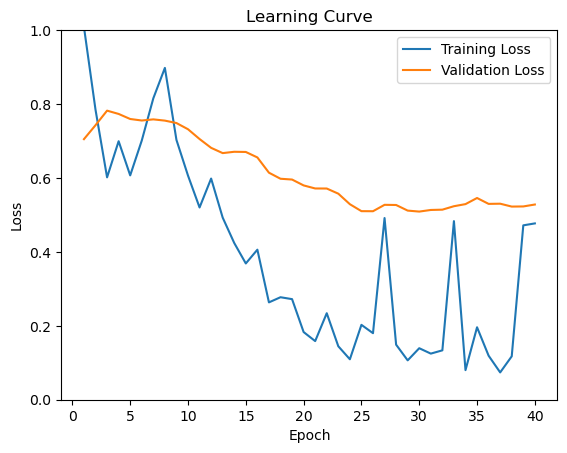

Fold 5
Accuracy Train: 0.890625. Accuracy valid: 0.834375
Recall Train: 0.8688591122627258. Recall valid: 0.956250011920929
Precision Train: 0.8841766119003296. Precision valid: 0.7830952405929565
Best Valid Accuracy Epoc: 20. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 1. Value = 1.0 Acc val = 0.875


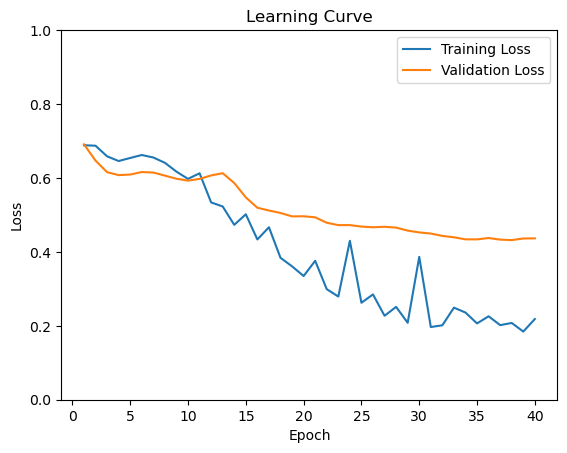

5
Fold 0: Training Loss: 0.16349041141802445, Validation Loss: 0.552111842483282
Fold 1: Training Loss: 0.22834630934521555, Validation Loss: 0.3030053924769163
Fold 2: Training Loss: 0.2926142358221114, Validation Loss: 0.40819564685225485
Fold 3: Training Loss: 0.3855855192989111, Validation Loss: 0.6133844092488289
Fold 4: Training Loss: 0.4065821051597595, Validation Loss: 0.5187489688396454
TRAIN LOSS MEDIA: 0.2953237162088044 VALID LOSS MEDIA: 0.47908925198018554
TRAIN ACC MEDIA: 0.8847916680574416 VALID ACC MEDIA: 0.7868750098347664
TRAIN RECALL MEDIA: 0.8158270716667175 VALID RECALL MEDIA: 0.71875
TRAIN PRECISION MEDIA: 0.8316815553605557 VALID PRECISION MEDIA: 0.7637023943662643


In [ ]:
prueba_k_fold_resnet_pre_oc_impr(df_mosaic, 5, 5, 35, optim.SGD, 16, 0.01, False, None)

Fold 1
Accuracy Train: 0.8842857190540858. Accuracy valid: 0.7556250050663949
Recall Train: 0.8585119247436523. Recall valid: 0.6187499761581421
Precision Train: 0.8722618818283081. Precision valid: 0.8237500056624413
Best Valid Accuracy Epoc: 15. Value = 0.875 Recall val = 0.75
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.45000000298023224


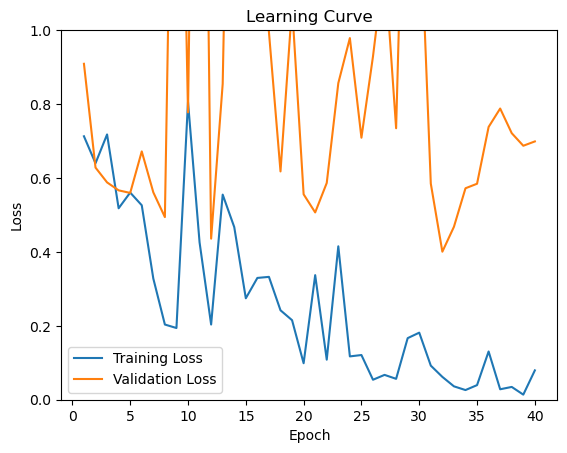

Fold 2
Accuracy Train: 0.8835714334355934. Accuracy valid: 0.8725000027567148
Recall Train: 0.8515475988388062. Recall valid: 0.9291666746139526
Precision Train: 0.8500595092773438. Precision valid: 0.8318750262260437
Best Valid Accuracy Epoc: 6. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 0. Value = 1.0 Acc val = 0.42500001192092896


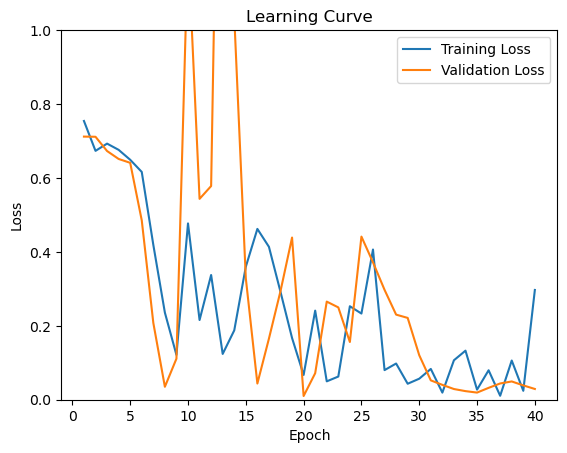

Fold 3
Accuracy Train: 0.9042857186070512. Accuracy valid: 0.7925000011920929
Recall Train: 0.8567856550216675. Recall valid: 0.6791666746139526
Precision Train: 0.8976190686225891. Precision valid: 0.825
Best Valid Accuracy Epoc: 8. Value = 0.875 Recall val = 0.8333333730697632
Best Valid Recall Epoc: 8. Value = 0.8333333730697632 Acc val = 0.875


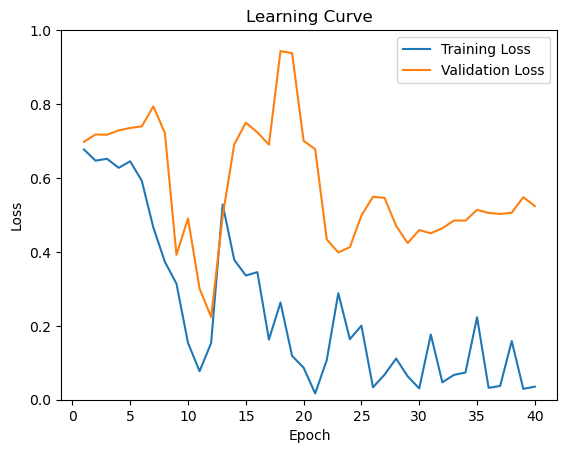

Fold 4
Accuracy Train: 0.892142861123596. Accuracy valid: 0.7843750040978194
Recall Train: 0.8440476655960083. Recall valid: 0.7041667103767395
Precision Train: 0.8803571462631226. Precision valid: 0.6483333706855774
Best Valid Accuracy Epoc: 23. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 9. Value = 1.0 Acc val = 0.875


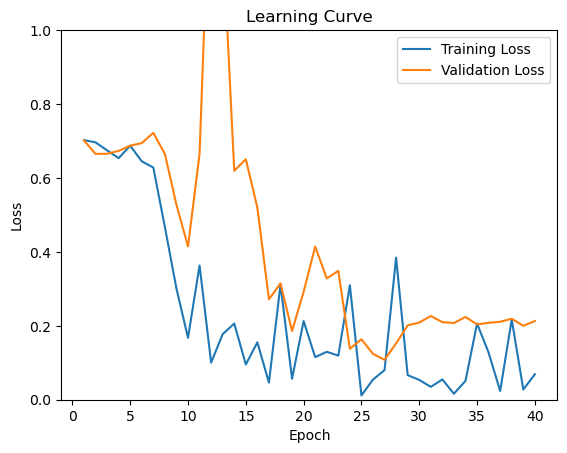

Fold 5
Accuracy Train: 0.8518750036135316. Accuracy valid: 0.7958333425223827
Recall Train: 0.7647916674613953. Recall valid: 0.65625
Precision Train: 0.7875000238418579. Precision valid: 0.8375
Best Valid Accuracy Epoc: 11. Value = 1.0 Recall val = 1.0
Best Valid Recall Epoc: 11. Value = 1.0 Acc val = 1.0


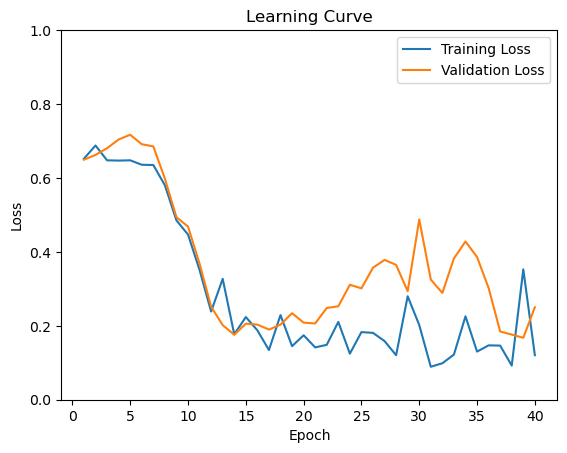

5
Fold 0: Training Loss: 0.2629131215624511, Validation Loss: 0.9352117773611098
Fold 1: Training Loss: 0.25879967110231517, Validation Loss: 0.3515682848308643
Fold 2: Training Loss: 0.23902988918125628, Validation Loss: 0.5761219102831092
Fold 3: Training Loss: 0.23752295221202074, Validation Loss: 0.425747191067785
Fold 4: Training Loss: 0.2882187582552433, Validation Loss: 0.36711708195507525
TRAIN LOSS MEDIA: 0.25729687846265736 VALID LOSS MEDIA: 0.5311532490995887
TRAIN ACC MEDIA: 0.8832321471667717 VALID ACC MEDIA: 0.8001666711270807
TRAIN RECALL MEDIA: 0.835136890411377 VALID RECALL MEDIA: 0.7174999713897705
TRAIN PRECISION MEDIA: 0.8575595021247864 VALID PRECISION MEDIA: 0.7932916805148124


In [ ]:
prueba_k_fold_resnet_pre_oc_impr(df_mosaic, 5, 5, 35, optim.RMSprop, 5, 0.0001, True, None)